#HomeObjects-3K

In [ ]:
# ============================================================
# 1. CONFIGURAÇÃO DO AMBIENTE
# ============================================================

!pip install -q ultralytics

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from ultralytics.data.utils import check_det_dataset

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


In [ ]:
# Verificação do ambiente de execução

import torch

print("PyTorch:", torch.__version__)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU não disponível.")

PyTorch: 2.11.0+cpu
CUDA disponível: False
GPU não disponível.


In [ ]:
# ============================================================
# 2. CARREGAMENTO DO DATASET
# ============================================================

data = check_det_dataset("HomeObjects-3K.yaml")

print("Dataset carregado com sucesso!")
print()
print("Diretório principal:")
print(data["path"])

print()
print("Treinamento:")
print(data["train"])

print()
print("Validação:")
print(data["val"])


WARNING ⚠️ Dataset 'HomeObjects-3K.yaml' images not found, missing path '/content/datasets/homeobjects-3K/images/val'
Unzipping /content/datasets/homeobjects-3K.zip to /content/datasets/homeobjects-3K...: 100% ━━━━━━━━━━━━ 5386/5386 803.1files/s 6.7s
Dataset download success ✅ (12.2s), saved to /content/datasets

Dataset carregado com sucesso!

Diretório principal:
/content/datasets/homeobjects-3K

Treinamento:
/content/datasets/homeobjects-3K/images/train

Validação:
/content/datasets/homeobjects-3K/images/val


In [ ]:
# Caminhos das imagens e labels

dataset_path = Path(data["path"])

train_images = dataset_path / data["train"]
val_images = dataset_path / data["val"]

print("Train:")
print(train_images)

print("\nVal:")
print(val_images)

Train:
/content/datasets/homeobjects-3K/images/train

Val:
/content/datasets/homeobjects-3K/images/val


In [ ]:
# ============================================================
# 3. VISÃO GERAL DO DATASET
# ============================================================

train_image_files = [
    p for p in train_images.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

val_image_files = [
    p for p in val_images.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("=" * 50)
print("QUANTIDADE DE IMAGENS")
print("=" * 50)

print(f"Imagens de treino:    {len(train_image_files)}")
print(f"Imagens de validação: {len(val_image_files)}")
print(f"Total:                {len(train_image_files) + len(val_image_files)}")

QUANTIDADE DE IMAGENS
Imagens de treino:    2285
Imagens de validação: 404
Total:                2689


In [ ]:
# ============================================================
# 3.1 CLASSES
# ============================================================

class_names = data["names"]

print("=" * 50)
print("CLASSES DO DATASET")
print("=" * 50)

for class_id, class_name in class_names.items():
    print(f"{class_id:2d} -> {class_name}")

print()
print(f"Total de classes: {len(class_names)}")

CLASSES DO DATASET
 0 -> bed
 1 -> sofa
 2 -> chair
 3 -> table
 4 -> lamp
 5 -> tv
 6 -> laptop
 7 -> wardrobe
 8 -> window
 9 -> door
10 -> potted plant
11 -> photo frame

Total de classes: 12


In [ ]:
# ============================================================
# 4. DISTRIBUIÇÃO DAS CLASSES
# ============================================================

def count_classes(label_dir, class_names):
    counts = {class_id: 0 for class_id in class_names}

    label_files = list(label_dir.rglob("*.txt"))

    for label_file in label_files:
        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) >= 5:
                    class_id = int(parts[0])

                    if class_id in counts:
                        counts[class_id] += 1

    return counts

In [ ]:
# Localização dos diretórios de labels

train_labels = dataset_path / "labels" / "train"
val_labels = dataset_path / "labels" / "val"

print("Train labels:")
print(train_labels)

print("\nVal labels:")
print(val_labels)

Train labels:
/content/datasets/homeobjects-3K/labels/train

Val labels:
/content/datasets/homeobjects-3K/labels/val


In [ ]:
# Contagem de objetos

train_counts = count_classes(train_labels, class_names)
val_counts = count_classes(val_labels, class_names)

distribution = pd.DataFrame({
    "Classe ID": list(class_names.keys()),
    "Classe": list(class_names.values()),
    "Treino": [train_counts[i] for i in class_names],
    "Validação": [val_counts[i] for i in class_names]
})

distribution["Total"] = (
    distribution["Treino"] +
    distribution["Validação"]
)

distribution["%"] = (
    distribution["Total"] /
    distribution["Total"].sum() * 100
)

distribution = distribution.sort_values(
    "Total",
    ascending=False
).reset_index(drop=True)

distribution

,Classe ID,Classe,Treino,Validação,Total,%
0,10,potted plant,4249,788,5037,22.595550
1,11,photo frame,2715,561,3276,14.695855
2,3,table,2561,469,3030,13.592320
3,2,chair,2208,305,2513,11.273102
4,1,sofa,2074,398,2472,11.089180
5,4,lamp,1818,304,2122,9.519110
6,8,window,1636,371,2007,9.003230
7,9,door,509,85,594,2.664633
8,7,wardrobe,468,109,577,2.588373
9,5,tv,332,54,386,1.731563


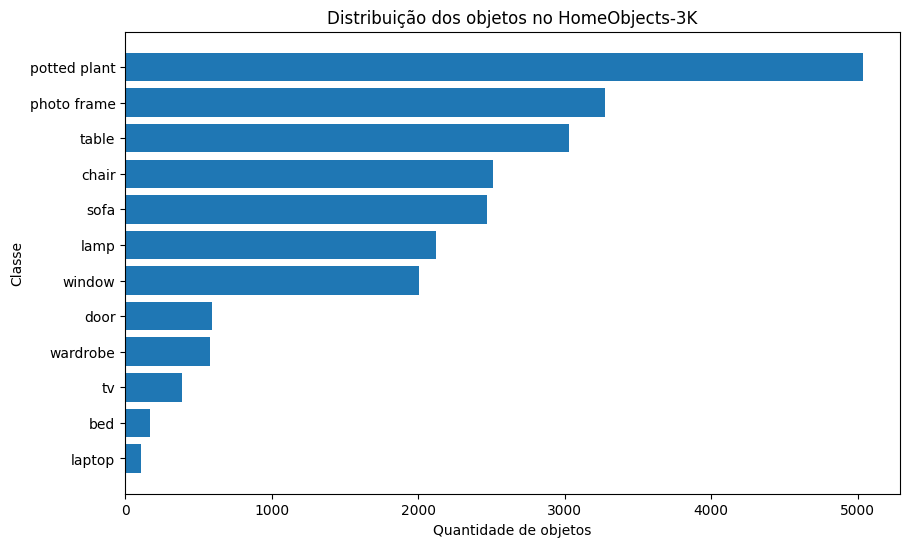

In [ ]:
# ============================================================
# 4.1 GRÁFICO DE DISTRIBUIÇÃO
# ============================================================

plt.figure(figsize=(10, 6))

plt.barh(
    distribution["Classe"],
    distribution["Total"]
)

plt.xlabel("Quantidade de objetos")
plt.ylabel("Classe")
plt.title("Distribuição dos objetos no HomeObjects-3K")

plt.gca().invert_yaxis()

plt.show()

In [ ]:
# ============================================================
# 4.2 DISTRIBUIÇÃO DAS CLASSES DE INTERESSE
# ============================================================

obstacle_classes = [
    "bed",
    "sofa",
    "chair",
    "table",
    "wardrobe",
    "door",
    "potted plant"
]

obstacle_distribution = distribution[
    distribution["Classe"].isin(obstacle_classes)
].copy()

obstacle_distribution = obstacle_distribution.sort_values(
    "Total",
    ascending=False
).reset_index(drop=True)

obstacle_distribution

,Classe ID,Classe,Treino,Validação,Total,%
0,10,potted plant,4249,788,5037,22.595550
1,3,table,2561,469,3030,13.592320
2,2,chair,2208,305,2513,11.273102
3,1,sofa,2074,398,2472,11.089180
4,9,door,509,85,594,2.664633
5,7,wardrobe,468,109,577,2.588373
6,0,bed,150,22,172,0.771577


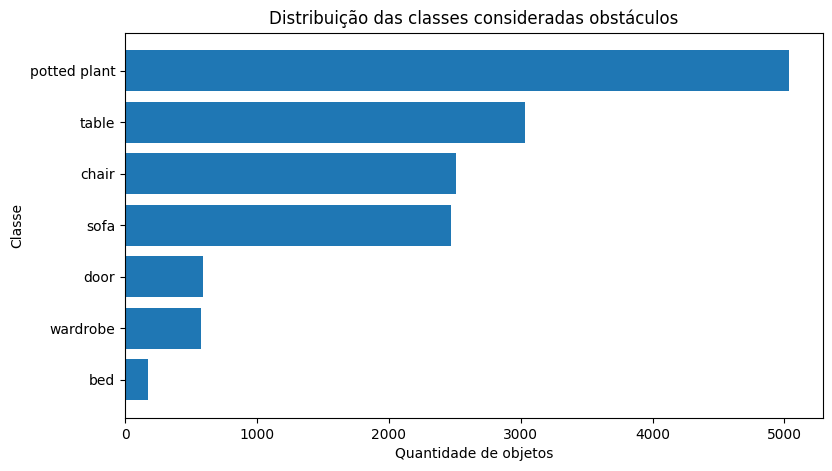

In [ ]:
plt.figure(figsize=(9, 5))

plt.barh(
    obstacle_distribution["Classe"],
    obstacle_distribution["Total"]
)

plt.xlabel("Quantidade de objetos")
plt.ylabel("Classe")
plt.title("Distribuição das classes consideradas obstáculos")

plt.gca().invert_yaxis()

plt.show()

In [ ]:
# ============================================================
# 5. QUANTIDADE DE OBJETOS POR IMAGEM
# ============================================================

def objects_per_image(label_dir):
    """
    Retorna a quantidade de objetos anotados em cada imagem.
    """

    counts = []

    label_files = list(label_dir.rglob("*.txt"))

    for label_file in label_files:
        with open(label_file, "r") as f:
            lines = [
                line.strip()
                for line in f
                if line.strip()
            ]

        counts.append({
            "imagem": label_file.stem,
            "objetos": len(lines)
        })

    return pd.DataFrame(counts)


train_objects = objects_per_image(train_labels)
val_objects = objects_per_image(val_labels)

print("Quantidade de imagens analisadas:")
print(f"Treino: {len(train_objects)}")
print(f"Validação: {len(val_objects)}")

Quantidade de imagens analisadas:
Treino: 2285
Validação: 404


In [ ]:
# ============================================================
# 5.1 ESTATÍSTICAS - TREINO
# ============================================================

print("=" * 50)
print("OBJETOS POR IMAGEM - TREINO")
print("=" * 50)

print(f"Média:    {train_objects['objetos'].mean():.2f}")
print(f"Mediana:  {train_objects['objetos'].median():.2f}")
print(f"Mínimo:   {train_objects['objetos'].min()}")
print(f"Máximo:   {train_objects['objetos'].max()}")

OBJETOS POR IMAGEM - TREINO
Média:    8.24
Mediana:  7.00
Mínimo:   1
Máximo:   50


In [ ]:
# ============================================================
# 5.2 ESTATÍSTICAS - VALIDAÇÃO
# ============================================================

print("=" * 50)
print("OBJETOS POR IMAGEM - VALIDAÇÃO")
print("=" * 50)

print(f"Média:    {val_objects['objetos'].mean():.2f}")
print(f"Mediana:  {val_objects['objetos'].median():.2f}")
print(f"Mínimo:   {val_objects['objetos'].min()}")
print(f"Máximo:   {val_objects['objetos'].max()}")

OBJETOS POR IMAGEM - VALIDAÇÃO
Média:    8.59
Mediana:  7.00
Mínimo:   1
Máximo:   31


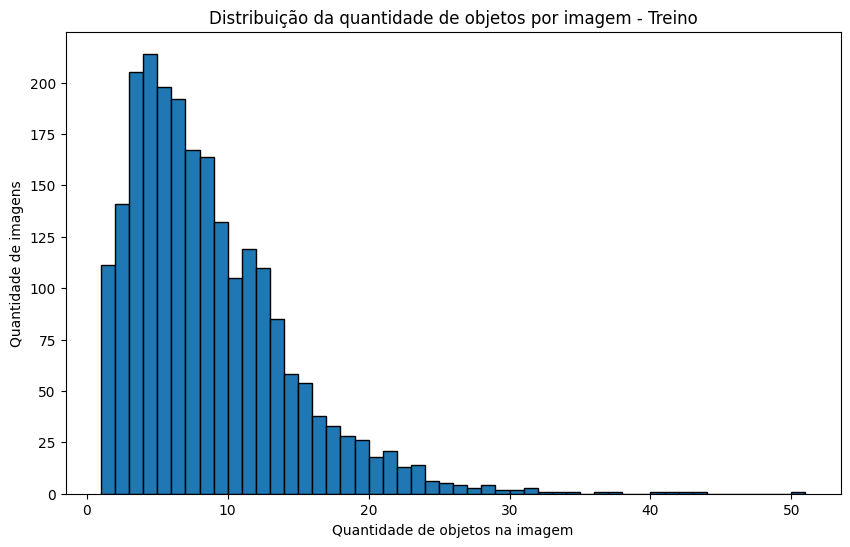

In [ ]:
# ============================================================
# 5.3 DISTRIBUIÇÃO DE OBJETOS POR IMAGEM
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    train_objects["objetos"],
    bins=range(
        train_objects["objetos"].min(),
        train_objects["objetos"].max() + 2
    ),
    edgecolor="black"
)

plt.xlabel("Quantidade de objetos na imagem")
plt.ylabel("Quantidade de imagens")
plt.title("Distribuição da quantidade de objetos por imagem - Treino")

plt.show()

In [ ]:
# ============================================================
# 5.4 IMAGENS COM MAIOR QUANTIDADE DE OBJETOS
# ============================================================

train_objects.sort_values(
    "objetos",
    ascending=False
).head(15)

,imagem,objetos
2112,living_room_1500,50
828,living_room_1944,43
2262,living_room_998,42
1933,living_room_1104,41
1806,living_room_493,40
2137,living_room_1158,37
861,living_room_1237,36
2035,living_room_1764,34
268,living_room_1821,33
512,living_room_1483,32


In [ ]:
# ============================================================
# 5.5 FAIXAS DE QUANTIDADE DE OBJETOS
# ============================================================

def categorize_objects(n):
    if n <= 3:
        return "1–3 objetos"
    elif n <= 6:
        return "4–6 objetos"
    elif n <= 10:
        return "7–10 objetos"
    elif n <= 20:
        return "11–20 objetos"
    else:
        return "Mais de 20 objetos"


train_objects["faixa"] = train_objects["objetos"].apply(
    categorize_objects
)

faixas = [
    "1–3 objetos",
    "4–6 objetos",
    "7–10 objetos",
    "11–20 objetos",
    "Mais de 20 objetos"
]

distribution_objects = (
    train_objects["faixa"]
    .value_counts()
    .reindex(faixas)
    .fillna(0)
)

distribution_objects

,count
faixa,
1–3 objetos,457
4–6 objetos,604
7–10 objetos,568
11–20 objetos,569
Mais de 20 objetos,87


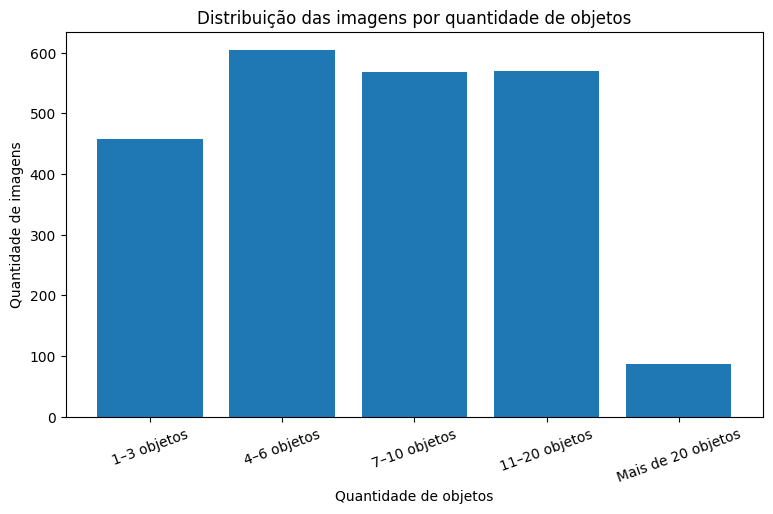

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    distribution_objects.index,
    distribution_objects.values
)

plt.xlabel("Quantidade de objetos")
plt.ylabel("Quantidade de imagens")
plt.title("Distribuição das imagens por quantidade de objetos")

plt.xticks(rotation=20)

plt.show()

In [ ]:
# ============================================================
# 5.6 OBJETOS DE INTERESSE POR IMAGEM
# ============================================================

obstacle_class_ids = {
    class_id
    for class_id, class_name in class_names.items()
    if class_name in obstacle_classes
}

print("Classes consideradas:")
for class_id in sorted(obstacle_class_ids):
    print(f"{class_id} -> {class_names[class_id]}")

Classes consideradas:
0 -> bed
1 -> sofa
2 -> chair
3 -> table
7 -> wardrobe
9 -> door
10 -> potted plant


In [ ]:
# ============================================================
# 5.7 CONTAGEM DE OBSTÁCULOS POR IMAGEM
# ============================================================

def obstacle_objects_per_image(label_dir, obstacle_class_ids):
    """
    Conta somente os objetos pertencentes às classes
    consideradas relevantes para obstáculos.
    """

    results = []

    label_files = list(label_dir.rglob("*.txt"))

    for label_file in label_files:

        total_objects = 0
        obstacle_objects = 0

        with open(label_file, "r") as f:

            for line in f:
                parts = line.strip().split()

                if len(parts) >= 5:

                    class_id = int(parts[0])

                    total_objects += 1

                    if class_id in obstacle_class_ids:
                        obstacle_objects += 1

        results.append({
            "imagem": label_file.stem,
            "total_objetos": total_objects,
            "obstaculos": obstacle_objects
        })

    return pd.DataFrame(results)


train_obstacles = obstacle_objects_per_image(
    train_labels,
    obstacle_class_ids
)

train_obstacles.head()

,imagem,total_objetos,obstaculos
0,s (223),1,1
1,living_room_1p (554),2,2
2,living_room_1p (467),5,4
3,s (260),2,1
4,living_room_697,8,3


In [ ]:
# ============================================================
# 5.8 ESTATÍSTICAS DOS OBSTÁCULOS POR IMAGEM
# ============================================================

print("=" * 60)
print("OBSTÁCULOS POR IMAGEM - TREINO")
print("=" * 60)

print(
    f"Média:   {train_obstacles['obstaculos'].mean():.2f}"
)

print(
    f"Mediana: {train_obstacles['obstaculos'].median():.2f}"
)

print(
    f"Mínimo:  {train_obstacles['obstaculos'].min()}"
)

print(
    f"Máximo:  {train_obstacles['obstaculos'].max()}"
)

OBSTÁCULOS POR IMAGEM - TREINO
Média:   5.35
Mediana: 4.00
Mínimo:  0
Máximo:  48


In [ ]:
# ============================================================
# 5.8 ESTATÍSTICAS DOS OBSTÁCULOS POR IMAGEM
# ============================================================

print("=" * 60)
print("OBSTÁCULOS POR IMAGEM - TREINO")
print("=" * 60)

print(
    f"Média:   {train_obstacles['obstaculos'].mean():.2f}"
)

print(
    f"Mediana: {train_obstacles['obstaculos'].median():.2f}"
)

print(
    f"Mínimo:  {train_obstacles['obstaculos'].min()}"
)

print(
    f"Máximo:  {train_obstacles['obstaculos'].max()}"
)

OBSTÁCULOS POR IMAGEM - TREINO
Média:   5.35
Mediana: 4.00
Mínimo:  0
Máximo:  48


In [ ]:
# ============================================================
# 6. VISUALIZAÇÃO DAS IMAGENS COM MAIS OBSTÁCULOS
# ============================================================

top_obstacles = train_obstacles.sort_values(
    "obstaculos",
    ascending=False
).head(10)

top_obstacles

,imagem,total_objetos,obstaculos
2112,living_room_1500,50,48
2262,living_room_998,42,42
828,living_room_1944,43,39
1933,living_room_1104,41,32
512,living_room_1483,32,31
35,living_room_669,30,29
1626,living_room_1409,31,29
268,living_room_1821,33,27
2035,living_room_1764,34,25
861,living_room_1237,36,24


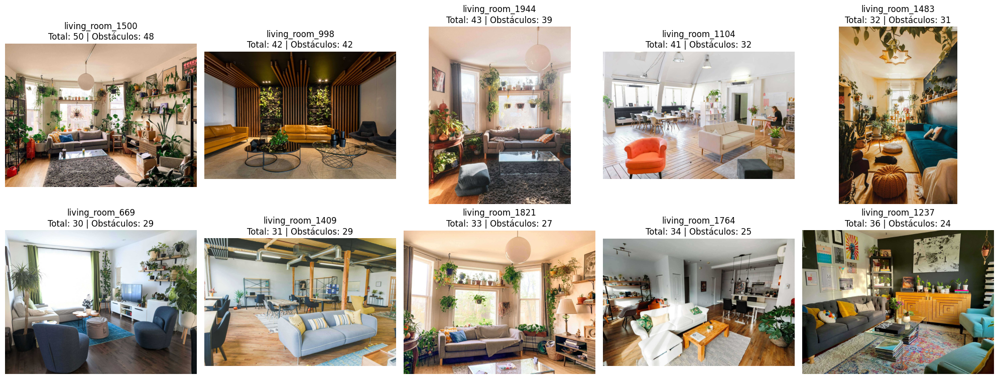

In [ ]:
# ============================================================
# 6.1 EXIBIR AS IMAGENS
# ============================================================

fig, axes = plt.subplots(
    2, 5,
    figsize=(20, 8)
)

for ax, (_, row) in zip(axes.flat, top_obstacles.iterrows()):

    image_name = row["imagem"]

    # Procurar a imagem correspondente
    matches = list(train_images.rglob(image_name + ".*"))

    if matches:

        image = Image.open(matches[0])

        ax.imshow(image)
        ax.set_title(
            f"{image_name}\n"
            f"Total: {row['total_objetos']} | "
            f"Obstáculos: {row['obstaculos']}"
        )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 6. VALIDAÇÃO DAS ANOTAÇÕES
# ============================================================

def validate_labels(label_dir, class_names):

    results = {
        "arquivos_labels": 0,
        "labels_vazios": 0,
        "linhas_invalidas": 0,
        "classes_invalidas": 0,
        "coordenadas_invalidas": 0,
        "tamanho_invalido": 0
    }

    problemas = []

    label_files = list(label_dir.rglob("*.txt"))

    results["arquivos_labels"] = len(label_files)

    for label_file in label_files:

        with open(label_file, "r") as f:
            lines = [line.strip() for line in f if line.strip()]

        # Label vazio
        if len(lines) == 0:
            results["labels_vazios"] += 1

            problemas.append({
                "arquivo": label_file.name,
                "problema": "Label vazio"
            })

            continue

        for line_number, line in enumerate(lines, start=1):

            parts = line.split()

            # Formato deveria possuir 5 valores
            if len(parts) != 5:

                results["linhas_invalidas"] += 1

                problemas.append({
                    "arquivo": label_file.name,
                    "linha": line_number,
                    "problema": f"Formato inválido: {len(parts)} valores"
                })

                continue

            try:
                class_id = int(parts[0])
                x_center = float(parts[1])
                y_center = float(parts[2])
                width = float(parts[3])
                height = float(parts[4])

            except ValueError:

                results["linhas_invalidas"] += 1

                problemas.append({
                    "arquivo": label_file.name,
                    "linha": line_number,
                    "problema": "Valores não numéricos"
                })

                continue

            # Classe inexistente
            if class_id not in class_names:

                results["classes_invalidas"] += 1

                problemas.append({
                    "arquivo": label_file.name,
                    "linha": line_number,
                    "problema": f"Classe inválida: {class_id}"
                })

            # Coordenadas devem estar entre 0 e 1
            if not (
                0 <= x_center <= 1 and
                0 <= y_center <= 1
            ):

                results["coordenadas_invalidas"] += 1

                problemas.append({
                    "arquivo": label_file.name,
                    "linha": line_number,
                    "problema": "Centro da bounding box fora de [0,1]"
                })

            # Largura e altura devem ser > 0
            if width <= 0 or height <= 0:

                results["tamanho_invalido"] += 1

                problemas.append({
                    "arquivo": label_file.name,
                    "linha": line_number,
                    "problema": "Largura ou altura inválida"
                })

    return results, pd.DataFrame(problemas)

In [ ]:
# ============================================================
# 6.1 VALIDAÇÃO - TREINO
# ============================================================

train_validation, train_problems = validate_labels(
    train_labels,
    class_names
)

print("=" * 60)
print("VALIDAÇÃO DAS ANOTAÇÕES - TREINO")
print("=" * 60)

for key, value in train_validation.items():
    print(f"{key}: {value}")

VALIDAÇÃO DAS ANOTAÇÕES - TREINO
arquivos_labels: 2285
labels_vazios: 0
linhas_invalidas: 0
classes_invalidas: 0
coordenadas_invalidas: 0
tamanho_invalido: 0


In [ ]:
# ============================================================
# 6.2 VALIDAÇÃO - VALIDAÇÃO
# ============================================================

val_validation, val_problems = validate_labels(
    val_labels,
    class_names
)

print("=" * 60)
print("VALIDAÇÃO DAS ANOTAÇÕES - VALIDAÇÃO")
print("=" * 60)

for key, value in val_validation.items():
    print(f"{key}: {value}")

VALIDAÇÃO DAS ANOTAÇÕES - VALIDAÇÃO
arquivos_labels: 404
labels_vazios: 0
linhas_invalidas: 0
classes_invalidas: 0
coordenadas_invalidas: 0
tamanho_invalido: 0


In [ ]:
# ============================================================
# 6.3 RESUMO DA VALIDAÇÃO
# ============================================================

validation_summary = pd.DataFrame({
    "Treino": train_validation,
    "Validação": val_validation
})

validation_summary

,Treino,Validação
arquivos_labels,2285,404
labels_vazios,0,0
linhas_invalidas,0,0
classes_invalidas,0,0
coordenadas_invalidas,0,0
tamanho_invalido,0,0


In [ ]:
# ============================================================
# 7. IMAGENS X ANOTAÇÕES
# ============================================================

def compare_images_labels(image_files, label_dir):

    image_stems = {img.stem for img in image_files}
    label_stems = {
        label.stem
        for label in label_dir.rglob("*.txt")
    }

    images_without_labels = image_stems - label_stems
    labels_without_images = label_stems - image_stems

    return images_without_labels, labels_without_images


train_images_without_labels, train_labels_without_images = (
    compare_images_labels(train_image_files, train_labels)
)

val_images_without_labels, val_labels_without_images = (
    compare_images_labels(val_image_files, val_labels)
)

print("=" * 60)
print("IMAGENS X LABELS")
print("=" * 60)

print("\nTREINO")
print(f"Imagens sem label: {len(train_images_without_labels)}")
print(f"Labels sem imagem: {len(train_labels_without_images)}")

print("\nVALIDAÇÃO")
print(f"Imagens sem label: {len(val_images_without_labels)}")
print(f"Labels sem imagem: {len(val_labels_without_images)}")

IMAGENS X LABELS

TREINO
Imagens sem label: 0
Labels sem imagem: 0

VALIDAÇÃO
Imagens sem label: 0
Labels sem imagem: 0


In [ ]:
# ============================================================
# 7. INSPEÇÃO VISUAL DAS ANOTAÇÕES
# ============================================================

import random

random.seed(42)

# Selecionar 12 imagens aleatórias
sample_images = random.sample(
    train_image_files,
    min(12, len(train_image_files))
)

for image in sample_images:
    print(image.name)

living_room_646.jpg
living_room_138.jpg
living_room_541.jpg
s (323).jpg
living_room_1p (33).jpg
living_room_695.jpg
living_room_1p (311).jpg
living_room_1649.jpg
living_room_1p (183).jpg
s (138).jpg
living_room_1p (405).jpg
living_room_1p (585).jpg


In [ ]:
# ============================================================
# 7.1 FUNÇÃO PARA VISUALIZAR BOUNDING BOXES
# ============================================================

def show_image_with_boxes(image_path, label_dir, class_names):

    image = Image.open(image_path).convert("RGB")

    fig, ax = plt.subplots(figsize=(10, 7))

    ax.imshow(image)

    label_path = label_dir / f"{image_path.stem}.txt"

    if label_path.exists():

        with open(label_path, "r") as f:
            lines = [
                line.strip()
                for line in f
                if line.strip()
            ]

        image_width, image_height = image.size

        for line in lines:

            parts = line.split()

            class_id = int(parts[0])
            x_center = float(parts[1])
            y_center = float(parts[2])
            width = float(parts[3])
            height = float(parts[4])

            # Converter coordenadas YOLO para pixels
            box_width = width * image_width
            box_height = height * image_height

            x = (x_center * image_width) - box_width / 2
            y = (y_center * image_height) - box_height / 2

            rectangle = plt.Rectangle(
                (x, y),
                box_width,
                box_height,
                fill=False,
                linewidth=2
            )

            ax.add_patch(rectangle)

            ax.text(
                x,
                y,
                class_names[class_id],
                fontsize=9,
                backgroundcolor="white"
            )

    ax.set_title(image_path.name)
    ax.axis("off")

    plt.show()

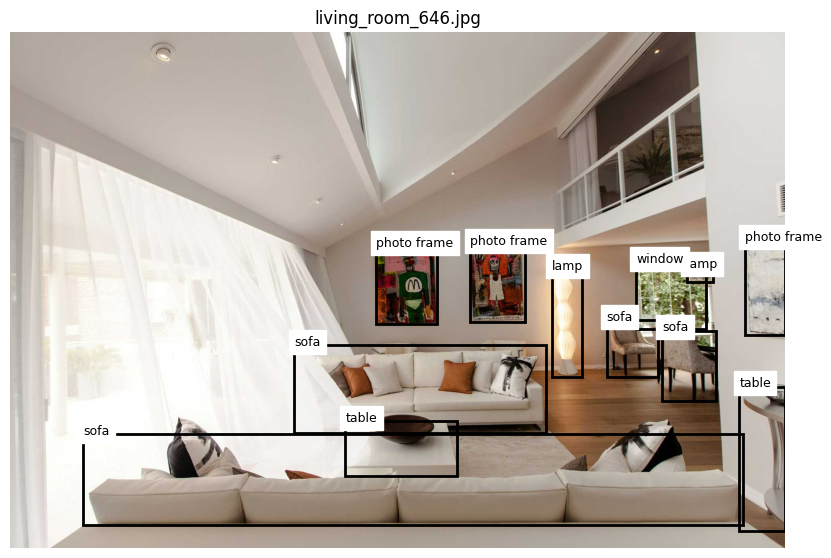

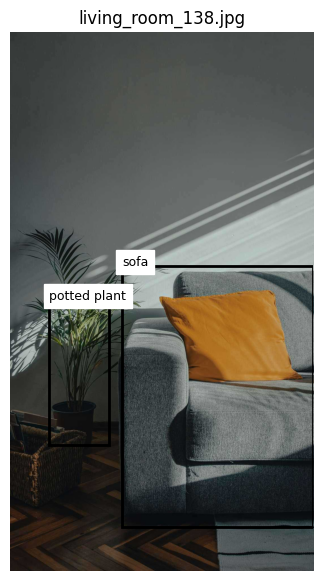

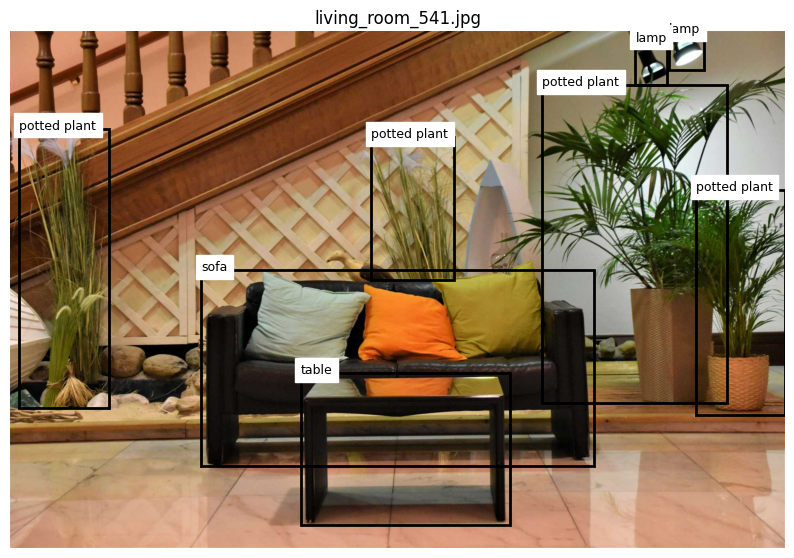

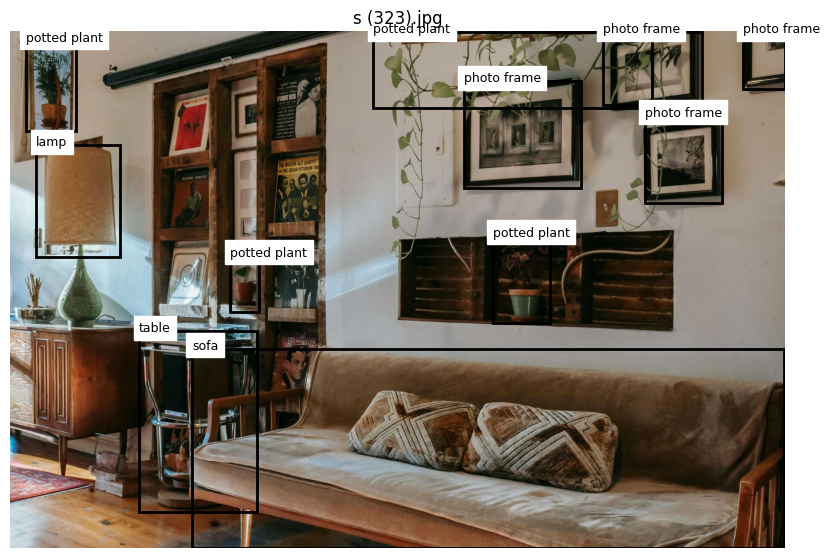

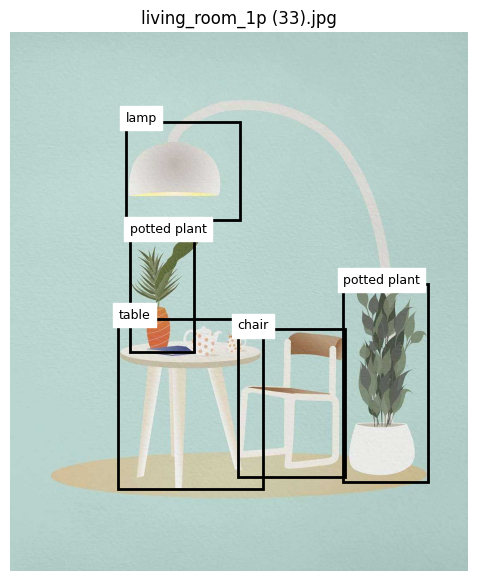

...

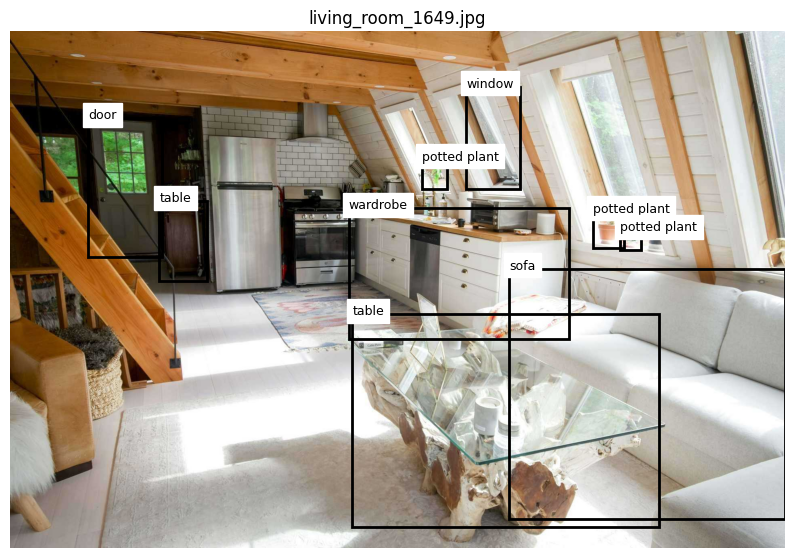

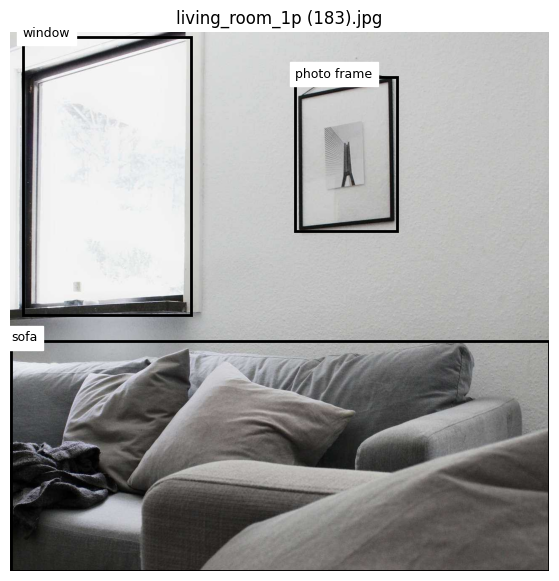

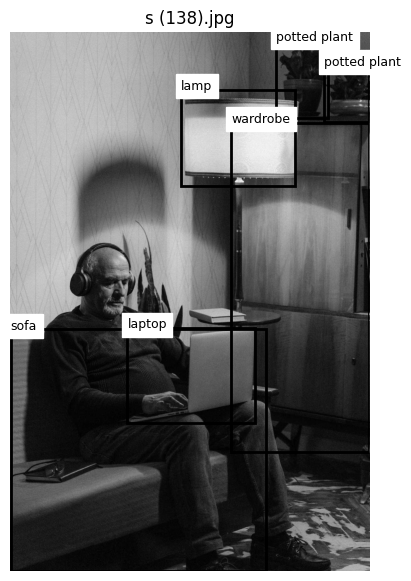

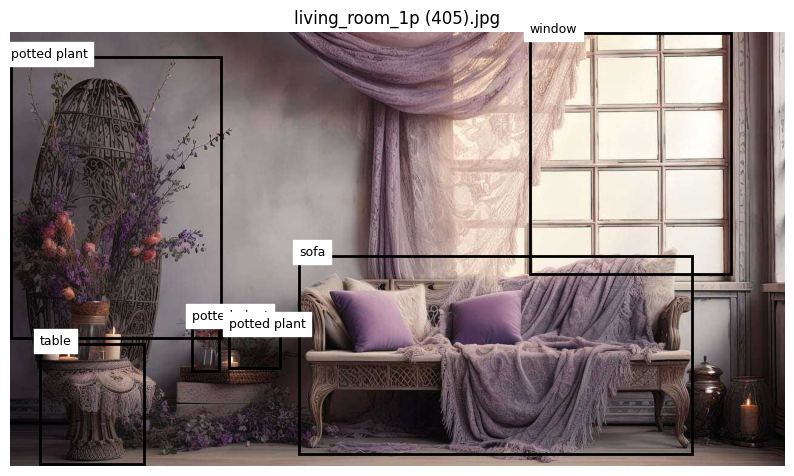

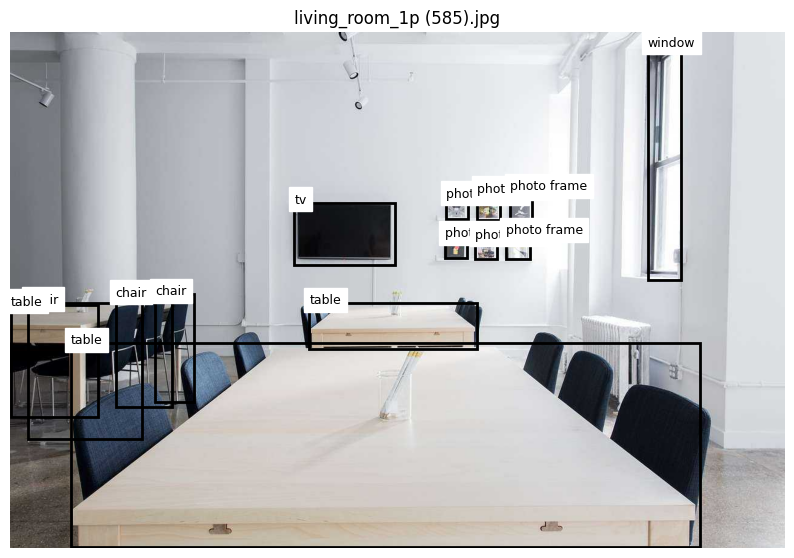

In [ ]:
# ============================================================
# 7.2 VISUALIZAÇÃO DAS ANOTAÇÕES
# ============================================================

for image_path in sample_images:

    show_image_with_boxes(
        image_path,
        train_labels,
        class_names
    )

In [ ]:
# ============================================================
# 8. ANÁLISE DO TAMANHO DAS BOUNDING BOXES
# ============================================================

def extract_bounding_boxes(label_dir, class_names):

    boxes = []

    label_files = list(label_dir.rglob("*.txt"))

    for label_file in label_files:

        with open(label_file, "r") as f:

            for line in f:

                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                class_id = int(parts[0])
                x_center = float(parts[1])
                y_center = float(parts[2])
                width = float(parts[3])
                height = float(parts[4])

                area = width * height

                boxes.append({
                    "imagem": label_file.stem,
                    "classe_id": class_id,
                    "classe": class_names[class_id],
                    "x_centro": x_center,
                    "y_centro": y_center,
                    "largura": width,
                    "altura": height,
                    "area": area
                })

    return pd.DataFrame(boxes)


train_boxes = extract_bounding_boxes(
    train_labels,
    class_names
)

print(f"Total de bounding boxes analisadas: {len(train_boxes)}")

Total de bounding boxes analisadas: 18822


In [ ]:
# ============================================================
# 8.1 ESTATÍSTICAS DAS BOUNDING BOXES
# ============================================================

print("=" * 60)
print("TAMANHO DAS BOUNDING BOXES - TREINO")
print("=" * 60)

print(f"Área média:    {train_boxes['area'].mean():.4f}")
print(f"Área mediana:  {train_boxes['area'].median():.4f}")
print(f"Área mínima:   {train_boxes['area'].min():.6f}")
print(f"Área máxima:   {train_boxes['area'].max():.4f}")

TAMANHO DAS BOUNDING BOXES - TREINO
Área média:    0.0547
Área mediana:  0.0244
Área mínima:   0.000048
Área máxima:   0.9707


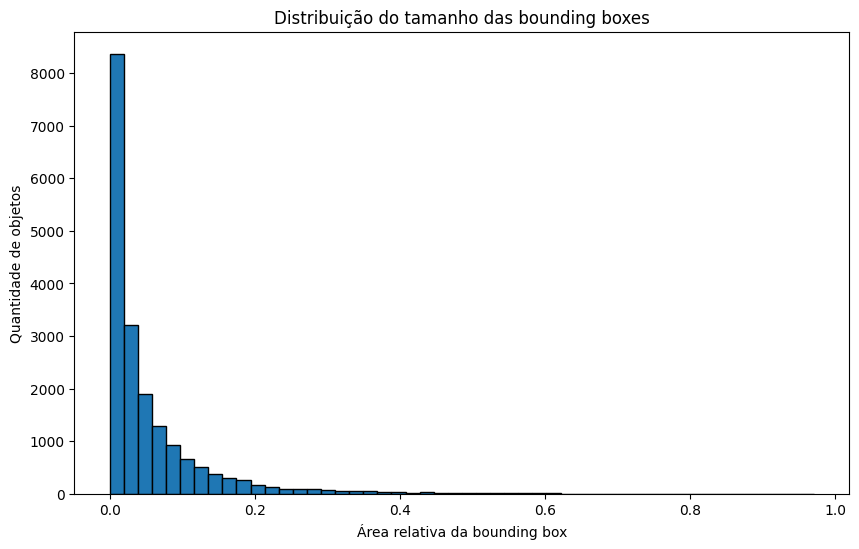

In [ ]:
# ============================================================
# 8.2 DISTRIBUIÇÃO DA ÁREA DAS BOUNDING BOXES
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    train_boxes["area"],
    bins=50,
    edgecolor="black"
)

plt.xlabel("Área relativa da bounding box")
plt.ylabel("Quantidade de objetos")
plt.title("Distribuição do tamanho das bounding boxes")

plt.show()

In [ ]:
# ============================================================
# 8.3 CLASSIFICAÇÃO POR TAMANHO
# ============================================================

def classify_box_size(area):

    if area < 0.05:
        return "Pequena"

    elif area < 0.20:
        return "Média"

    else:
        return "Grande"


train_boxes["tamanho"] = train_boxes["area"].apply(
    classify_box_size
)

size_distribution = (
    train_boxes["tamanho"]
    .value_counts()
    .reindex(["Pequena", "Média", "Grande"])
    .fillna(0)
)

size_distribution

,count
tamanho,
Pequena,12742
Média,5060
Grande,1020


In [ ]:
# ============================================================
# 8.4 PERCENTUAL POR TAMANHO
# ============================================================

size_percentage = (
    size_distribution /
    size_distribution.sum() * 100
)

pd.DataFrame({
    "Quantidade": size_distribution,
    "Percentual (%)": size_percentage.round(2)
})

,Quantidade,Percentual (%)
tamanho,,
Pequena,12742,67.70
Média,5060,26.88
Grande,1020,5.42


In [ ]:
# ============================================================
# 8.5 TAMANHO DOS POSSÍVEIS OBSTÁCULOS
# ============================================================

obstacle_boxes = train_boxes[
    train_boxes["classe"].isin(obstacle_classes)
].copy()

obstacle_size_summary = (
    obstacle_boxes
    .groupby("classe")["area"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
    .sort_values("count", ascending=False)
)

obstacle_size_summary

,count,mean,median,min,max
classe,,,,,
potted plant,4249,0.033073,0.011719,0.000179,0.750209
table,2561,0.072345,0.048053,0.000693,0.854683
chair,2208,0.056409,0.039157,0.000751,0.695475
sofa,2074,0.146196,0.117010,0.003007,0.970668
door,509,0.046482,0.028509,0.001269,0.336720
wardrobe,468,0.105059,0.068851,0.001395,0.850064
bed,150,0.267685,0.253921,0.008944,0.755050


In [ ]:
# ============================================================
# 9. POSIÇÃO DOS OBJETOS NA IMAGEM
# ============================================================

# Classificação da posição vertical
def vertical_position(y):

    if y < 1/3:
        return "Superior"

    elif y < 2/3:
        return "Central"

    else:
        return "Inferior"


# Classificação da posição horizontal
def horizontal_position(x):

    if x < 1/3:
        return "Esquerda"

    elif x < 2/3:
        return "Centro"

    else:
        return "Direita"


train_boxes["posicao_vertical"] = train_boxes[
    "y_centro"
].apply(vertical_position)

train_boxes["posicao_horizontal"] = train_boxes[
    "x_centro"
].apply(horizontal_position)


print("Distribuição vertical:")
print(
    train_boxes["posicao_vertical"]
    .value_counts()
)


print("\nDistribuição horizontal:")
print(
    train_boxes["posicao_horizontal"]
    .value_counts()
)

Distribuição vertical:
posicao_vertical
Central     10401
Inferior     5395
Superior     3026
Name: count, dtype: int64

Distribuição horizontal:
posicao_horizontal
Centro      8066
Direita     5414
Esquerda    5342
Name: count, dtype: int64


In [ ]:
# ============================================================
# 9.1 POSIÇÃO DOS POSSÍVEIS OBSTÁCULOS
# ============================================================

obstacle_boxes = train_boxes[
    train_boxes["classe"].isin(obstacle_classes)
].copy()

vertical_obstacles = pd.crosstab(
    obstacle_boxes["classe"],
    obstacle_boxes["posicao_vertical"]
)

vertical_obstacles

posicao_vertical,Central,Inferior,Superior
classe,,,
bed,56,92,2
chair,960,1241,7
door,454,7,48
potted plant,3008,644,597
sofa,815,1250,9
table,641,1911,9
wardrobe,300,127,41


In [ ]:
# ============================================================
# 9.2 PERCENTUAL DA POSIÇÃO VERTICAL
# ============================================================

vertical_percentage = pd.crosstab(
    obstacle_boxes["classe"],
    obstacle_boxes["posicao_vertical"],
    normalize="index"
) * 100

vertical_percentage.round(2)

posicao_vertical,Central,Inferior,Superior
classe,,,
bed,37.33,61.33,1.33
chair,43.48,56.20,0.32
door,89.19,1.38,9.43
potted plant,70.79,15.16,14.05
sofa,39.30,60.27,0.43
table,25.03,74.62,0.35
wardrobe,64.10,27.14,8.76


In [ ]:
# ============================================================
# 10. COOCORRÊNCIA DAS CLASSES
# ============================================================

from itertools import combinations
from collections import Counter
import pandas as pd

# Classes do dataset
class_names = {
    0: "bed",
    1: "sofa",
    2: "chair",
    3: "table",
    4: "lamp",
    5: "tv",
    6: "laptop",
    7: "wardrobe",
    8: "window",
    9: "door",
    10: "potted plant",
    11: "photo frame"
}

# Listar arquivos de anotação
train_label_files = list(train_labels.glob("*.txt"))

print(f"Arquivos de anotação encontrados: {len(train_label_files)}")


# ------------------------------------------------------------
# Identificar quais classes aparecem em cada imagem
# ------------------------------------------------------------

classes_por_imagem = {}

for label_file in train_label_files:

    classes_presentes = set()

    with open(label_file, "r") as f:

        for line in f:

            parts = line.strip().split()

            if len(parts) >= 5:

                class_id = int(parts[0])

                if class_id in class_names:
                    classes_presentes.add(class_id)

    classes_por_imagem[label_file.stem] = classes_presentes


# ------------------------------------------------------------
# Contar pares de classes que aparecem na mesma imagem
# ------------------------------------------------------------

coocorrencias = Counter()

for classes in classes_por_imagem.values():

    for classe_a, classe_b in combinations(sorted(classes), 2):

        coocorrencias[(classe_a, classe_b)] += 1


# ------------------------------------------------------------
# Criar tabela
# ------------------------------------------------------------

coocorrencia_df = pd.DataFrame(
    [
        {
            "classe_a": class_names[classe_a],
            "classe_b": class_names[classe_b],
            "imagens_juntas": quantidade
        }
        for (classe_a, classe_b), quantidade in coocorrencias.items()
    ]
)


# Ordenar pelas combinações mais frequentes
coocorrencia_df = coocorrencia_df.sort_values(
    "imagens_juntas",
    ascending=False
).reset_index(drop=True)


print(f"Total de combinações encontradas: {len(coocorrencia_df)}")

coocorrencia_df.head(20)

Arquivos de anotação encontrados: 2285
Total de combinações encontradas: 66


,classe_a,classe_b,imagens_juntas
0,table,potted plant,1214
1,sofa,table,1196
2,sofa,potted plant,1033
3,table,lamp,874
4,chair,table,847
5,table,photo frame,845
6,sofa,lamp,799
7,potted plant,photo frame,766
8,lamp,potted plant,759
9,sofa,photo frame,745


In [ ]:
# ============================================================
# 11. COOCORRÊNCIA ENTRE POSSÍVEIS OBSTÁCULOS
# ============================================================

obstacle_classes = [
    "bed",
    "sofa",
    "chair",
    "table",
    "wardrobe",
    "door",
    "potted plant"
]

# Converter nomes para IDs
obstacle_ids = [
    class_id
    for class_id, class_name in class_names.items()
    if class_name in obstacle_classes
]


# Contar coocorrências
obstacle_coocorrencias = Counter()

for classes in classes_por_imagem.values():

    classes_obstaculos = sorted(
        classes.intersection(obstacle_ids)
    )

    for classe_a, classe_b in combinations(classes_obstaculos, 2):

        obstacle_coocorrencias[(classe_a, classe_b)] += 1


# Criar tabela
obstacle_coocorrencia_df = pd.DataFrame(
    [
        {
            "classe_a": class_names[classe_a],
            "classe_b": class_names[classe_b],
            "imagens_juntas": quantidade
        }
        for (classe_a, classe_b), quantidade
        in obstacle_coocorrencias.items()
    ]
)


obstacle_coocorrencia_df = obstacle_coocorrencia_df.sort_values(
    "imagens_juntas",
    ascending=False
).reset_index(drop=True)


print(
    f"Total de combinações entre obstáculos: "
    f"{len(obstacle_coocorrencia_df)}"
)

obstacle_coocorrencia_df.head(20)

Total de combinações entre obstáculos: 21


,classe_a,classe_b,imagens_juntas
0,table,potted plant,1214
1,sofa,table,1196
2,sofa,potted plant,1033
3,chair,table,847
4,chair,potted plant,704
5,sofa,chair,597
6,table,door,299
7,wardrobe,potted plant,293
8,table,wardrobe,290
9,sofa,wardrobe,265


In [ ]:
# Verificar as colunas disponíveis
print(train_boxes.columns.tolist())

['imagem', 'classe_id', 'classe', 'x_centro', 'y_centro', 'largura', 'altura', 'area', 'tamanho', 'posicao_vertical', 'posicao_horizontal']


In [ ]:
# ============================================================
# 12. TAMANHO × POSIÇÃO DOS POSSÍVEIS OBSTÁCULOS
# ============================================================

# Filtrar somente as classes que estamos considerando
obstacle_boxes = train_boxes[
    train_boxes["classe"].isin(obstacle_classes)
].copy()

# Cruzamento entre classe, posição vertical e tamanho
tamanho_posicao = pd.crosstab(
    obstacle_boxes["classe"],
    [
        obstacle_boxes["posicao_vertical"],
        obstacle_boxes["tamanho"]
    ]
)

tamanho_posicao

posicao_vertical Central               Inferior               Superior        \
tamanho           Grande Média Pequena   Grande Média Pequena   Grande Média   
classe                                                                         
bed                   23    24       9       66    24       2        2     0   
chair                 27   156     777       39   673     529        0     2   
door                   9   130     315        1     1       5        2    21   
potted plant          80   434    2494       17   155     472       10    86   
sofa                 154   370     291      311   828     111        1     4   
table                 17   116     508      154   954     803        0     2   
wardrobe              49   127     124       16    73      38        3    24   

posicao_vertical          
tamanho          Pequena  
classe                    
bed                    0  
chair                  5  
door                  25  
potted plant         501  
sofa                   4  
table                  7  
wardrobe              14

In [ ]:
# ============================================================
# 13. TAMANHO × POSIÇÃO — PERCENTUAL
# ============================================================

tamanho_posicao_percentual = pd.crosstab(
    obstacle_boxes["classe"],
    [
        obstacle_boxes["posicao_vertical"],
        obstacle_boxes["tamanho"]
    ],
    normalize="index"
) * 100

tamanho_posicao_percentual.round(2)

posicao_vertical Central                Inferior                Superior  \
tamanho           Grande  Média Pequena   Grande  Média Pequena   Grande   
classe                                                                     
bed                15.33  16.00    6.00    44.00  16.00    1.33     1.33   
chair               1.22   7.07   35.19     1.77  30.48   23.96     0.00   
door                1.77  25.54   61.89     0.20   0.20    0.98     0.39   
potted plant        1.88  10.21   58.70     0.40   3.65   11.11     0.24   
sofa                7.43  17.84   14.03    15.00  39.92    5.35     0.05   
table               0.66   4.53   19.84     6.01  37.25   31.35     0.00   
wardrobe           10.47  27.14   26.50     3.42  15.60    8.12     0.64   

posicao_vertical                
tamanho          Média Pequena  
classe                          
bed               0.00    0.00  
chair             0.09    0.23  
door              4.13    4.91  
potted plant      2.02   11.79  
sofa              0.19    0.19  
table             0.08    0.27  
wardrobe          5.13    2.99

In [ ]:
# ============================================================
# 14. OBJETOS CENTRAL/INFERIOR + MÉDIO/GRANDE
# ============================================================

objetos_relevantes = obstacle_boxes[
    obstacle_boxes["posicao_vertical"].isin(["Central", "Inferior"]) &
    obstacle_boxes["tamanho"].isin(["Médio", "Grande"])
].copy()

relevantes_por_classe = (
    objetos_relevantes["classe"]
    .value_counts()
    .rename_axis("classe")
    .reset_index(name="quantidade")
)

relevantes_por_classe

,classe,quantidade
0,sofa,465
1,table,171
2,potted plant,97
3,bed,89
4,chair,66
5,wardrobe,65
6,door,10


In [ ]:
# ============================================================
# 15. PERCENTUAL DE OBJETOS CENTRAL/INFERIOR + MÉDIO/GRANDE
# ============================================================

total_por_classe = (
    obstacle_boxes["classe"]
    .value_counts()
    .rename_axis("classe")
    .reset_index(name="total")
)

percentual_relevante = relevantes_por_classe.merge(
    total_por_classe,
    on="classe"
)

percentual_relevante["percentual"] = (
    percentual_relevante["quantidade"] /
    percentual_relevante["total"] * 100
)

percentual_relevante = percentual_relevante.sort_values(
    "percentual",
    ascending=False
)

percentual_relevante.round(2)

,classe,quantidade,total,percentual
3,bed,89,150,59.33
0,sofa,465,2074,22.42
5,wardrobe,65,468,13.89
1,table,171,2561,6.68
4,chair,66,2208,2.99
2,potted plant,97,4249,2.28
6,door,10,509,1.96


In [ ]:
# ============================================================
# 16. DISTRIBUIÇÃO ESPACIAL 3×3
# ============================================================

def definir_regiao_3x3(x, y):

    # Coluna
    if x < 1/3:
        coluna = "Esquerda"
    elif x < 2/3:
        coluna = "Centro"
    else:
        coluna = "Direita"

    # Linha
    if y < 1/3:
        linha = "Superior"
    elif y < 2/3:
        linha = "Central"
    else:
        linha = "Inferior"

    return f"{linha} - {coluna}"


obstacle_boxes["regiao_3x3"] = obstacle_boxes.apply(
    lambda row: definir_regiao_3x3(
        row["x_centro"],
        row["y_centro"]
    ),
    axis=1
)

# Ver distribuição geral
distribuicao_3x3 = (
    obstacle_boxes["regiao_3x3"]
    .value_counts()
    .reset_index()
)

distribuicao_3x3.columns = ["regiao", "quantidade"]

distribuicao_3x3["percentual"] = (
    distribuicao_3x3["quantidade"] /
    distribuicao_3x3["quantidade"].sum()
) * 100

distribuicao_3x3.round(2)

,regiao,quantidade,percentual
0,Central - Centro,2744,22.46
1,Inferior - Centro,2362,19.33
2,Central - Esquerda,1754,14.35
3,Central - Direita,1736,14.21
4,Inferior - Direita,1479,12.10
5,Inferior - Esquerda,1431,11.71
6,Superior - Esquerda,242,1.98
7,Superior - Direita,236,1.93
8,Superior - Centro,235,1.92


In [ ]:
# ============================================================
# 17. DISTRIBUIÇÃO 3×3 POR CLASSE
# ============================================================

distribuicao_por_classe = pd.crosstab(
    obstacle_boxes["classe"],
    obstacle_boxes["regiao_3x3"]
)

distribuicao_por_classe

regiao_3x3,Central - Centro,Central - Direita,Central - Esquerda,Inferior - Centro,Inferior - Direita,Inferior - Esquerda,Superior - Centro,Superior - Direita,Superior - Esquerda
classe,,,,,,,,,
bed,35,9,12,69,14,9,2,0,0
chair,441,246,273,443,388,410,2,2,3
door,149,153,152,0,2,5,17,13,18
potted plant,1243,870,895,268,174,202,188,205,204
sofa,436,200,179,511,363,376,3,2,4
table,321,153,167,1034,477,400,4,2,3
wardrobe,119,105,76,37,61,29,19,12,10


In [ ]:
# ============================================================
# 18. DISTRIBUIÇÃO 3×3 — PERCENTUAL
# ============================================================

distribuicao_por_classe_pct = pd.crosstab(
    obstacle_boxes["classe"],
    obstacle_boxes["regiao_3x3"],
    normalize="index"
) * 100

distribuicao_por_classe_pct.round(2)

regiao_3x3,Central - Centro,Central - Direita,Central - Esquerda,Inferior - Centro,Inferior - Direita,Inferior - Esquerda,Superior - Centro,Superior - Direita,Superior - Esquerda
classe,,,,,,,,,
bed,23.33,6.00,8.00,46.00,9.33,6.00,1.33,0.00,0.00
chair,19.97,11.14,12.36,20.06,17.57,18.57,0.09,0.09,0.14
door,29.27,30.06,29.86,0.00,0.39,0.98,3.34,2.55,3.54
potted plant,29.25,20.48,21.06,6.31,4.10,4.75,4.42,4.82,4.80
sofa,21.02,9.64,8.63,24.64,17.50,18.13,0.14,0.10,0.19
table,12.53,5.97,6.52,40.37,18.63,15.62,0.16,0.08,0.12
wardrobe,25.43,22.44,16.24,7.91,13.03,6.20,4.06,2.56,2.14


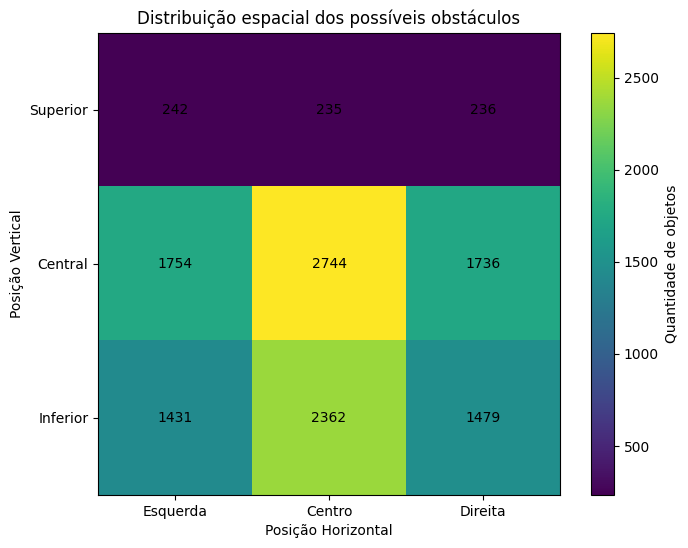

In [ ]:
# ============================================================
# 19. HEATMAP ESPACIAL DOS POSSÍVEIS OBSTÁCULOS
# ============================================================

import matplotlib.pyplot as plt

ordem_linhas = [
    "Superior - Esquerda",
    "Superior - Centro",
    "Superior - Direita",
    "Central - Esquerda",
    "Central - Centro",
    "Central - Direita",
    "Inferior - Esquerda",
    "Inferior - Centro",
    "Inferior - Direita"
]

heatmap_data = (
    obstacle_boxes["regiao_3x3"]
    .value_counts()
    .reindex(ordem_linhas, fill_value=0)
    .values
    .reshape(3, 3)
)

plt.figure(figsize=(8, 6))

plt.imshow(heatmap_data)

plt.xticks(
    [0, 1, 2],
    ["Esquerda", "Centro", "Direita"]
)

plt.yticks(
    [0, 1, 2],
    ["Superior", "Central", "Inferior"]
)

plt.xlabel("Posição Horizontal")
plt.ylabel("Posição Vertical")
plt.title("Distribuição espacial dos possíveis obstáculos")

for i in range(3):
    for j in range(3):
        plt.text(
            j,
            i,
            int(heatmap_data[i, j]),
            ha="center",
            va="center"
        )

plt.colorbar(label="Quantidade de objetos")

plt.show()

| Critério                            | Resultado                       |
| ----------------------------------- | ------------------------------- |
| Quantidade de imagens               | 🟡 Razoável                     |
| Integridade das anotações           | 🟢 Excelente                    |
| Correspondência imagem/label        | 🟢 Excelente                    |
| Correção visual das classes         | 🟢 Boa                          |
| Diversidade de objetos              | 🟢 Boa                          |
| Coocorrência de objetos             | 🟢 Boa                          |
| Representação de móveis             | 🟢 Boa                          |
| Distribuição espacial               | 🟢 Promissora                   |
| Classes balanceadas                 | 🔴 Não                          |
| Objetos pequenos                    | 🟡 Muitos                       |
| `potted plant`                      | 🟡 Muito predominante           |
| `bed`                               | 🔴 Poucos exemplos              |
| `door`                              | 🟡 Poucos exemplos              |
| Informação explícita de "obstáculo" | 🔴 Não possui                   |
| Adequação ao problema do TCC        | 🟢 **Promissora, mas limitada** |


# NYU Depth V2

In [ ]:
import requests

url = "https://academictorrents.com/download/47a9a46bb784b394e398228d4c85a8d61d01dfa8.torrent"
arquivo = "/content/nyu_depth_v2.torrent"

r = requests.get(url)

print("Status:", r.status_code)
print("Tamanho:", len(r.content) / 1024**2, "MB")

with open(arquivo, "wb") as f:
    f.write(r.content)

print("Torrent salvo em:", arquivo)

Status: 200
Tamanho: 0.05439949035644531 MB
Torrent salvo em: /content/nyu_depth_v2.torrent


In [ ]:
!apt-get update -qq
!apt-get install -y aria2 -qq

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libc-ares2:amd64.
(Reading database ... 118419 files and directories currently installed.)
Preparing to unpack .../libc-ares2_1.18.1-1ubuntu0.22.04.3_amd64.deb ...
Unpacking libc-ares2:amd64 (1.18.1-1ubuntu0.22.04.3) ...
Selecting previously unselected package libaria2-0:amd64.
Preparing to unpack .../libaria2-0_1.36.0-1_amd64.deb ...
Unpacking libaria2-0:amd64 (1.36.0-1) ...
Selecting previously unselected package aria2.
Preparing to unpack .../aria2_1.36.0-1_amd64.deb ...
Unpacking aria2 (1.36.0-1) ...
Setting up libc-ares2:amd64 (1.18.1-1ubuntu0.22.04.3) ...
Setting up libaria2-0:amd64 (1.36.0-1) ...
Setting up aria2 (1.36.0-1) ...
Processing triggers for man-db (2.10.2-1) ...
Processing triggers for libc-bin (2.35-0ubuntu3.14) ...
/sbin/ldconfig.real: /usr/

In [ ]:
!which aria2c

/usr/bin/aria2c


In [ ]:
!mkdir -p /content/nyu_depth_v2

!aria2c \
  --seed-time=0 \
  --bt-stop-timeout=60 \
  --file-allocation=none \
  --dir=/content/nyu_depth_v2 \
  /content/nyu_depth_v2.torrent


09/06 17:27:31 [NOTICE] Downloading 1 item(s)

09/06 17:27:31 [ERROR] Exception caught while loading DHT routing table from /root/.cache/aria2/dht.dat
Exception: [DHTRoutingTableDeserializer.cc:82] errorCode=1 Failed to load DHT routing table from /root/.cache/aria2/dht.dat

09/06 17:27:31 [NOTICE] IPv4 DHT: listening on UDP port 6894

09/06 17:27:31 [NOTICE] IPv4 BitTorrent: listening on TCP port 6952

09/06 17:27:31 [ERROR] IPv6 BitTorrent: failed to bind TCP port 6952
Exception: [SocketCore.cc:312] errorCode=1 Failed to bind a socket, cause: Name or service not known
 *** Download Progress Summary as of Sun Sep  6 17:28:32 2026 *** 
=
[#465a80 103MiB/2.7GiB(3%) CN:10 SD:4 DL:1.9MiB ETA:22m47s]
FILE: /content/nyu_depth_v2/nyu_depth_v2_labeled.mat
-

 *** Download Progress Summary as of Sun Sep  6 17:29:32 2026 *** 
=
[#465a80 1.1GiB/2.7GiB(43%) CN:11 SD:4 DL:32MiB ETA:49s]
FILE: /content/nyu_depth_v2/nyu_depth_v2_labeled.mat
-


09/06 17:30:04 [NOTICE] Seeding is over.

09/06 17:30:

In [ ]:
import os

print("Arquivos baixados:")

for raiz, pastas, arquivos in os.walk("/content/nyu_depth_v2"):
    for arquivo in arquivos:
        caminho = os.path.join(raiz, arquivo)
        tamanho_gb = os.path.getsize(caminho) / (1024**3)
        print(f"{arquivo} → {tamanho_gb:.2f} GB")

Arquivos baixados:
nyu_depth_v2_labeled.mat → 2.77 GB


In [ ]:
import h5py

caminho = "/content/nyu_depth_v2/nyu_depth_v2_labeled.mat"

arquivo = h5py.File(caminho, "r")

print("Estrutura do arquivo:")
print(list(arquivo.keys()))

Estrutura do arquivo:
['#refs#', '#subsystem#', 'accelData', 'depths', 'images', 'instances', 'labels', 'names', 'namesToIds', 'rawDepthFilenames', 'rawDepths', 'rawRgbFilenames', 'sceneTypes', 'scenes']


In [ ]:
for nome in arquivo.keys():
    objeto = arquivo[nome]

    try:
        print(f"{nome}: shape={objeto.shape}, dtype={objeto.dtype}")
    except:
        print(f"{nome}: {type(objeto)}")

#refs#: <class 'h5py._hl.group.Group'>
#subsystem#: <class 'h5py._hl.group.Group'>
accelData: shape=(4, 1449), dtype=float32
depths: shape=(1449, 640, 480), dtype=float32
images: shape=(1449, 3, 640, 480), dtype=uint8
instances: shape=(1449, 640, 480), dtype=uint8
labels: shape=(1449, 640, 480), dtype=uint16
names: shape=(1, 894), dtype=object
namesToIds: shape=(1, 6), dtype=uint32
rawDepthFilenames: shape=(1, 1449), dtype=object
rawDepths: shape=(1449, 640, 480), dtype=float32
rawRgbFilenames: shape=(1, 1449), dtype=object
sceneTypes: shape=(1, 1449), dtype=object
scenes: shape=(1, 1449), dtype=object


In [ ]:
names = arquivo["names"]

print("Shape:", names.shape)
print("Dtype:", names.dtype)

Shape: (1, 894)
Dtype: object


In [ ]:
print("Primeiros 20 nomes:")

for i in range(20):
    ref = names[0, i]
    print(i, ref)

Primeiros 20 nomes:
0 <HDF5 object reference>
1 <HDF5 object reference>
2 <HDF5 object reference>
3 <HDF5 object reference>
4 <HDF5 object reference>
5 <HDF5 object reference>
6 <HDF5 object reference>
7 <HDF5 object reference>
8 <HDF5 object reference>
9 <HDF5 object reference>
10 <HDF5 object reference>
11 <HDF5 object reference>
12 <HDF5 object reference>
13 <HDF5 object reference>
14 <HDF5 object reference>
15 <HDF5 object reference>
16 <HDF5 object reference>
17 <HDF5 object reference>
18 <HDF5 object reference>
19 <HDF5 object reference>


In [ ]:
# Ver quais objetos existem dentro de #refs#
refs = arquivo["#refs#"]

print("Quantidade de referências:", len(refs))

print("\nPrimeiras referências:")
for i, chave in enumerate(refs.keys()):
    print(i, chave)
    if i >= 10:
        break

Quantidade de referências: 8484

Primeiras referências:
0 0
1 00
2 00b
3 01
4 01b
5 02
6 02b
7 03
8 03b
9 04
10 04b


In [ ]:
# Pegar a primeira referência existente em names
ref = arquivo["names"][0, 0]

print("Referência:", ref)

obj = arquivo[ref]

print("Tipo:", type(obj))
print("Shape:", obj.shape)
print("Dtype:", obj.dtype)
print("Conteúdo:", obj[:])

Referência: <HDF5 object reference>
Tipo: <class 'h5py._hl.dataset.Dataset'>
Shape: (4, 1)
Dtype: uint16
Conteúdo: [[ 98]
 [111]
 [111]
 [107]]


In [ ]:
def decodificar_nome(ref):
    dados = arquivo[ref][:]
    return ''.join(chr(int(x[0])) for x in dados)

nomes_classes = []

for i in range(arquivo["names"].shape[1]):
    ref = arquivo["names"][0, i]
    nome = decodificar_nome(ref)
    nomes_classes.append(nome)

print("Total de classes:", len(nomes_classes))

print("\nPrimeiras 50 classes:")
for i, nome in enumerate(nomes_classes[:50]):
    print(f"{i}: {nome}")

Total de classes: 894

Primeiras 50 classes:
0: book
1: bottle
2: cabinet
3: ceiling
4: chair
5: cone
6: counter
7: dishwasher
8: faucet
9: fire extinguisher
10: floor
11: garbage bin
12: microwave
13: paper towel dispenser
14: paper
15: pot
16: refridgerator
17: stove burner
18: table
19: unknown
20: wall
21: bowl
22: magnet
23: sink
24: air vent
25: box
26: door knob
27: door
28: scissor
29: tape dispenser
30: telephone cord
31: telephone
32: track light
33: cork board
34: cup
35: desk
36: laptop
37: air duct
38: basket
39: camera
40: pipe
41: shelves
42: stacked chairs
43: styrofoam object
44: whiteboard
45: computer
46: keyboard
47: ladder
48: monitor
49: stand


In [ ]:
import numpy as np

labels_dataset = arquivo["labels"]

classes_presentes = set()

for i in range(labels_dataset.shape[0]):
    labels_img = labels_dataset[i]
    ids = np.unique(labels_img)
    classes_presentes.update(ids.tolist())

classes_presentes = sorted(classes_presentes)

print("Quantidade de IDs de classe encontrados:", len(classes_presentes))
print("Primeiros IDs:", classes_presentes[:50])
print("Últimos IDs:", classes_presentes[-20:])

Quantidade de IDs de classe encontrados: 895
Primeiros IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49]
Últimos IDs: [875, 876, 877, 878, 879, 880, 881, 882, 883, 884, 885, 886, 887, 888, 889, 890, 891, 892, 893, 894]


In [ ]:
print("Classes encontradas no dataset:\n")

for class_id in classes_presentes:
    if class_id < len(nomes_classes):
        print(f"{class_id}: {nomes_classes[class_id]}")
    else:
        print(f"{class_id}: ID sem nome correspondente")

Classes encontradas no dataset:

0: book
1: bottle
2: cabinet
3: ceiling
4: chair
5: cone
6: counter
7: dishwasher
8: faucet
9: fire extinguisher
10: floor
11: garbage bin
12: microwave
13: paper towel dispenser
14: paper
15: pot
16: refridgerator
17: stove burner
18: table
19: unknown
20: wall
21: bowl
22: magnet
23: sink
24: air vent
25: box
26: door knob
27: door
28: scissor
29: tape dispenser
30: telephone cord
31: telephone
32: track light
33: cork board
34: cup
35: desk
36: laptop
37: air duct
38: basket
39: camera
40: pipe
41: shelves
42: stacked chairs
43: styrofoam object
44: whiteboard
45: computer
46: keyboard
47: ladder
48: monitor
49: stand
50: bar
51: motion camera
52: projector screen
53: speaker
54: bag
55: clock
56: green screen
57: mantel
58: window
59: ball
60: hole puncher
61: light
62: manilla envelope
63: picture
64: mail shelf
65: printer
66: stapler
67: fax machine
68: folder
69: jar
70: magazine
71: ruler
72: cable modem
73: fan
74: file
75: hand sanitizer
76: 

In [ ]:
classes_obstaculo_nyu = [
    "chair",
    "table",
    "desk",
    "sofa",
    "bed",
    "cabinet",
    "shelves",
    "shelf",
    "bookshelf",
    "dresser",
    "drawer",
    "night stand",
    "coffee table",
    "ottoman",
    "stool",
    "bench",
    "door",
    "refridgerator",
    "sink",
    "toilet",
    "garbage bin",
    "box",
    "cart",
    "shopping cart",
    "bicycle",
    "stroller",
    "plant",
    "flower pot",
    "bag",
    "suitcase",
    "backpack",
    "basket",
    "ladder",
    "trolley",
    "trolly",
    "furniture",
    "room divider",
    "stairs",
    "baby gate",
    "shoe rack",
    "wardrobe",
    "storage bin",
    "storage chest"
]

In [ ]:
# Criar mapa entre ID e nome da classe
id_para_classe = {
    i: nome
    for i, nome in enumerate(nomes_classes)
}

# Criar também o inverso
classe_para_id = {
    nome: i
    for i, nome in id_para_classe.items()
}

print("Exemplos:")
for nome in ["chair", "table", "bed", "sofa", "door"]:
    print(nome, "→", classe_para_id.get(nome))

Exemplos:
chair → 4
table → 18
bed → 156
sofa → 82
door → 27


In [ ]:
from collections import Counter
import numpy as np

labels_dataset = arquivo["labels"]

contagem_pixels = Counter()

for i in range(labels_dataset.shape[0]):
    labels_img = labels_dataset[i]

    ids, contagens = np.unique(labels_img, return_counts=True)

    for class_id, quantidade in zip(ids, contagens):
        contagem_pixels[int(class_id)] += int(quantidade)

print("IDs de classe encontrados:", len(contagem_pixels))

IDs de classe encontrados: 895


In [ ]:
i = 0

labels_img = arquivo["labels"][i]
instances_img = arquivo["instances"][i]

print("Labels:")
print("  shape:", labels_img.shape)
print("  IDs:", np.unique(labels_img)[:30])

print("\nInstances:")
print("  shape:", instances_img.shape)
print("  IDs:", np.unique(instances_img)[:30])

print("\nQuantidade de IDs de instância:", len(np.unique(instances_img)))

Labels:
  shape: (640, 480)
  IDs: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21]

Instances:
  shape: (640, 480)
  IDs: [0 1 2 3 4 5]

Quantidade de IDs de instância: 6


In [ ]:
import pandas as pd
import numpy as np

labels_dataset = arquivo["labels"]
instances_dataset = arquivo["instances"]

anotacoes_nyu = []

for i in range(labels_dataset.shape[0]):

    labels_img = labels_dataset[i]
    instances_img = instances_dataset[i]

    # IDs de instância, ignorando o fundo (0)
    ids_instancias = np.unique(instances_img)
    ids_instancias = ids_instancias[ids_instancias != 0]

    for instance_id in ids_instancias:

        # Pixels pertencentes à instância
        mascara = instances_img == instance_id

        # Coordenadas
        ys, xs = np.where(mascara)

        if len(xs) == 0:
            continue

        # Bounding box
        x_min = xs.min()
        x_max = xs.max()
        y_min = ys.min()
        y_max = ys.max()

        largura = x_max - x_min + 1
        altura = y_max - y_min + 1

        # Classe da instância
        ids_classes = labels_img[mascara]

        # Classe mais frequente dentro da instância
        classe_id = int(np.bincount(ids_classes).argmax())

        # Nome da classe
        classe = id_para_classe.get(classe_id, f"ID_{classe_id}")

        anotacoes_nyu.append({
            "imagem_id": i,
            "instance_id": int(instance_id),
            "classe_id": classe_id,
            "classe": classe,
            "x": int(x_min),
            "y": int(y_min),
            "largura": int(largura),
            "altura": int(altura)
        })

df_nyu = pd.DataFrame(anotacoes_nyu)

print("Shape:", df_nyu.shape)
print("\nPrimeiras anotações:")
display(df_nyu.head(20))

Shape: (7761, 8)

Primeiras anotações:


,imagem_id,instance_id,classe_id,classe,x,y,largura,altura
0,0,1,12,microwave,6,7,470,628
1,0,2,4,chair,6,7,469,627
2,0,3,21,bowl,28,60,251,16
3,0,4,21,bowl,42,64,396,438
4,0,5,21,bowl,20,8,345,58
5,1,1,17,stove burner,7,7,469,626
6,1,2,3,ceiling,7,127,466,507
7,1,3,21,bowl,6,9,470,399
8,1,4,15,pot,226,274,161,113
9,1,5,15,pot,118,331,267,106


In [ ]:
print("Quantidade de imagens:", df_nyu["imagem_id"].nunique())
print("Quantidade de objetos:", len(df_nyu))
print("Quantidade de classes:", df_nyu["classe"].nunique())

print("\nClasses mais frequentes:")
display(
    df_nyu["classe"]
    .value_counts()
    .head(30)
)

Quantidade de imagens: 1449
Quantidade de objetos: 7761
Quantidade de classes: 162

Classes mais frequentes:


,count
classe,
bowl,1955
cone,779
mail shelf,677
ceiling,651
garbage bin,342
hair brush,307
exit sign,297
bottle,181
cabinet,181


In [ ]:
print("Dimensões das bounding boxes:")
display(
    df_nyu[["largura", "altura"]].describe()
)

Dimensões das bounding boxes:


,largura,altura
count,7761.000000,7761.000000
mean,248.882876,309.027574
std,173.272619,238.507353
min,2.000000,3.000000
25%,67.000000,66.000000
50%,239.000000,276.000000
75%,462.000000,580.000000
max,472.000000,629.000000


In [ ]:
# ID da classe no NYU começa em 1
id_para_classe_nyu = {
    i + 1: nome
    for i, nome in enumerate(nomes_classes)
}

classe_para_id_nyu = {
    nome: i
    for i, nome in id_para_classe_nyu.items()
}

# Conferindo algumas classes
for i in range(1, 25):
    print(i, "->", id_para_classe_nyu.get(i))

1 -> book
2 -> bottle
3 -> cabinet
4 -> ceiling
5 -> chair
6 -> cone
7 -> counter
8 -> dishwasher
9 -> faucet
10 -> fire extinguisher
11 -> floor
12 -> garbage bin
13 -> microwave
14 -> paper towel dispenser
15 -> paper
16 -> pot
17 -> refridgerator
18 -> stove burner
19 -> table
20 -> unknown
21 -> wall
22 -> bowl
23 -> magnet
24 -> sink


In [ ]:
import pandas as pd
import numpy as np

labels_dataset = arquivo["labels"]
instances_dataset = arquivo["instances"]

anotacoes_nyu = []

for i in range(labels_dataset.shape[0]):

    labels_img = labels_dataset[i]
    instances_img = instances_dataset[i]

    # Pares únicos de classe + instância
    pares = np.unique(
        np.stack([labels_img.ravel(), instances_img.ravel()], axis=1),
        axis=0
    )

    for classe_id, instance_id in pares:

        classe_id = int(classe_id)
        instance_id = int(instance_id)

        # Ignorar pixels não rotulados
        if classe_id == 0:
            continue

        # Ignorar fundo da instância
        if instance_id == 0:
            continue

        # Máscara específica daquele objeto
        mascara = (
            (labels_img == classe_id) &
            (instances_img == instance_id)
        )

        ys, xs = np.where(mascara)

        if len(xs) == 0:
            continue

        # Bounding box
        x_min = int(xs.min())
        x_max = int(xs.max())
        y_min = int(ys.min())
        y_max = int(ys.max())

        largura = x_max - x_min + 1
        altura = y_max - y_min + 1

        classe = id_para_classe_nyu.get(
            classe_id,
            f"ID_{classe_id}"
        )

        anotacoes_nyu.append({
            "imagem_id": i,
            "instance_id": instance_id,
            "classe_id": classe_id,
            "classe": classe,
            "x": x_min,
            "y": y_min,
            "largura": largura,
            "altura": altura
        })

df_nyu = pd.DataFrame(anotacoes_nyu)

print("Shape:", df_nyu.shape)

display(df_nyu.head(20))

Shape: (35064, 8)


,imagem_id,instance_id,classe_id,classe,x,y,largura,altura
0,0,1,1,book,468,303,8,86
1,0,1,2,bottle,274,582,43,21
2,0,1,3,cabinet,312,415,164,85
3,0,2,3,cabinet,57,464,179,170
4,0,1,4,ceiling,6,409,123,226
5,0,2,4,ceiling,6,7,78,497
6,0,1,5,chair,402,7,74,99
7,0,2,5,chair,333,175,142,150
8,0,1,6,cone,293,26,76,32
9,0,1,7,counter,301,418,51,173


In [ ]:
print("Quantidade de imagens:",
      df_nyu["imagem_id"].nunique())

print("Quantidade de objetos:",
      len(df_nyu))

print("Quantidade de classes:",
      df_nyu["classe"].nunique())

print("\nClasses mais frequentes:")

display(
    df_nyu["classe"]
    .value_counts()
    .head(30)
)

Quantidade de imagens: 1449
Quantidade de objetos: 35064
Quantidade de classes: 894

Classes mais frequentes:


,count
classe,
wall,3681
picture,2421
chair,2075
cabinet,1522
floor,1423
pillow,1046
bottle,920
books,834
paper,790


In [ ]:
print("Dimensões das bounding boxes:")

display(
    df_nyu[["largura", "altura"]].describe()
)

Dimensões das bounding boxes:


,largura,altura
count,35064.000000,35064.000000
mean,109.283510,119.703884
std,100.087701,128.872751
min,2.000000,1.000000
25%,36.000000,37.000000
50%,72.000000,72.000000
75%,155.000000,146.000000
max,472.000000,628.000000


In [ ]:
classes_candidatas_nyu = [
    "chair",
    "table",
    "desk",
    "sofa",
    "bed",
    "cabinet",
    "shelves",
    "bookshelf",
    "dresser",
    "drawer",
    "night stand",
    "coffee table",
    "ottoman",
    "stool",
    "bench",
    "door",
    "refridgerator",
    "sink",
    "toilet",
    "garbage bin",
    "box",
    "cart",
    "shopping cart",
    "bicycle",
    "stroller",
    "plant",
    "flower pot",
    "bag",
    "suitcase",
    "backpack",
    "basket",
    "ladder",
    "trolley",
    "trolly",
    "stairs",
    "baby gate",
    "shoe rack",
    "wardrobe",
    "storage bin",
    "storage chest",
    "room divider",
    "coat hanger",
    "clothing drying rack"
]

classes_existentes = [
    c for c in classes_candidatas_nyu
    if c in set(df_nyu["classe"].unique())
]

classes_nao_encontradas = [
    c for c in classes_candidatas_nyu
    if c not in set(df_nyu["classe"].unique())
]

print("CLASSES ENCONTRADAS:")
for c in classes_existentes:
    print(c)

print("\nQuantidade encontradas:", len(classes_existentes))

print("\nCLASSES NÃO ENCONTRADAS:")
for c in classes_nao_encontradas:
    print(c)

CLASSES ENCONTRADAS:
chair
table
desk
sofa
bed
cabinet
shelves
bookshelf
dresser
drawer
night stand
coffee table
ottoman
stool
bench
door
refridgerator
sink
toilet
garbage bin
box
cart
shopping cart
bicycle
stroller
plant
flower pot
bag
suitcase
backpack
basket
ladder
trolley
trolly
stairs
baby gate
shoe rack
wardrobe
storage bin
storage chest
room divider
coat hanger
clothing drying rack

Quantidade encontradas: 43

CLASSES NÃO ENCONTRADAS:


In [ ]:
df_nyu_obstaculos = df_nyu[
    df_nyu["classe"].isin(classes_existentes)
].copy()

print("Objetos potencialmente relacionados a obstáculos:",
      len(df_nyu_obstaculos))

print("Imagens com pelo menos um objeto potencialmente relacionado:",
      df_nyu_obstaculos["imagem_id"].nunique())

print("\nDistribuição:")

display(
    df_nyu_obstaculos["classe"]
    .value_counts()
)

Objetos potencialmente relacionados a obstáculos: 9568
Imagens com pelo menos um objeto potencialmente relacionado: 1440

Distribuição:


,count
classe,
chair,2075
cabinet,1522
table,726
box,637
door,511
bag,508
sofa,495
shelves,426
bed,358


In [ ]:
print(
    df_nyu_obstaculos.groupby("classe")["imagem_id"]
    .nunique()
    .sort_values(ascending=False)
)

classe
cabinet                 664
chair                   654
table                   539
door                    400
box                     363
bag                     343
bed                     318
sofa                    307
shelves                 253
bookshelf               207
desk                    197
sink                    193
garbage bin             171
night stand             148
dresser                 111
plant                   110
refridgerator            95
basket                   71
toilet                   68
stool                    55
coffee table             53
drawer                   44
ottoman                  36
flower pot               29
backpack                 27
room divider             22
stairs                   17
ladder                   16
bench                    14
bicycle                  10
suitcase                  8
stroller                  8
clothing drying rack      4
coat hanger               3
baby gate                 3
wardrobe     

In [ ]:
print("Objetos potencialmente relacionados a obstáculos:")
print(len(df_nyu_obstaculos))

print("\nImagens com pelo menos um:")
print(df_nyu_obstaculos["imagem_id"].nunique())

print("\nObjetos por classe:")
display(
    df_nyu_obstaculos["classe"]
    .value_counts()
)

Objetos potencialmente relacionados a obstáculos:
9568

Imagens com pelo menos um:
1440

Objetos por classe:


,count
classe,
chair,2075
cabinet,1522
table,726
box,637
door,511
bag,508
sofa,495
shelves,426
bed,358


In [ ]:
objetos_por_imagem_nyu = (
    df_nyu_obstaculos
    .groupby("imagem_id")
    .size()
)

print("Média:", objetos_por_imagem_nyu.mean())
print("Mediana:", objetos_por_imagem_nyu.median())
print("Mínimo:", objetos_por_imagem_nyu.min())
print("Máximo:", objetos_por_imagem_nyu.max())

print("\nDistribuição:")
display(
    objetos_por_imagem_nyu.describe()
)

Média: 6.644444444444445
Mediana: 6.0
Mínimo: 1
Máximo: 37

Distribuição:


,0
count,1440.000000
mean,6.644444
std,4.433428
min,1.000000
25%,4.000000
50%,6.000000
75%,9.000000
max,37.000000


In [ ]:
contagem_classes = (
    df_nyu_obstaculos["classe"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Classes com pelo menos 30 objetos:")
display(
    contagem_classes[contagem_classes >= 30]
)

print(
    "\nQuantidade de classes com >= 30 objetos:",
    (contagem_classes >= 30).sum()
)

Classes com pelo menos 30 objetos:


,count
classe,
chair,2075
cabinet,1522
table,726
box,637
door,511
bag,508
sofa,495
shelves,426
bed,358



Quantidade de classes com >= 30 objetos: 25


In [ ]:
classes_nyu_30 = contagem_classes[
    contagem_classes >= 30
].index.tolist()

df_nyu_obstaculos_30 = df_nyu_obstaculos[
    df_nyu_obstaculos["classe"].isin(classes_nyu_30)
].copy()

print("Objetos após o filtro:", len(df_nyu_obstaculos_30))
print(
    "Imagens com pelo menos uma dessas classes:",
    df_nyu_obstaculos_30["imagem_id"].nunique()
)

Objetos após o filtro: 9442
Imagens com pelo menos uma dessas classes: 1438


In [ ]:
df_nyu_obstaculos_30 = df_nyu_obstaculos_30.copy()

# Área da imagem
area_imagem = 640 * 480

# Área da bounding box
df_nyu_obstaculos_30["area_bbox"] = (
    df_nyu_obstaculos_30["largura"] *
    df_nyu_obstaculos_30["altura"]
)

# Área relativa
df_nyu_obstaculos_30["area_relativa"] = (
    df_nyu_obstaculos_30["area_bbox"] / area_imagem
)

print("Área relativa das bounding boxes:")
display(
    df_nyu_obstaculos_30["area_relativa"].describe()
)

Área relativa das bounding boxes:


,area_relativa
count,9442.000000
mean,0.076069
std,0.104370
min,0.000052
25%,0.010427
50%,0.035151
75%,0.098613
max,0.957236


In [ ]:
def classificar_tamanho(area):
    if area < 0.05:
        return "Pequeno"
    elif area <= 0.20:
        return "Médio"
    else:
        return "Grande"

df_nyu_obstaculos_30["tamanho"] = (
    df_nyu_obstaculos_30["area_relativa"]
    .apply(classificar_tamanho)
)

print("Distribuição do tamanho das bounding boxes:")

display(
    df_nyu_obstaculos_30["tamanho"]
    .value_counts()
)

Distribuição do tamanho das bounding boxes:


,count
tamanho,
Pequeno,5550
Médio,2888
Grande,1004


In [ ]:
distribuicao_tamanho_nyu = (
    df_nyu_obstaculos_30["tamanho"]
    .value_counts()
)

percentuais_nyu = (
    distribuicao_tamanho_nyu /
    len(df_nyu_obstaculos_30) * 100
)

resultado_tamanho_nyu = pd.DataFrame({
    "Quantidade": distribuicao_tamanho_nyu,
    "Percentual (%)": percentuais_nyu.round(2)
})

display(resultado_tamanho_nyu)

,Quantidade,Percentual (%)
tamanho,,
Pequeno,5550,58.78
Médio,2888,30.59
Grande,1004,10.63


In [ ]:
# Centro vertical da bounding box
df_nyu_obstaculos_30["centro_y"] = (
    df_nyu_obstaculos_30["y"] +
    df_nyu_obstaculos_30["altura"] / 2
)

# Normalização pela altura da imagem
df_nyu_obstaculos_30["centro_y_relativo"] = (
    df_nyu_obstaculos_30["centro_y"] / 480
)

def classificar_posicao(pos):
    if pos < 1/3:
        return "Superior"
    elif pos < 2/3:
        return "Central"
    else:
        return "Inferior"

df_nyu_obstaculos_30["posicao"] = (
    df_nyu_obstaculos_30["centro_y_relativo"]
    .apply(classificar_posicao)
)

print("Distribuição da posição vertical:")

display(
    df_nyu_obstaculos_30["posicao"]
    .value_counts()
)

Distribuição da posição vertical:


,count
posicao,
Inferior,4890
Central,2497
Superior,2055


In [ ]:
posicao_por_classe_nyu = pd.crosstab(
    df_nyu_obstaculos_30["classe"],
    df_nyu_obstaculos_30["posicao"]
)

display(
    posicao_por_classe_nyu
    .sort_values(
        by=["Inferior", "Central"],
        ascending=False
    )
)

posicao,Central,Inferior,Superior
classe,,,
chair,599,1024,452
cabinet,391,798,333
table,208,369,149
box,152,351,134
bag,134,266,108
door,112,257,142
sofa,132,244,119
shelves,94,228,104
desk,102,191,64


In [ ]:
tamanho_posicao_nyu = pd.crosstab(
    df_nyu_obstaculos_30["classe"],
    df_nyu_obstaculos_30["tamanho"]
)

display(tamanho_posicao_nyu)

tamanho,Grande,Médio,Pequeno
classe,,,
backpack,0,5,88
bag,0,21,487
basket,0,5,87
bed,197,130,31
bookshelf,85,117,74
box,0,16,621
cabinet,199,599,724
chair,59,665,1351
coffee table,3,29,25


In [ ]:
tamanhos_relevantes = ["Médio", "Grande"]
posicoes_relevantes = ["Central", "Inferior"]

df_nyu_cruzamento = df_nyu_obstaculos_30[
    df_nyu_obstaculos_30["tamanho"].isin(tamanhos_relevantes) &
    df_nyu_obstaculos_30["posicao"].isin(posicoes_relevantes)
].copy()

print("Objetos médios/grandes em posição central/inferior:")
print(len(df_nyu_cruzamento))

print("\nPercentual sobre todos os objetos relevantes:")
print(
    round(
        len(df_nyu_cruzamento) /
        len(df_nyu_obstaculos_30) * 100,
        2
    ),
    "%"
)

Objetos médios/grandes em posição central/inferior:
3080

Percentual sobre todos os objetos relevantes:
32.62 %


In [ ]:
resultado_cruzamento_nyu = (
    df_nyu_cruzamento
    .groupby("classe")
    .size()
    .to_frame("quantidade")
)

total_por_classe = (
    df_nyu_obstaculos_30
    .groupby("classe")
    .size()
    .to_frame("total")
)

resultado_cruzamento_nyu = (
    total_por_classe
    .join(resultado_cruzamento_nyu, how="left")
    .fillna(0)
)

resultado_cruzamento_nyu["percentual"] = (
    resultado_cruzamento_nyu["quantidade"] /
    resultado_cruzamento_nyu["total"] * 100
)

resultado_cruzamento_nyu = (
    resultado_cruzamento_nyu
    .sort_values("percentual", ascending=False)
)

display(resultado_cruzamento_nyu)

,total,quantidade,percentual
classe,,,
bed,358,264,73.743017
dresser,123,75,60.975610
bookshelf,276,155,56.159420
sofa,495,276,55.757576
toilet,72,40,55.555556
refridgerator,98,52,53.061224
coffee table,57,29,50.877193
desk,357,175,49.019608
table,726,325,44.765840


In [ ]:
from itertools import combinations
from collections import Counter

coocorrencia_nyu = Counter()

for imagem_id, grupo in df_nyu_obstaculos_30.groupby("imagem_id"):

    classes = sorted(
        grupo["classe"].unique()
    )

    for classe_a, classe_b in combinations(classes, 2):
        coocorrencia_nyu[(classe_a, classe_b)] += 1

print("Quantidade de pares de classes:",
      len(coocorrencia_nyu))

print("\nTop 30 combinações:")

for (classe_a, classe_b), quantidade in coocorrencia_nyu.most_common(30):
    print(
        f"{classe_a} + {classe_b}: {quantidade}"
    )

Quantidade de pares de classes: 265

Top 30 combinações:
chair + table: 385
cabinet + chair: 318
cabinet + table: 234
bag + cabinet: 197
cabinet + door: 193
chair + door: 184
box + cabinet: 184
sofa + table: 179
cabinet + sink: 176
box + chair: 171
door + table: 164
chair + desk: 161
bag + chair: 161
bed + night stand: 145
chair + sofa: 141
chair + shelves: 129
box + table: 125
shelves + table: 117
bag + door: 116
cabinet + shelves: 111
bag + table: 111
cabinet + sofa: 101
bookshelf + chair: 101
box + shelves: 99
bag + box: 99
cabinet + refridgerator: 93
bed + chair: 92
box + door: 88
door + sofa: 88
bed + box: 86


In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# Caminho do dataset
caminho_nyu = "/content/nyu_depth_v2/nyu_depth_v2_labeled.mat"

# Abrir o arquivo
arquivo_nyu = h5py.File(caminho_nyu, "r")

# Acessar as imagens
images = arquivo_nyu["images"]

print("Formato das imagens:", images.shape)
print("Tipo:", images.dtype)

Formato das imagens: (1449, 3, 640, 480)
Tipo: uint8


In [ ]:
import h5py
import numpy as np

caminho_nyu = "/content/nyu_depth_v2/nyu_depth_v2_labeled.mat"

arquivo_nyu = h5py.File(caminho_nyu, "r")

images = arquivo_nyu["images"]
labels = arquivo_nyu["labels"]
instances = arquivo_nyu["instances"]

print("images:", images.shape)
print("labels:", labels.shape)
print("instances:", instances.shape)

images: (1449, 3, 640, 480)
labels: (1449, 640, 480)
instances: (1449, 640, 480)


In [ ]:
imagem_id = 0

img = np.array(images[imagem_id])
lab = np.array(labels[imagem_id])
ins = np.array(instances[imagem_id])

print("Imagem:", img.shape)
print("Labels:", lab.shape)
print("Instances:", ins.shape)

Imagem: (3, 640, 480)
Labels: (640, 480)
Instances: (640, 480)


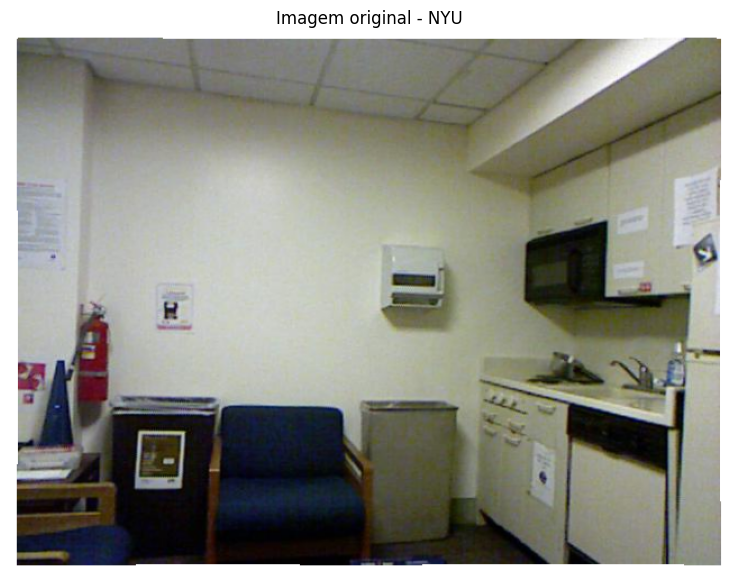

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

# Imagem original
img_visual = np.transpose(img, (2, 1, 0))

plt.imshow(img_visual)
plt.axis("off")
plt.title("Imagem original - NYU")
plt.show()

In [ ]:
# Transpor labels e instances para a mesma orientação visual da imagem
lab_visual = lab.T
ins_visual = ins.T

print("Labels visual:", lab_visual.shape)
print("Instances visual:", ins_visual.shape)

Labels visual: (480, 640)
Instances visual: (480, 640)


In [ ]:
ids_classes = np.unique(lab_visual)

print("IDs de classe encontrados:")
print(ids_classes)

IDs de classe encontrados:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21]


In [ ]:
for classe_id in ids_classes:

    if classe_id == 0:
        continue

    if classe_id <= len(nomes_classes):
        nome = nomes_classes[classe_id - 1]
    else:
        nome = "ID desconhecido"

    print(classe_id, "->", nome)

1 -> book
2 -> bottle
3 -> cabinet
4 -> ceiling
5 -> chair
6 -> cone
7 -> counter
8 -> dishwasher
9 -> faucet
10 -> fire extinguisher
11 -> floor
12 -> garbage bin
13 -> microwave
14 -> paper towel dispenser
15 -> paper
16 -> pot
17 -> refridgerator
18 -> stove burner
19 -> table
20 -> unknown
21 -> wall


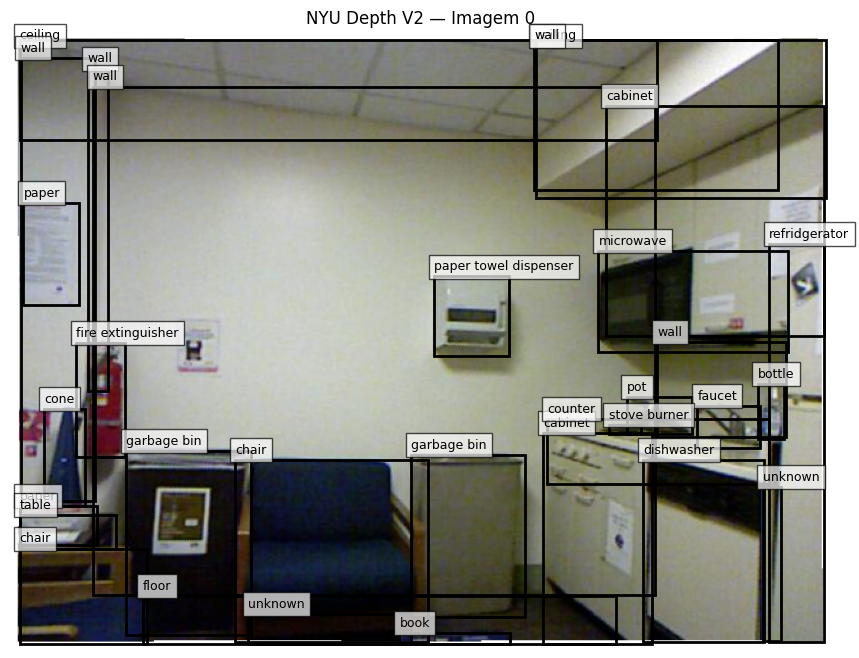

In [ ]:
plt.figure(figsize=(12, 8))

plt.imshow(img_visual)

for classe_id in ids_classes:

    if classe_id == 0:
        continue

    # Nome da classe
    if classe_id <= len(nomes_classes):
        nome = nomes_classes[classe_id - 1]
    else:
        nome = "ID desconhecido"

    # Cada instância daquela classe
    ids_instancias = np.unique(
        ins_visual[lab_visual == classe_id]
    )

    for instancia_id in ids_instancias:

        if instancia_id == 0:
            continue

        mascara = (
            (lab_visual == classe_id) &
            (ins_visual == instancia_id)
        )

        ys, xs = np.where(mascara)

        if len(xs) == 0:
            continue

        x_min = xs.min()
        x_max = xs.max()
        y_min = ys.min()
        y_max = ys.max()

        largura = x_max - x_min + 1
        altura = y_max - y_min + 1

        rect = plt.Rectangle(
            (x_min, y_min),
            largura,
            altura,
            fill=False,
            linewidth=2
        )

        plt.gca().add_patch(rect)

        plt.text(
            x_min,
            max(y_min - 5, 5),
            nome,
            fontsize=9,
            bbox=dict(
                facecolor="white",
                alpha=0.7
            )
        )

plt.axis("off")
plt.title(f"NYU Depth V2 — Imagem {imagem_id}")
plt.show()

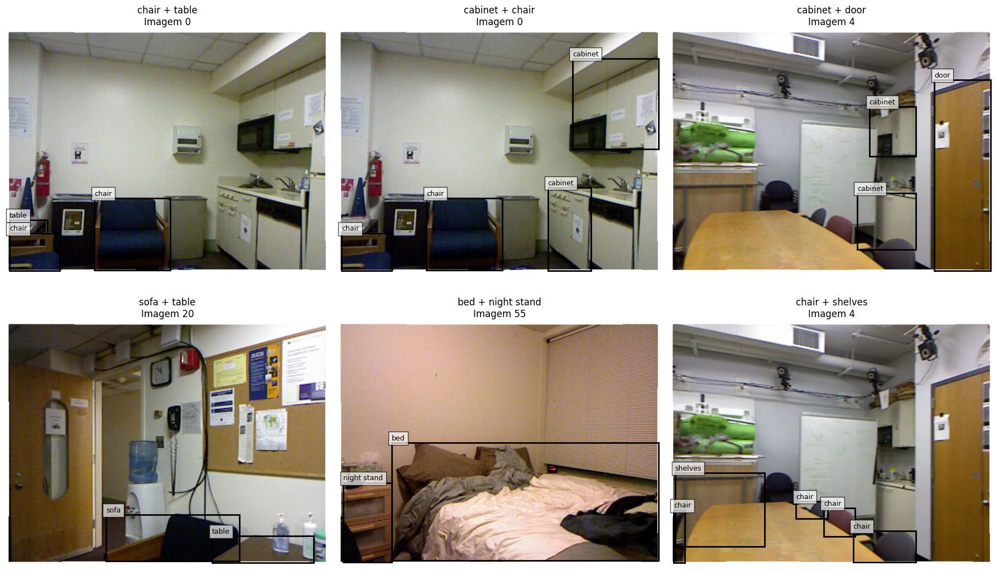

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

pares_validacao = [
    ("chair", "table"),
    ("cabinet", "chair"),
    ("cabinet", "door"),
    ("sofa", "table"),
    ("bed", "night stand"),
    ("chair", "shelves")
]

def encontrar_imagem_com_par(classe_a, classe_b):

    imagens_a = set(
        df_nyu_obstaculos_30[
            df_nyu_obstaculos_30["classe"] == classe_a
        ]["imagem_id"]
    )

    imagens_b = set(
        df_nyu_obstaculos_30[
            df_nyu_obstaculos_30["classe"] == classe_b
        ]["imagem_id"]
    )

    comuns = sorted(imagens_a & imagens_b)

    return comuns[0] if comuns else None


fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for ax, (classe_a, classe_b) in zip(axes, pares_validacao):

    imagem_id = encontrar_imagem_com_par(classe_a, classe_b)

    if imagem_id is None:
        ax.set_title(f"{classe_a} + {classe_b}\nNenhuma imagem")
        ax.axis("off")
        continue

    # Imagem
    img = np.array(images[imagem_id])
    img_visual = np.transpose(img, (2, 1, 0))

    # Labels e instances
    lab = np.array(labels[imagem_id]).T
    ins = np.array(instances[imagem_id]).T

    ax.imshow(img_visual)

    # IDs das classes desejadas
    for classe in [classe_a, classe_b]:

        classe_id = classe_para_id_nyu.get(classe)

        if classe_id is None:
            continue

        ids_instancias = np.unique(
            ins[lab == classe_id]
        )

        for instancia_id in ids_instancias:

            if instancia_id == 0:
                continue

            mascara = (
                (lab == classe_id) &
                (ins == instancia_id)
            )

            ys, xs = np.where(mascara)

            if len(xs) == 0:
                continue

            x_min, x_max = xs.min(), xs.max()
            y_min, y_max = ys.min(), ys.max()

            rect = plt.Rectangle(
                (x_min, y_min),
                x_max - x_min + 1,
                y_max - y_min + 1,
                fill=False,
                linewidth=2
            )

            ax.add_patch(rect)

            ax.text(
                x_min,
                max(y_min - 5, 5),
                classe,
                fontsize=9,
                bbox=dict(
                    facecolor="white",
                    alpha=0.7
                )
            )

    ax.set_title(
        f"{classe_a} + {classe_b}\nImagem {imagem_id}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Acessar o mapa de profundidade
depths = arquivo_nyu["depths"]

print("Formato:", depths.shape)
print("Tipo:", depths.dtype)

Formato: (1449, 640, 480)
Tipo: float32


In [ ]:
imagem_id = 0

depth = np.array(depths[imagem_id])

print("Dimensão:", depth.shape)
print("Valor mínimo:", np.min(depth))
print("Valor máximo:", np.max(depth))
print("Valor médio:", np.mean(depth))
print("Mediana:", np.median(depth))

Dimensão: (640, 480)
Valor mínimo: 1.7985953
Valor máximo: 3.615639
Valor médio: 2.87957
Mediana: 2.941576


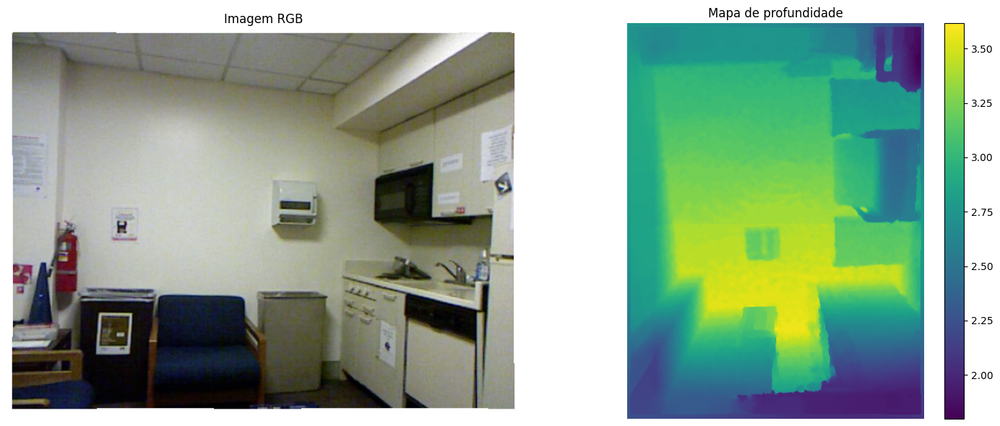

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# RGB
img = np.array(images[imagem_id])
img_visual = np.transpose(img, (2, 1, 0))

axes[0].imshow(img_visual)
axes[0].set_title("Imagem RGB")
axes[0].axis("off")

# Profundidade
im = axes[1].imshow(depth)
axes[1].set_title("Mapa de profundidade")
axes[1].axis("off")

plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

anotacoes_nyu = []

for imagem_id in range(1449):

    # Labels e instâncias da imagem
    lab = np.array(labels[imagem_id]).T
    ins = np.array(instances[imagem_id]).T

    # Combinações únicas de classe + instância
    pares = np.unique(
        np.stack(
            [lab.ravel(), ins.ravel()],
            axis=1
        ),
        axis=0
    )

    for classe_id, instancia_id in pares:

        # Ignorar fundo / não rotulado
        if classe_id == 0 or instancia_id == 0:
            continue

        # Nome da classe
        if classe_id <= len(nomes_classes):
            classe = nomes_classes[classe_id - 1]
        else:
            continue

        # Considerar somente nossas classes candidatas
        if classe not in classes_candidatas_nyu:
            continue

        # Máscara EXATA daquela instância
        mascara = (
            (lab == classe_id) &
            (ins == instancia_id)
        )

        ys, xs = np.where(mascara)

        if len(xs) == 0:
            continue

        x_min = xs.min()
        x_max = xs.max()
        y_min = ys.min()
        y_max = ys.max()

        anotacoes_nyu.append({
            "imagem_id": imagem_id,
            "classe": classe,
            "classe_id": int(classe_id),
            "instance_id": int(instancia_id),
            "x": int(x_min),
            "y": int(y_min),
            "largura": int(x_max - x_min + 1),
            "altura": int(y_max - y_min + 1),
            "pixels": len(xs)
        })

df_nyu_objetos = pd.DataFrame(anotacoes_nyu)

print("Objetos:", len(df_nyu_objetos))
print("Imagens:", df_nyu_objetos["imagem_id"].nunique())
print("Classes:", df_nyu_objetos["classe"].nunique())

df_nyu_objetos.head(15)

Objetos: 9568
Imagens: 1440
Classes: 43


,imagem_id,classe,classe_id,instance_id,x,y,largura,altura,pixels
0,0,cabinet,3,1,415,312,85,164,11179
1,0,cabinet,3,2,464,57,170,179,18025
2,0,chair,5,1,7,402,99,74,6815
3,0,chair,5,2,175,333,150,142,16582
4,0,garbage bin,12,1,90,326,97,143,11803
5,0,garbage bin,12,2,312,329,89,126,9446
6,0,refridgerator,17,1,591,165,43,310,10354
7,0,table,19,1,7,376,75,26,672
8,1,cabinet,3,1,67,391,181,85,11292
9,1,cabinet,3,2,127,7,507,263,77541


In [ ]:
contagem_classes = df_nyu_objetos["classe"].value_counts()

classes_30 = contagem_classes[
    contagem_classes >= 30
].index

df_nyu_objetos_30 = df_nyu_objetos[
    df_nyu_objetos["classe"].isin(classes_30)
].copy()

print("Objetos:", len(df_nyu_objetos_30))
print("Imagens:", df_nyu_objetos_30["imagem_id"].nunique())
print("Classes:", df_nyu_objetos_30["classe"].nunique())

Objetos: 9442
Imagens: 1438
Classes: 25


In [ ]:
contagem_classes = df_nyu_objetos["classe"].value_counts()

classes_30 = contagem_classes[
    contagem_classes >= 30
].index

df_nyu_objetos_30 = df_nyu_objetos[
    df_nyu_objetos["classe"].isin(classes_30)
].copy()

print("Objetos:", len(df_nyu_objetos_30))
print("Imagens:", df_nyu_objetos_30["imagem_id"].nunique())
print("Classes:", df_nyu_objetos_30["classe"].nunique())

Objetos: 9442
Imagens: 1438
Classes: 25


In [ ]:
resultados_depth = []

for imagem_id, grupo in df_nyu_objetos_30.groupby("imagem_id"):

    # Mapa de profundidade
    depth = np.array(depths[imagem_id]).T

    # Labels e instâncias
    lab = np.array(labels[imagem_id]).T
    ins = np.array(instances[imagem_id]).T

    for _, obj in grupo.iterrows():

        classe_id = obj["classe_id"]
        instancia_id = obj["instance_id"]

        # Máscara EXATA do objeto
        mascara = (
            (lab == classe_id) &
            (ins == instancia_id)
        )

        valores_depth = depth[mascara]

        # Remover valores inválidos
        valores_depth = valores_depth[
            np.isfinite(valores_depth) &
            (valores_depth > 0)
        ]

        if len(valores_depth) == 0:
            continue

        resultados_depth.append({
            "imagem_id": imagem_id,
            "classe": obj["classe"],
            "instance_id": instancia_id,
            "profundidade_mediana": np.median(valores_depth),
            "profundidade_media": np.mean(valores_depth),
            "profundidade_min": np.min(valores_depth),
            "profundidade_max": np.max(valores_depth),
            "quantidade_pixels": len(valores_depth)
        })

df_depth_nyu = pd.DataFrame(resultados_depth)

print("Objetos com profundidade:", len(df_depth_nyu))

df_depth_nyu.head(20)

Objetos com profundidade: 9442


,imagem_id,classe,instance_id,profundidade_mediana,profundidade_media,profundidade_min,profundidade_max,quantidade_pixels
0,0,cabinet,1,2.938782,2.963242,2.499124,3.475456,11179
1,0,cabinet,2,2.582569,2.638086,1.969424,3.478664,18025
2,0,chair,1,2.048731,2.054561,1.798595,2.937395,6815
3,0,chair,2,2.830406,2.760630,2.365661,3.361638,16582
4,0,garbage bin,1,2.797961,2.792017,2.006047,3.147643,11803
5,0,garbage bin,2,3.162608,3.184220,2.699792,3.528755,9446
6,0,refridgerator,1,1.962814,1.985492,1.924990,2.270433,10354
7,0,table,1,2.548742,2.579317,2.179145,2.998239,672
8,1,cabinet,1,1.869172,1.872042,1.610557,2.097273,11292
9,1,cabinet,2,1.661344,1.698030,1.298297,2.337171,77541


In [ ]:
profundidade_por_classe = (
    df_depth_nyu
    .groupby("classe")["profundidade_mediana"]
    .agg(
        quantidade="count",
        mediana="median",
        media="mean",
        minimo="min",
        maximo="max"
    )
    .sort_values("mediana")
)

profundidade_por_classe

,quantidade,mediana,media,minimo,maximo
classe,,,,,
toilet,72,1.713294,1.773591,0.844099,3.144877
dresser,123,1.914380,2.166347,0.798503,6.610531
bed,358,1.995514,2.077250,0.868262,6.384242
sink,220,2.036671,2.265607,0.716145,6.348016
drawer,119,2.316536,2.534168,0.898177,6.143057
desk,357,2.453151,2.675028,0.787064,6.957946
table,726,2.556843,2.797425,0.752018,9.598238
basket,92,2.559275,2.910418,0.979266,7.874472
garbage bin,186,2.619576,2.980298,1.078092,9.580412


In [ ]:
classes_principais = [
    "chair",
    "table",
    "cabinet",
    "sofa",
    "bed",
    "desk",
    "bookshelf",
    "shelves",
    "door",
    "sink",
    "garbage bin",
    "dresser",
    "night stand",
    "coffee table"
]

In [ ]:
def classificar_profundidade(profundidade):

    if profundidade < 2:
        return "Próximo (<2 m)"
    elif profundidade <= 4:
        return "Intermediário (2–4 m)"
    else:
        return "Distante (>4 m)"


df_depth_nyu["faixa_profundidade"] = (
    df_depth_nyu["profundidade_mediana"]
    .apply(classificar_profundidade)
)

distribuicao_profundidade = pd.crosstab(
    df_depth_nyu["classe"],
    df_depth_nyu["faixa_profundidade"],
    normalize="index"
) * 100

distribuicao_profundidade = distribuicao_profundidade.round(2)

distribuicao_profundidade

faixa_profundidade,Distante (>4 m),Intermediário (2–4 m),Próximo (<2 m)
classe,,,
backpack,39.78,50.54,9.68
bag,19.09,55.71,25.20
basket,16.30,63.04,20.65
bed,1.12,48.04,50.84
bookshelf,39.86,44.20,15.94
box,16.80,57.93,25.27
cabinet,24.70,43.63,31.67
chair,18.51,55.86,25.64
coffee table,15.79,64.91,19.30


#SUN RGB-D V1

In [ ]:
# Download das anotações 2D do SUN RGB-D

!wget -O /content/SUNRGBDMeta2DBB_v2.mat \
https://rgbd.cs.princeton.edu/data/SUNRGBDMeta2DBB_v2.mat

--2026-09-06 15:45:34--  https://rgbd.cs.princeton.edu/data/SUNRGBDMeta2DBB_v2.mat
Resolving rgbd.cs.princeton.edu (rgbd.cs.princeton.edu)... 128.112.136.67
Connecting to rgbd.cs.princeton.edu (rgbd.cs.princeton.edu)|128.112.136.67|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4300305 (4.1M)
Saving to: ‘/content/SUNRGBDMeta2DBB_v2.mat’

/content/SUNRGBDMet 100%[===================>]   4.10M  16.6MB/s    in 0.2s    

2026-09-06 15:45:34 (16.6 MB/s) - ‘/content/SUNRGBDMeta2DBB_v2.mat’ saved [4300305/4300305]



In [ ]:
import os

arquivo = "/content/SUNRGBDMeta2DBB_v2.mat"

if os.path.exists(arquivo):
    tamanho_mb = os.path.getsize(arquivo) / (1024**2)
    print(f"Arquivo baixado com sucesso!")
    print(f"Tamanho: {tamanho_mb:.2f} MB")
    print(f"Caminho: {arquivo}")
else:
    print("Erro: arquivo não encontrado.")

Arquivo baixado com sucesso!
Tamanho: 4.10 MB
Caminho: /content/SUNRGBDMeta2DBB_v2.mat


In [ ]:
from scipy.io import loadmat

dados = loadmat("/content/SUNRGBDMeta2DBB_v2.mat")

print("Campos disponíveis:")
for chave in dados.keys():
    if not chave.startswith("__"):
        print(f"- {chave}")

Campos disponíveis:
- SUNRGBDMeta2DBB


In [ ]:
# Inspecionar a estrutura principal do SUN RGB-D

meta = dados["SUNRGBDMeta2DBB"]

print("Tipo:", type(meta))
print("Shape:", meta.shape)
print("Dtype:", meta.dtype)

Tipo: <class 'numpy.ndarray'>
Shape: (1, 10335)
Dtype: [('sequenceName', 'O'), ('groundtruth2DBB', 'O'), ('depthpath', 'O'), ('rgbpath', 'O'), ('depthname', 'O'), ('rgbname', 'O'), ('sensorType', 'O')]


In [ ]:
# Mostrar os nomes dos campos internos

print(meta.dtype.names)

('sequenceName', 'groundtruth2DBB', 'depthpath', 'rgbpath', 'depthname', 'rgbname', 'sensorType')


In [ ]:
groundtruth = meta["groundtruth2DBB"]

print("Tipo:", type(groundtruth))
print("Shape:", groundtruth.shape)
print("Dtype:", groundtruth.dtype)

Tipo: <class 'numpy.ndarray'>
Shape: (1, 10335)
Dtype: object


In [ ]:
print("Campos internos:")
print(groundtruth.dtype.names)

Campos internos:
None


In [ ]:
print("Primeiro elemento:")
print(groundtruth[0])

Primeiro elemento:
[array([[(array([[0]], dtype=uint8), array([[328, 152, 346, 320]], dtype=uint16), array(['bed'], dtype='<U3'), array([[1]], dtype=uint8)),
         (array([[1]], dtype=uint8), array([[572.54180602, 275.63545151,  98.37792642,  53.17725753]]), array(['night_stand'], dtype='<U11'), array([[1]], dtype=uint8)),
         (array([[2]], dtype=uint8), array([[332.35785953, 318.17725753, 316.40468227, 209.1638796 ]]), array(['ottoman'], dtype='<U7'), array([[1]], dtype=uint8)),
         (array([[3]], dtype=uint8), array([[157.75919732,  10.63545151, 156.8729097 , 362.4916388 ]]), array(['dresser_mirror'], dtype='<U14'), array([[1]], dtype=uint8)),
         (array([[4]], dtype=uint8), array([[  1,   1, 221, 529]], dtype=uint16), array(['dresser'], dtype='<U7'), array([[1]], dtype=uint8)),
         (array([[5]], dtype=uint8), array([[614.19732441, 200.30100334,  54.94983278,  93.94648829]]), array(['lamp'], dtype='<U4'), array([[0]], dtype=uint8)),
         (array([[6]], dtype=

In [ ]:
# Quantidade de imagens/cenas
print("Quantidade de registros:", meta.shape[1])

# Informações da primeira imagem
primeira = meta[0, 0]

print("\nCampos da primeira imagem:")
for campo in meta.dtype.names:
    valor = primeira[campo]
    print(f"\n{campo}:")
    print(valor)

Quantidade de registros: 10335

Campos da primeira imagem:

sequenceName:
['SUNRGBD/kv2/kinect2data/000002_2014-05-26_14-23-37_260595134347_rgbf000103-resize']

groundtruth2DBB:
[[(array([[0]], dtype=uint8), array([[328, 152, 346, 320]], dtype=uint16), array(['bed'], dtype='<U3'), array([[1]], dtype=uint8))
  (array([[1]], dtype=uint8), array([[572.54180602, 275.63545151,  98.37792642,  53.17725753]]), array(['night_stand'], dtype='<U11'), array([[1]], dtype=uint8))
  (array([[2]], dtype=uint8), array([[332.35785953, 318.17725753, 316.40468227, 209.1638796 ]]), array(['ottoman'], dtype='<U7'), array([[1]], dtype=uint8))
  (array([[3]], dtype=uint8), array([[157.75919732,  10.63545151, 156.8729097 , 362.4916388 ]]), array(['dresser_mirror'], dtype='<U14'), array([[1]], dtype=uint8))
  (array([[4]], dtype=uint8), array([[  1,   1, 221, 529]], dtype=uint16), array(['dresser'], dtype='<U7'), array([[1]], dtype=uint8))
  (array([[5]], dtype=uint8), array([[614.19732441, 200.30100334,  54.94

In [ ]:
import pandas as pd
import numpy as np

registros = []

for i in range(meta.shape[1]):

    imagem = meta[0, i]

    sequence_name = imagem["sequenceName"][0]
    rgb_path = imagem["rgbpath"][0]
    depth_path = imagem["depthpath"][0]
    rgb_name = imagem["rgbname"][0]
    depth_name = imagem["depthname"][0]
    sensor_type = imagem["sensorType"][0]

    # Objetos anotados na imagem
    objetos_raw = imagem["groundtruth2DBB"]

    # Verifica se existem objetos
    if objetos_raw.size == 0:
        continue

    objetos = objetos_raw[0]

    for objeto in objetos:

        objid = int(objeto["objid"][0, 0])

        bbox = objeto["gtBb2D"][0]

        classe = objeto["classname"][0]

        has3dbox = int(objeto["has3dbox"][0, 0])

        x = float(bbox[0])
        y = float(bbox[1])
        largura = float(bbox[2])
        altura = float(bbox[3])

        registros.append({
            "imagem_id": i,
            "sequence_name": sequence_name,
            "rgb_name": rgb_name,
            "depth_name": depth_name,
            "rgb_path": rgb_path,
            "depth_path": depth_path,
            "sensor_type": sensor_type,
            "objid": objid,
            "classe": classe,
            "x": x,
            "y": y,
            "largura": largura,
            "altura": altura,
            "has3dbox": has3dbox
        })

df = pd.DataFrame(registros)

print(f"Total de objetos: {len(df):,}")
print(f"Total de imagens com objetos: {df['imagem_id'].nunique():,}")

Total de objetos: 80,220
Total de imagens com objetos: 10,289


In [ ]:
print("Dimensões do DataFrame:")
print(df.shape)

print("\nColunas:")
print(df.columns.tolist())

print("\nPrimeiras 10 classes:")
print(df["classe"].head(10).tolist())

print("\nQuantidade de classes:")
print(df["classe"].nunique())

print("\nPrimeiras linhas:")
display(df.head())

Dimensões do DataFrame:
(80220, 14)

Colunas:
['imagem_id', 'sequence_name', 'rgb_name', 'depth_name', 'rgb_path', 'depth_path', 'sensor_type', 'objid', 'classe', 'x', 'y', 'largura', 'altura', 'has3dbox']

Primeiras 10 classes:
[np.str_('bed'), np.str_('night_stand'), np.str_('ottoman'), np.str_('dresser_mirror'), np.str_('dresser'), np.str_('lamp'), np.str_('pillow'), np.str_('bed'), np.str_('night_stand'), np.str_('pillow')]

Quantidade de classes:
1068

Primeiras linhas:


,imagem_id,sequence_name,rgb_name,depth_name,rgb_path,depth_path,sensor_type,objid,classe,x,y,largura,altura,has3dbox
0,0,SUNRGBD/kv2/kinect2data/000002_2014-05-26_14-2...,0000103.jpg,0000103.png,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...,kv2,0,bed,328.000000,152.000000,346.000000,320.000000,1
1,0,SUNRGBD/kv2/kinect2data/000002_2014-05-26_14-2...,0000103.jpg,0000103.png,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...,kv2,1,night_stand,572.541806,275.635452,98.377926,53.177258,1
2,0,SUNRGBD/kv2/kinect2data/000002_2014-05-26_14-2...,0000103.jpg,0000103.png,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...,kv2,2,ottoman,332.357860,318.177258,316.404682,209.163880,1
3,0,SUNRGBD/kv2/kinect2data/000002_2014-05-26_14-2...,0000103.jpg,0000103.png,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...,kv2,3,dresser_mirror,157.759197,10.635452,156.872910,362.491639,1
4,0,SUNRGBD/kv2/kinect2data/000002_2014-05-26_14-2...,0000103.jpg,0000103.png,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...,kv2,4,dresser,1.000000,1.000000,221.000000,529.000000,1


In [ ]:
contagem_classes = df["classe"].value_counts()

print("Total de classes:", len(contagem_classes))

print("\n50 classes mais frequentes:")
display(contagem_classes.head(50))

Total de classes: 1068

50 classes mais frequentes:


,count
classe,
chair,24604
table,6591
pillow,4655
desk,3621
sofa_chair,2090
cabinet,1848
lamp,1752
sofa,1720
door,1580


In [ ]:
print("Classes com apenas 1 ocorrência:")
print((contagem_classes == 1).sum())

print("\nClasses com até 5 ocorrências:")
print((contagem_classes <= 5).sum())

print("\nClasses com até 10 ocorrências:")
print((contagem_classes <= 10).sum())

Classes com apenas 1 ocorrência:
384

Classes com até 5 ocorrências:
719

Classes com até 10 ocorrências:
821


In [ ]:
print("Algumas das classes:")
for classe in sorted(df["classe"].unique())[:200]:
    print(repr(classe))

Algumas das classes:
np.str_('/Users/shuran/Documents/SUNRGBD/SUNRGBDtoolbox')
np.str_('adaptor')
np.str_('addingmachine')
np.str_('air_condition')
np.str_('air_conditioner')
np.str_('airconditioner')
np.str_('airfan')
np.str_('airpot')
np.str_('alarm')
np.str_('aluminum_tray')
np.str_('animal_statue')
np.str_('apparatus')
np.str_('apple')
np.str_('apron')
np.str_('armoire')
np.str_('art')
np.str_('art_board')
np.str_('artificial_plant')
np.str_('ashtray')
np.str_('assorted_boxes')
np.str_('atm_machine')
np.str_('attachecase')
np.str_('avr')
np.str_('baby_bed')
np.str_('baby_chair')
np.str_('baby_stroller')
np.str_('back_pack')
np.str_('bag')
np.str_('bagpack')
np.str_('bags')
np.str_('ball')
np.str_('balloon')
np.str_('ballpen')
np.str_('banana')
np.str_('banner')
np.str_('bar_table')
np.str_('basin')
np.str_('basket')
np.str_('basketballhoop')
np.str_('bathmat')
np.str_('bathroom')
np.str_('bathtowel')
np.str_('bathtub')
np.str_('battery')
np.str_('bean_bag')
np.str_('beauty_products

In [ ]:
# Classes mais frequentes
contagem_classes = df["classe"].value_counts()

print("Total de classes:", len(contagem_classes))
print("\n100 classes mais frequentes:")

display(contagem_classes.head(100))

Total de classes: 1068

100 classes mais frequentes:


,count
classe,
chair,24604
table,6591
pillow,4655
desk,3621
sofa_chair,2090
...,...
toy,50
crib,50
vase,50


In [ ]:
# Classes suspeitas
suspeitas = df[
    df["classe"].astype(str).str.contains(
        "/Users|SUNRGBD|Documents|toolbox|data/",
        case=False,
        regex=True
    )
]

print("Quantidade de objetos com classes suspeitas:", len(suspeitas))

display(
    suspeitas[
        ["imagem_id", "classe", "rgb_name", "objid", "x", "y", "largura", "altura"]
    ].head(30)
)

Quantidade de objetos com classes suspeitas: 18


,imagem_id,classe,rgb_name,objid,x,y,largura,altura
3668,506,/Users/shuran/Documents/SUNRGBD/SUNRGBDtoolbox,0000035.jpg,7,537.976589,259.682274,46.973244,20.384615
3677,507,/Users/shuran/Documents/SUNRGBD/SUNRGBDtoolbox,0000171.jpg,4,473.277592,204.732441,40.769231,22.157191
25576,3054,toolbox,0006630-000222230856.jpg,0,1.000000,1.000000,444.000000,304.000000
25577,3054,toolbox,0006630-000222230856.jpg,1,377.890052,271.680628,213.109948,169.319372
25634,3064,/Users/shuran/Documents/SUNRGBD/SUNRGBDtoolbox,0002163-000072461592.jpg,2,377.000000,268.000000,102.000000,87.000000
34816,4416,toolbox,0000012.jpg,4,299.000000,15.000000,164.767677,81.020202
34817,4416,toolbox,0000012.jpg,5,484.060606,1.000000,106.939394,87.101010
63520,7887,/Users/shuran/Documents/SUNRGBD/SUNRGBDtoolbox,img_0181.jpg,3,57.508418,339.299663,81.949495,30.191919
63733,7919,/Users/shuran/Documents/SUNRGBD/SUNRGBDtoolbox,img_0213.jpg,6,238.310325,286.523008,53.544893,22.105499
64107,7977,/Users/shuran/Documents/SUNRGBD/SUNRGBDtoolbox,img_0271.jpg,4,246.661431,269.762653,78.991274,52.164049


In [ ]:
print("Classes com maior quantidade de ocorrências:\n")

for classe, quantidade in contagem_classes.head(30).items():
    print(f"{classe}: {quantidade}")

Classes com maior quantidade de ocorrências:

chair: 24604
table: 6591
pillow: 4655
desk: 3621
sofa_chair: 2090
cabinet: 1848
lamp: 1752
sofa: 1720
door: 1580
bed: 1548
box: 1451
garbage_bin: 1302
monitor: 1299
shelf: 1299
counter: 926
computer: 848
endtable: 772
sink: 758
bookshelf: 712
night_stand: 688
drawer: 661
dresser: 584
paper: 501
painting: 450
keyboard: 438
coffee_table: 436
cpu: 415
ottoman: 396
tv: 395
picture: 391


In [ ]:
df_sun = df[
    ~df["classe"].astype(str).str.contains(
        "toolbox|/Users/shuran/Documents/SUNRGBD",
        case=False,
        regex=True
    )
].copy()

print(f"Objetos antes da limpeza: {len(df):,}")
print(f"Objetos depois da limpeza: {len(df_sun):,}")
print(f"Registros removidos: {len(df) - len(df_sun)}")

print(f"\nClasses antes: {df['classe'].nunique()}")
print(f"Classes depois: {df_sun['classe'].nunique()}")

Objetos antes da limpeza: 80,220
Objetos depois da limpeza: 80,202
Registros removidos: 18

Classes antes: 1068
Classes depois: 1066


In [ ]:
contagem_classes = df_sun["classe"].value_counts()

print(f"Total de classes: {len(contagem_classes)}")

print("\n50 classes mais frequentes:")
display(contagem_classes.head(50))

Total de classes: 1066

50 classes mais frequentes:


,count
classe,
chair,24604
table,6591
pillow,4655
desk,3621
sofa_chair,2090
cabinet,1848
lamp,1752
sofa,1720
door,1580


In [ ]:
print("\nClasses com apenas 1 ocorrência:",
      (contagem_classes == 1).sum())

print("Classes com até 5 ocorrências:",
      (contagem_classes <= 5).sum())

print("Classes com até 10 ocorrências:",
      (contagem_classes <= 10).sum())

print("Classes com mais de 100 ocorrências:",
      (contagem_classes > 100).sum())


Classes com apenas 1 ocorrência: 384
Classes com até 5 ocorrências: 719
Classes com até 10 ocorrências: 819
Classes com mais de 100 ocorrências: 72


In [ ]:
# Classes potencialmente relevantes para obstáculos

classes_obstaculo = [
    "bed",
    "chair",
    "sofa",
    "sofa_chair",
    "table",
    "coffee_table",
    "endtable",
    "desk",
    "cabinet",
    "shelf",
    "bookshelf",
    "dresser",
    "drawer",
    "night_stand",
    "ottoman",
    "stool",
    "bench",
    "box",
    "garbage_bin",
    "recycle_bin",
    "door",
    "fridge",
    "sink",
    "toilet",
    "cart",
    "bicycle",
    "baby_stroller",
    "clothes_rack",
    "coat_rack",
    "plant",
    "bag"
]

# Verificar quais classes realmente existem no dataset

classes_existentes = [
    classe for classe in classes_obstaculo
    if classe in df_sun["classe"].values
]

classes_nao_encontradas = [
    classe for classe in classes_obstaculo
    if classe not in df_sun["classe"].values
]

print("Classes encontradas:")
print(classes_existentes)

print("\nClasses não encontradas:")
print(classes_nao_encontradas)

print("\nQuantidade encontradas:", len(classes_existentes))
print("Quantidade não encontradas:", len(classes_nao_encontradas))

Classes encontradas:
['bed', 'chair', 'sofa', 'sofa_chair', 'table', 'coffee_table', 'endtable', 'desk', 'cabinet', 'shelf', 'bookshelf', 'dresser', 'drawer', 'night_stand', 'ottoman', 'stool', 'bench', 'box', 'garbage_bin', 'recycle_bin', 'door', 'fridge', 'sink', 'toilet', 'cart', 'bicycle', 'baby_stroller', 'clothes_rack', 'coat_rack', 'plant', 'bag']

Classes não encontradas:
[]

Quantidade encontradas: 31
Quantidade não encontradas: 0


In [ ]:
# Criar DataFrame somente com as classes potencialmente relevantes

df_obstaculos = df_sun[
    df_sun["classe"].isin(classes_existentes)
].copy()

print(f"Total de objetos no SUN RGB-D: {len(df_sun):,}")
print(f"Objetos potencialmente relevantes: {len(df_obstaculos):,}")

percentual = len(df_obstaculos) / len(df_sun) * 100

print(f"Percentual das anotações: {percentual:.2f}%")

Total de objetos no SUN RGB-D: 80,202
Objetos potencialmente relevantes: 54,970
Percentual das anotações: 68.54%


In [ ]:
# Distribuição das classes potencialmente relevantes

distribuicao_obstaculos = (
    df_obstaculos["classe"]
    .value_counts()
    .to_frame("quantidade")
)

distribuicao_obstaculos["percentual"] = (
    distribuicao_obstaculos["quantidade"]
    / distribuicao_obstaculos["quantidade"].sum()
    * 100
)

display(distribuicao_obstaculos)

,quantidade,percentual
classe,,
chair,24604,44.758959
table,6591,11.990176
desk,3621,6.587229
sofa_chair,2090,3.802074
cabinet,1848,3.361834
sofa,1720,3.128979
door,1580,2.874295
bed,1548,2.816081
box,1451,2.639622


In [ ]:
objetos_por_imagem = (
    df_obstaculos
    .groupby("imagem_id")
    .size()
)

print("Estatísticas de objetos potencialmente relevantes por imagem:")
print(objetos_por_imagem.describe())

Estatísticas de objetos potencialmente relevantes por imagem:
count    10009.000000
mean         5.492057
std          4.880114
min          1.000000
25%          2.000000
50%          4.000000
75%          7.000000
max         49.000000
dtype: float64


In [ ]:
print("Média:", objetos_por_imagem.mean())
print("Mediana:", objetos_por_imagem.median())
print("Mínimo:", objetos_por_imagem.min())
print("Máximo:", objetos_por_imagem.max())

Média: 5.49205714856629
Mediana: 4.0
Mínimo: 1
Máximo: 49


In [ ]:
faixas = pd.cut(
    objetos_por_imagem,
    bins=[0, 3, 6, 10, 20, float("inf")],
    labels=["1–3", "4–6", "7–10", "11–20", ">20"]
)

distribuicao_faixas = faixas.value_counts().sort_index()

print("Distribuição de objetos potencialmente relevantes por imagem:")
display(distribuicao_faixas)

Distribuição de objetos potencialmente relevantes por imagem:


,count
1–3,4196
4–6,3166
7–10,1520
11–20,926
>20,201


In [ ]:
# Validação das bounding boxes

# Dimensões esperadas das imagens do SUN RGB-D
IMG_WIDTH = 640
IMG_HEIGHT = 480

df_validacao = df_obstaculos.copy()

# Limites da bounding box
df_validacao["x2"] = df_validacao["x"] + df_validacao["largura"]
df_validacao["y2"] = df_validacao["y"] + df_validacao["altura"]

# Problemas básicos
largura_invalida = df_validacao["largura"] <= 0
altura_invalida = df_validacao["altura"] <= 0

# Caixa começa fora da imagem
x_inicial_fora = df_validacao["x"] < 0
y_inicial_fora = df_validacao["y"] < 0

# Caixa termina fora da imagem
x_final_fora = df_validacao["x2"] > IMG_WIDTH
y_final_fora = df_validacao["y2"] > IMG_HEIGHT

print("Total de bounding boxes:", len(df_validacao))

print("\n--- Problemas encontrados ---")
print("Largura <= 0:", largura_invalida.sum())
print("Altura <= 0:", altura_invalida.sum())
print("X inicial < 0:", x_inicial_fora.sum())
print("Y inicial < 0:", y_inicial_fora.sum())
print("X final > 640:", x_final_fora.sum())
print("Y final > 480:", y_final_fora.sum())

print("\n--- Resumo ---")
print(
    "Bounding boxes com algum problema de limite:",
    (
        x_inicial_fora |
        y_inicial_fora |
        x_final_fora |
        y_final_fora
    ).sum()
)

Total de bounding boxes: 54970

--- Problemas encontrados ---
Largura <= 0: 0
Altura <= 0: 0
X inicial < 0: 1017
Y inicial < 0: 796
X final > 640: 7653
Y final > 480: 6993

--- Resumo ---
Bounding boxes com algum problema de limite: 13728


In [ ]:
df_validacao["x_clipped"] = df_validacao["x"].clip(0, IMG_WIDTH)
df_validacao["y_clipped"] = df_validacao["y"].clip(0, IMG_HEIGHT)

df_validacao["x2_clipped"] = df_validacao["x2"].clip(0, IMG_WIDTH)
df_validacao["y2_clipped"] = df_validacao["y2"].clip(0, IMG_HEIGHT)

# Dimensões após clipping
df_validacao["largura_clipped"] = (
    df_validacao["x2_clipped"] - df_validacao["x_clipped"]
)

df_validacao["altura_clipped"] = (
    df_validacao["y2_clipped"] - df_validacao["y_clipped"]
)

# Área original
df_validacao["area_original"] = (
    df_validacao["largura"] * df_validacao["altura"]
)

# Área após clipping
df_validacao["area_clipped"] = (
    df_validacao["largura_clipped"] *
    df_validacao["altura_clipped"]
)

# Percentual da caixa que permanece dentro da imagem
df_validacao["percentual_visivel"] = (
    df_validacao["area_clipped"] /
    df_validacao["area_original"] *
    100
)

print("Percentual visível das bounding boxes:")
print(df_validacao["percentual_visivel"].describe())

Percentual visível das bounding boxes:
count    54970.000000
mean        91.808120
std         20.982236
min          0.000000
25%        100.000000
50%        100.000000
75%        100.000000
max        100.000000
Name: percentual_visivel, dtype: float64


In [ ]:
print("Bounding boxes com 100% da área dentro da imagem:",
      (df_validacao["percentual_visivel"] == 100).sum())

print("Bounding boxes com pelo menos 90% visível:",
      (df_validacao["percentual_visivel"] >= 90).sum())

print("Bounding boxes com pelo menos 75% visível:",
      (df_validacao["percentual_visivel"] >= 75).sum())

print("Bounding boxes com menos de 50% visível:",
      (df_validacao["percentual_visivel"] < 50).sum())

print("Bounding boxes com menos de 25% visível:",
      (df_validacao["percentual_visivel"] < 25).sum())

Bounding boxes com 100% da área dentro da imagem: 41243
Bounding boxes com pelo menos 90% visível: 44482
Bounding boxes com pelo menos 75% visível: 49041
Bounding boxes com menos de 50% visível: 3325
Bounding boxes com menos de 25% visível: 1981


In [ ]:
print("Bounding boxes totalmente fora da imagem:")

fora_imagem = (
    (df_validacao["x2"] <= 0) |
    (df_validacao["x"] >= IMG_WIDTH) |
    (df_validacao["y2"] <= 0) |
    (df_validacao["y"] >= IMG_HEIGHT)
)

print(fora_imagem.sum())

print("\nBounding boxes com largura inválida após clipping:",
      (df_validacao["largura_clipped"] <= 0).sum())

print("Bounding boxes com altura inválida após clipping:",
      (df_validacao["altura_clipped"] <= 0).sum())

print("\nBounding boxes válidas após clipping:",
      (
          (df_validacao["largura_clipped"] > 0) &
          (df_validacao["altura_clipped"] > 0)
      ).sum())

Bounding boxes totalmente fora da imagem:
1255

Bounding boxes com largura inválida após clipping: 1225
Bounding boxes com altura inválida após clipping: 32

Bounding boxes válidas após clipping: 53715


In [ ]:
# Área da bounding box em relação à área total da imagem

df_validacao["area_relativa"] = (
    df_validacao["largura"] * df_validacao["altura"]
) / (IMG_WIDTH * IMG_HEIGHT)

# Classificação por tamanho
def classificar_tamanho(area):
    if area < 0.05:
        return "Pequena"
    elif area <= 0.20:
        return "Média"
    else:
        return "Grande"

df_validacao["tamanho_bbox"] = df_validacao["area_relativa"].apply(
    classificar_tamanho
)

# Distribuição geral
distribuicao_tamanho = (
    df_validacao["tamanho_bbox"]
    .value_counts()
    .reindex(["Pequena", "Média", "Grande"])
)

print("Distribuição das bounding boxes por tamanho:")
print(distribuicao_tamanho)

print("\nPercentual:")
print(
    (distribuicao_tamanho / len(df_validacao) * 100).round(2)
)

Distribuição das bounding boxes por tamanho:
tamanho_bbox
Pequena    23970
Média      20821
Grande     10179
Name: count, dtype: int64

Percentual:
tamanho_bbox
Pequena    43.61
Média      37.88
Grande     18.52
Name: count, dtype: float64


In [ ]:
tamanho_por_classe = pd.crosstab(
    df_validacao["classe"],
    df_validacao["tamanho_bbox"],
    normalize="index"
) * 100

tamanho_por_classe = tamanho_por_classe.reindex(
    columns=["Pequena", "Média", "Grande"],
    fill_value=0
)

print("Distribuição do tamanho das bounding boxes por classe (%):")
display(tamanho_por_classe.round(2))

Distribuição do tamanho das bounding boxes por classe (%):


tamanho_bbox,Pequena,Média,Grande
classe,,,
baby_stroller,75.00,25.00,0.00
bag,76.11,23.33,0.56
bed,9.56,27.58,62.86
bench,19.41,35.29,45.29
bicycle,13.64,50.00,36.36
bookshelf,21.63,45.93,32.44
box,81.53,17.57,0.90
cabinet,20.51,51.62,27.87
cart,23.57,54.29,22.14


In [ ]:
# Quantidade absoluta por classe e tamanho

quantidade_por_classe = pd.crosstab(
    df_validacao["classe"],
    df_validacao["tamanho_bbox"]
)

quantidade_por_classe = quantidade_por_classe.reindex(
    columns=["Pequena", "Média", "Grande"],
    fill_value=0
)

print("Quantidade de bounding boxes por classe e tamanho:")
display(quantidade_por_classe)

Quantidade de bounding boxes por classe e tamanho:


tamanho_bbox,Pequena,Média,Grande
classe,,,
baby_stroller,3,1,0
bag,137,42,1
bed,148,427,973
bench,66,120,154
bicycle,6,22,16
bookshelf,154,327,231
box,1183,255,13
cabinet,379,954,515
cart,33,76,31


In [ ]:
# Posição vertical da bounding box
# baseada no centro da caixa

df_validacao["centro_y"] = (
    df_validacao["y"] + df_validacao["altura"] / 2
)

def classificar_posicao_vertical(y):
    proporcao = y / IMG_HEIGHT

    if proporcao < 1/3:
        return "Superior"
    elif proporcao < 2/3:
        return "Central"
    else:
        return "Inferior"

df_validacao["posicao_vertical"] = (
    df_validacao["centro_y"]
    .apply(classificar_posicao_vertical)
)

# Quantidade por classe
posicao_por_classe = pd.crosstab(
    df_validacao["classe"],
    df_validacao["posicao_vertical"]
)

posicao_por_classe = posicao_por_classe.reindex(
    columns=["Central", "Inferior", "Superior"],
    fill_value=0
)

print("Quantidade por posição vertical:")
display(posicao_por_classe)

Quantidade por posição vertical:


posicao_vertical,Central,Inferior,Superior
classe,,,
baby_stroller,4,0,0
bag,65,71,44
bed,935,533,80
bench,185,103,52
bicycle,28,10,6
bookshelf,322,14,376
box,637,379,435
cabinet,818,200,830
cart,81,38,21


In [ ]:
posicao_percentual = pd.crosstab(
    df_validacao["classe"],
    df_validacao["posicao_vertical"],
    normalize="index"
) * 100

posicao_percentual = posicao_percentual.reindex(
    columns=["Central", "Inferior", "Superior"],
    fill_value=0
)

print("Percentual por posição vertical:")
display(posicao_percentual.round(2))

Percentual por posição vertical:


posicao_vertical,Central,Inferior,Superior
classe,,,
baby_stroller,100.00,0.00,0.00
bag,36.11,39.44,24.44
bed,60.40,34.43,5.17
bench,54.41,30.29,15.29
bicycle,63.64,22.73,13.64
bookshelf,45.22,1.97,52.81
box,43.90,26.12,29.98
cabinet,44.26,10.82,44.91
cart,57.86,27.14,15.00


In [ ]:
# Cruzamento entre tamanho da bounding box e posição vertical

tamanho_posicao = pd.crosstab(
    df_validacao["classe"],
    [
        df_validacao["posicao_vertical"],
        df_validacao["tamanho_bbox"]
    ]
)

# Ordenar as colunas
ordem = [
    ("Central", "Pequena"),
    ("Central", "Média"),
    ("Central", "Grande"),
    ("Inferior", "Pequena"),
    ("Inferior", "Média"),
    ("Inferior", "Grande"),
    ("Superior", "Pequena"),
    ("Superior", "Média"),
    ("Superior", "Grande")
]

tamanho_posicao = tamanho_posicao.reindex(
    columns=pd.MultiIndex.from_tuples(ordem),
    fill_value=0
)

print("Quantidade por tamanho × posição:")
display(tamanho_posicao)

Quantidade por tamanho × posição:


Central              Inferior              Superior             
              Pequena Média Grande  Pequena Média Grande  Pequena Média Grande
classe                                                                        
baby_stroller       3     1      0        0     0      0        0     0      0
bag                49    15      1       50    21      0       38     6      0
bed                84   235    616       32   156    345       32    36     12
bench              33    45    107        9    57     37       24    18     10
bicycle             2    14     12        0     6      4        4     2      0
bookshelf          56   113    153        1     9      4       97   205     74
box               526   109      2      278    93      8      379    53      3
cabinet           111   370    337       32   102     66      236   482    112
cart               19    43     19        5    22     11        9    11      1
chair            6048  5003   1037     1372  3042   1265     5950   865     22
clothes_rack        0     0      0        0     0      0        0     3      0
coat_rack           1     5      0        0     1      0        0     2      0
coffee_table       63   109     25       36   121     68       12     2      0
desk              543   689    748      118   434    479      370   200     40
door              108   387    233       14     9      1      389   420     19
drawer            128   152     44       70   154     11       66    33      3
dresser           131   193     64       17    59     23       52    40      5
endtable          274   118     10       79   158     21       99    13      0
fridge             16    89     89       10    27      2       15    33      4
garbage_bin       377   202     22      351   172     16      149    13      0
night_stand       328   113      6       65    93      5       73     4      1
ottoman            91    45      9       44   136     34       35     2      0
plant              42    38     17       10     7      1       51    41      3
recycle_bin       114    60      1       83    81      3       31     3      0
shelf             163   216    175       27    37      9      264   332     76
sink              270   156     39       58    75      8      109    38      5
sofa              209   345    421       61   168    253      138    96     29
sofa_chair        278   563    289       54   226    240      242   177     21
stool             116    52      2       83    90      5       27     3      0
table             809  1276   1360      299   738    833      771   453     52
toilet             26   120     81       29    54     16        3    11      0

In [ ]:
# Objetos médios ou grandes localizados nas regiões
# central ou inferior da imagem

df_foco = df_validacao[
    (df_validacao["tamanho_bbox"].isin(["Média", "Grande"])) &
    (df_validacao["posicao_vertical"].isin(["Central", "Inferior"]))
].copy()

foco_por_classe = (
    df_foco["classe"]
    .value_counts()
    .to_frame("quantidade")
)

# Total de objetos por classe
totais_classe = (
    df_validacao["classe"]
    .value_counts()
    .to_frame("total")
)

foco_por_classe = foco_por_classe.join(totais_classe)

foco_por_classe["percentual"] = (
    foco_por_classe["quantidade"] /
    foco_por_classe["total"] * 100
)

foco_por_classe = foco_por_classe.sort_values(
    "quantidade",
    ascending=False
)

print("Objetos médios/grandes em posição central/inferior:")
display(foco_por_classe.round(2))

Objetos médios/grandes em posição central/inferior:


,quantidade,total,percentual
classe,,,
chair,10347,24604,42.05
table,4207,6591,63.83
desk,2350,3621,64.90
bed,1352,1548,87.34
sofa_chair,1318,2090,63.06
sofa,1187,1720,69.01
cabinet,875,1848,47.35
door,630,1580,39.87
shelf,437,1299,33.64


In [ ]:
# Centro da bounding box

df_validacao["centro_x"] = (
    df_validacao["x"] + df_validacao["largura"] / 2
)

df_validacao["centro_y"] = (
    df_validacao["y"] + df_validacao["altura"] / 2
)


# Classificação horizontal
def classificar_posicao_horizontal(x):
    proporcao = x / IMG_WIDTH

    if proporcao < 1/3:
        return "Esquerda"
    elif proporcao < 2/3:
        return "Centro"
    else:
        return "Direita"


# Classificação vertical
def classificar_posicao_vertical(y):
    proporcao = y / IMG_HEIGHT

    if proporcao < 1/3:
        return "Superior"
    elif proporcao < 2/3:
        return "Central"
    else:
        return "Inferior"


df_validacao["posicao_horizontal"] = (
    df_validacao["centro_x"]
    .apply(classificar_posicao_horizontal)
)

df_validacao["posicao_vertical"] = (
    df_validacao["centro_y"]
    .apply(classificar_posicao_vertical)
)

In [ ]:
# Matriz espacial 3×3

ordem_vertical = ["Central", "Inferior", "Superior"]
ordem_horizontal = ["Centro", "Direita", "Esquerda"]

distribuicao_3x3 = pd.crosstab(
    df_validacao["classe"],
    [
        df_validacao["posicao_vertical"],
        df_validacao["posicao_horizontal"]
    ],
    normalize="index"
) * 100

# Garantir a mesma ordem utilizada no HomeObjects-3K

ordem_3x3 = [
    ("Central", "Centro"),
    ("Central", "Direita"),
    ("Central", "Esquerda"),
    ("Inferior", "Centro"),
    ("Inferior", "Direita"),
    ("Inferior", "Esquerda"),
    ("Superior", "Centro"),
    ("Superior", "Direita"),
    ("Superior", "Esquerda")
]

distribuicao_3x3 = distribuicao_3x3.reindex(
    columns=pd.MultiIndex.from_tuples(ordem_3x3),
    fill_value=0
)

print("Distribuição espacial 3×3 (%):")
display(distribuicao_3x3.round(2))

Distribuição espacial 3×3 (%):


Central                  Inferior                  Superior  \
               Centro Direita Esquerda   Centro Direita Esquerda   Centro   
classe                                                                      
baby_stroller   25.00   25.00    50.00     0.00    0.00     0.00     0.00   
bag             10.56   11.11    14.44    13.33   11.11    15.00     8.89   
bed             29.65   16.47    14.28    17.57    9.56     7.30     1.42   
bench           29.71   15.29     9.41    12.65    9.41     8.24     5.59   
bicycle         36.36   11.36    15.91    11.36    6.82     4.55     6.82   
bookshelf       15.45   16.43    13.34     0.84    0.28     0.84    17.56   
box             17.71   12.13    14.06     9.37    7.58     9.17    12.34   
cabinet         15.48   13.37    15.42     3.63    3.73     3.46    19.16   
cart            25.00   16.43    16.43    11.43    9.29     6.43     7.14   
chair           16.73   16.77    15.63     7.50    7.86     7.73    10.20   
clothes_rack     0.00    0.00     0.00     0.00    0.00     0.00    33.33   
coat_rack       22.22   33.33    11.11     0.00    0.00    11.11    11.11   
coffee_table    20.18   13.07    11.93    18.58   17.20    15.83     1.15   
desk            22.23   16.96    15.49    10.47    9.14     8.86     5.50   
door             9.75   17.66    18.67     0.00    0.76     0.76    16.33   
drawer          16.49   16.49    16.04    10.29   12.71    12.56     5.30   
dresser         14.21   24.32    27.91     2.05   10.10     4.79     4.62   
endtable        17.75   17.10    17.23    10.62   13.34     9.46     5.57   
fridge          23.16   19.30    25.61     4.21    5.96     3.51     6.32   
garbage_bin     18.89   13.44    13.82    12.29   13.67    15.44     5.38   
night_stand     19.91   23.69    21.37     4.94   11.48     7.27     4.07   
ottoman         14.39   14.90     7.32    17.68   18.94    17.42     1.52   
plant           14.29   18.57    13.33     2.38    4.29     1.90    16.67   
recycle_bin     18.62   14.36    13.56    11.70   16.49    16.22     3.19   
shelf           14.24   13.70    14.70     1.62    2.16     1.85    18.94   
sink            25.59   18.60    17.15     6.99    5.94     5.67     7.78   
sofa            22.67   18.08    15.93    10.17   10.81     7.03     5.99   
sofa_chair      16.60   19.43    18.04     6.56    9.33     9.00     6.89   
stool           16.93   14.02    14.02    16.40   15.87    14.81     4.23   
table           21.65   15.46    15.16    10.73    9.41     8.24     5.98   
toilet          37.65   15.59    13.53     9.41    7.94    11.76     2.06   

                                
              Direita Esquerda  
classe                          
baby_stroller    0.00     0.00  
bag              6.67     8.89  
bed              1.55     2.20  
bench            5.29     4.41  
bicycle          4.55     2.27  
bookshelf       18.26    16.99  
box              8.20     9.44  
cabinet         12.55    13.20  
cart             3.57     4.29  
chair            9.51     8.07  
clothes_rack    33.33    33.33  
coat_rack        0.00    11.11  
coffee_table     1.38     0.69  
desk             5.97     5.39  
door            18.42    17.66  
drawer           5.45     4.69  
dresser          5.48     6.51  
endtable         3.50     5.44  
fridge           6.32     5.61  
garbage_bin      4.53     2.53  
night_stand      3.20     4.07  
ottoman          3.28     4.55  
plant           14.29    14.29  
recycle_bin      2.66     3.19  
shelf           14.93    17.86  
sink             5.80     6.46  
sofa             5.29     4.01  
sofa_chair       8.56     5.60  
stool            1.85     1.85  
table            7.18     6.21  
toilet           0.88     1.18

In [ ]:
quantidade_3x3 = pd.crosstab(
    df_validacao["classe"],
    [
        df_validacao["posicao_vertical"],
        df_validacao["posicao_horizontal"]
    ]
)

quantidade_3x3 = quantidade_3x3.reindex(
    columns=pd.MultiIndex.from_tuples(ordem_3x3),
    fill_value=0
)

print("Quantidade por posição espacial 3×3:")
display(quantidade_3x3)

Quantidade por posição espacial 3×3:


Central                  Inferior                  Superior  \
               Centro Direita Esquerda   Centro Direita Esquerda   Centro   
classe                                                                      
baby_stroller       1       1        2        0       0        0        0   
bag                19      20       26       24      20       27       16   
bed               459     255      221      272     148      113       22   
bench             101      52       32       43      32       28       19   
bicycle            16       5        7        5       3        2        3   
bookshelf         110     117       95        6       2        6      125   
box               257     176      204      136     110      133      179   
cabinet           286     247      285       67      69       64      354   
cart               35      23       23       16      13        9       10   
chair            4117    4126     3845     1845    1933     1901     2510   
clothes_rack        0       0        0        0       0        0        1   
coat_rack           2       3        1        0       0        1        1   
coffee_table       88      57       52       81      75       69        5   
desk              805     614      561      379     331      321      199   
door              154     279      295        0      12       12      258   
drawer            109     109      106       68      84       83       35   
dresser            83     142      163       12      59       28       27   
endtable          137     132      133       82     103       73       43   
fridge             66      55       73       12      17       10       18   
garbage_bin       246     175      180      160     178      201       70   
night_stand       137     163      147       34      79       50       28   
ottoman            57      59       29       70      75       69        6   
plant              30      39       28        5       9        4       35   
recycle_bin        70      54       51       44      62       61       12   
shelf             185     178      191       21      28       24      246   
sink              194     141      130       53      45       43       59   
sofa              390     311      274      175     186      121      103   
sofa_chair        347     406      377      137     195      188      144   
stool              64      53       53       62      60       56       16   
table            1427    1019      999      707     620      543      394   
toilet            128      53       46       32      27       40        7   

                                
              Direita Esquerda  
classe                          
baby_stroller       0        0  
bag                12       16  
bed                24       34  
bench              18       15  
bicycle             2        1  
bookshelf         130      121  
box               119      137  
cabinet           232      244  
cart                5        6  
chair            2341     1986  
clothes_rack        1        1  
coat_rack           0        1  
coffee_table        6        3  
desk              216      195  
door              291      279  
drawer             36       31  
dresser            32       38  
endtable           27       42  
fridge             18       16  
garbage_bin        59       33  
night_stand        22       28  
ottoman            13       18  
plant              30       30  
recycle_bin        10       12  
shelf             194      232  
sink               44       49  
sofa               91       69  
sofa_chair        179      117  
stool               7        7  
table             473      409  
toilet              3        4

In [ ]:
# Classes potencialmente relevantes presentes em cada imagem

classes_por_imagem = (
    df_obstaculos
    .groupby("imagem_id")["classe"]
    .apply(set)
)

# Gerar pares de classes que aparecem juntas
from itertools import combinations
from collections import Counter

coocorrencias = Counter()

for classes in classes_por_imagem:
    for par in combinations(sorted(classes), 2):
        coocorrencias[par] += 1

# Transformar em DataFrame
df_coocorrencia = pd.DataFrame(
    coocorrencias.items(),
    columns=["par", "quantidade"]
)

df_coocorrencia = df_coocorrencia.sort_values(
    "quantidade",
    ascending=False
)

print("Quantidade de pares de classes:")
print(len(df_coocorrencia))

print("\n20 principais coocorrências:")
display(df_coocorrencia.head(20))

Quantidade de pares de classes:
372

20 principais coocorrências:


,par,quantidade
17,"(chair, table)",3015
35,"(chair, desk)",1481
61,"(chair, door)",635
89,"(cabinet, chair)",613
119,"(chair, garbage_bin)",537
1,"(bed, night_stand)",523
30,"(chair, sofa)",494
27,"(sofa, table)",477
32,"(chair, shelf)",469
71,"(door, table)",433


In [ ]:
total_imagens_obstaculos = len(classes_por_imagem)

df_coocorrencia["percentual"] = (
    df_coocorrencia["quantidade"] /
    total_imagens_obstaculos * 100
)

print("20 principais coocorrências (% das imagens):")
display(df_coocorrencia.head(20).round(2))

20 principais coocorrências (% das imagens):


,par,quantidade,percentual
17,"(chair, table)",3015,30.12
35,"(chair, desk)",1481,14.80
61,"(chair, door)",635,6.34
89,"(cabinet, chair)",613,6.12
119,"(chair, garbage_bin)",537,5.37
1,"(bed, night_stand)",523,5.23
30,"(chair, sofa)",494,4.94
27,"(sofa, table)",477,4.77
32,"(chair, shelf)",469,4.69
71,"(door, table)",433,4.33


In [ ]:
print("Total de imagens com pelo menos uma classe potencialmente relevante:",
      total_imagens_obstaculos)

print("Total de pares de classes encontrados:",
      len(df_coocorrencia))

display(
    df_coocorrencia.head(30).round(2)
)

Total de imagens com pelo menos uma classe potencialmente relevante: 10009
Total de pares de classes encontrados: 372


,par,quantidade,percentual
17,"(chair, table)",3015,30.12
35,"(chair, desk)",1481,14.80
61,"(chair, door)",635,6.34
89,"(cabinet, chair)",613,6.12
119,"(chair, garbage_bin)",537,5.37
1,"(bed, night_stand)",523,5.23
30,"(chair, sofa)",494,4.94
27,"(sofa, table)",477,4.77
32,"(chair, shelf)",469,4.69
71,"(door, table)",433,4.33


In [ ]:
import os
import requests
from tqdm import tqdm

# Pasta onde vamos guardar as imagens de teste
pasta_imagens = "/content/sunrgbd_imagens"
os.makedirs(pasta_imagens, exist_ok=True)

# Vamos começar com apenas algumas imagens
url_base = "http://www.doc.ic.ac.uk/~ahanda/SUNRGBD-test_images.tgz"

arquivo_tgz = "/content/SUNRGBD-test_images.tgz"

print("Baixando arquivo de imagens RGB...")
print("Isso pode levar alguns minutos, pois o arquivo contém o conjunto de teste.")

response = requests.get(url_base, stream=True)

if response.status_code == 200:
    tamanho_total = int(response.headers.get("content-length", 0))

    with open(arquivo_tgz, "wb") as f:
        with tqdm(
            total=tamanho_total,
            unit="B",
            unit_scale=True,
            desc="Download"
        ) as pbar:

            for bloco in response.iter_content(chunk_size=1024 * 1024):
                if bloco:
                    f.write(bloco)
                    pbar.update(len(bloco))

    print("\nDownload concluído!")
    print(f"Arquivo salvo em: {arquivo_tgz}")

else:
    print("Erro no download.")
    print("Status:", response.status_code)

Baixando arquivo de imagens RGB...
Isso pode levar alguns minutos, pois o arquivo contém o conjunto de teste.


Download: 202MB [00:06, 31.4MB/s]


Download concluído!
Arquivo salvo em: /content/SUNRGBD-test_images.tgz


In [ ]:
arquivo = "/content/SUNRGBD-test_images.tgz"

with open(arquivo, "rb") as f:
    primeiros_bytes = f.read(100)

print(primeiros_bytes)

b'img-000001.jpg\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00'


In [ ]:
import os

tamanho_mb = os.path.getsize(arquivo) / (1024**2)

print(f"Tamanho do arquivo: {tamanho_mb:.2f} MB")

Tamanho do arquivo: 192.31 MB


In [ ]:
!file /content/SUNRGBD-test_images.tgz

/content/SUNRGBD-test_images.tgz: POSIX tar archive (GNU)


In [ ]:
!xxd -l 256 /content/SUNRGBD-test_images.tgz

00000000: 696d 672d 3030 3030 3031 2e6a 7067 0000  img-000001.jpg..
00000010: 0000 0000 0000 0000 0000 0000 0000 0000  ................
00000020: 0000 0000 0000 0000 0000 0000 0000 0000  ................
00000030: 0000 0000 0000 0000 0000 0000 0000 0000  ................
00000040: 0000 0000 0000 0000 0000 0000 0000 0000  ................
00000050: 0000 0000 0000 0000 0000 0000 0000 0000  ................
00000060: 0000 0000 3030 3030 3737 3500 3030 3031  ....0000775.0001
00000070: 3735 3000 3030 3031 3735 3000 3030 3030  750.0001750.0000
00000080: 3031 3436 3332 3200 3133 3034 3533 3730  0146322.13045370
00000090: 3130 3700 3031 3231 3131 0020 3000 0000  107.012111. 0...
000000a0: 0000 0000 0000 0000 0000 0000 0000 0000  ................
000000b0: 0000 0000 0000 0000 0000 0000 0000 0000  ................
000000c0: 0000 0000 0000 0000 0000 0000 0000 0000  ................
000000d0: 0000 0000 0000 0000 0000 0000 0000 0000  ................
000000e0: 0000 0000 0000 0000 0000 0000 0000 000

In [ ]:
import re

arquivo = "/content/SUNRGBD-test_images.tgz"

with open(arquivo, "rb") as f:
    dados = f.read()

nomes = re.findall(rb'img-\d+\.jpg', dados)

print("Nomes de imagens encontrados:", len(nomes))

print("\nPrimeiros nomes:")
for nome in nomes[:20]:
    print(nome.decode())

Nomes de imagens encontrados: 5050

Primeiros nomes:
img-000001.jpg
img-000002.jpg
img-000003.jpg
img-000004.jpg
img-000005.jpg
img-000006.jpg
img-000007.jpg
img-000008.jpg
img-000009.jpg
img-000010.jpg
img-000011.jpg
img-000012.jpg
img-000013.jpg
img-000014.jpg
img-000015.jpg
img-000016.jpg
img-000017.jpg
img-000018.jpg
img-000019.jpg
img-000020.jpg


In [ ]:
!file /content/SUNRGBD-test_images.tgz

/content/SUNRGBD-test_images.tgz: POSIX tar archive (GNU)


In [ ]:
!xxd -l 64 /content/SUNRGBD-test_images.tgz

00000000: 696d 672d 3030 3030 3031 2e6a 7067 0000  img-000001.jpg..
00000010: 0000 0000 0000 0000 0000 0000 0000 0000  ................
00000020: 0000 0000 0000 0000 0000 0000 0000 0000  ................
00000030: 0000 0000 0000 0000 0000 0000 0000 0000  ................


In [ ]:
import tarfile
import os

arquivo_tgz = "/content/SUNRGBD-test_images.tgz"
pasta_imagens = "/content/sunrgbd_test"

os.makedirs(pasta_imagens, exist_ok=True)

with tarfile.open(arquivo_tgz, mode="r:") as tar:
    tar.extractall(pasta_imagens)

print("Extração concluída!")

/tmp/ipykernel_721/1006037884.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(pasta_imagens)


Extração concluída!


In [ ]:
import glob

imagens = glob.glob(
    "/content/sunrgbd_test/**/*.jpg",
    recursive=True
)

print("Total de imagens JPG:", len(imagens))

print("\nPrimeiras imagens:")
for img in imagens[:10]:
    print(img)

Total de imagens JPG: 5050

Primeiras imagens:
/content/sunrgbd_test/img-001418.jpg
/content/sunrgbd_test/img-000228.jpg
/content/sunrgbd_test/img-002109.jpg
/content/sunrgbd_test/img-002666.jpg
/content/sunrgbd_test/img-001808.jpg
/content/sunrgbd_test/img-000172.jpg
/content/sunrgbd_test/img-000369.jpg
/content/sunrgbd_test/img-000605.jpg
/content/sunrgbd_test/img-002154.jpg
/content/sunrgbd_test/img-003649.jpg


Arquivo: /content/sunrgbd_test/img-001197.jpg
Tamanho: (730, 530)


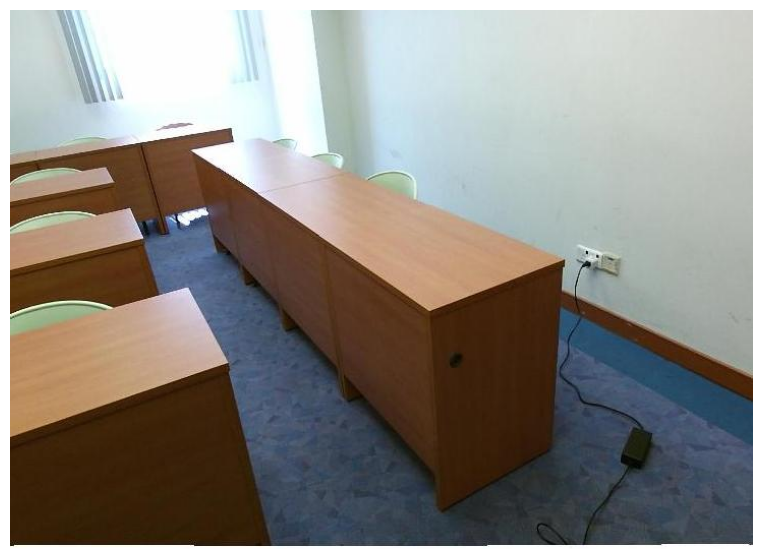

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

imagem = imagens[1000]

img = Image.open(imagem)

print("Arquivo:", imagem)
print("Tamanho:", img.size)

plt.figure(figsize=(10, 7))
plt.imshow(img)
plt.axis("off")
plt.show()

Tamanho: (730, 530)


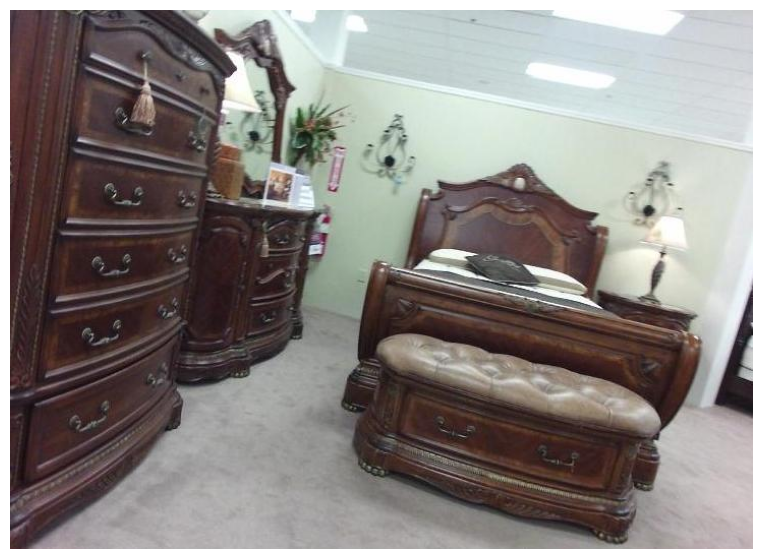

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

imagem = "/content/sunrgbd_test/img-000001.jpg"

img = Image.open(imagem)

print("Tamanho:", img.size)

plt.figure(figsize=(10, 7))
plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
# Vamos organizar as imagens em ordem numérica

import glob
import os
import re

imagens = glob.glob("/content/sunrgbd_test/*.jpg")

def numero_imagem(caminho):
    nome = os.path.basename(caminho)
    numero = re.search(r"img-(\d+)\.jpg", nome)
    return int(numero.group(1))

imagens_ordenadas = sorted(imagens, key=numero_imagem)

print("Total de imagens:", len(imagens_ordenadas))

print("\nPrimeiras 10:")
for img in imagens_ordenadas[:10]:
    print(os.path.basename(img))

print("\nÚltimas 10:")
for img in imagens_ordenadas[-10:]:
    print(os.path.basename(img))

Total de imagens: 5050

Primeiras 10:
img-000001.jpg
img-000002.jpg
img-000003.jpg
img-000004.jpg
img-000005.jpg
img-000006.jpg
img-000007.jpg
img-000008.jpg
img-000009.jpg
img-000010.jpg

Últimas 10:
img-005041.jpg
img-005042.jpg
img-005043.jpg
img-005044.jpg
img-005045.jpg
img-005046.jpg
img-005047.jpg
img-005048.jpg
img-005049.jpg
img-005050.jpg


In [ ]:
# Verificando a estrutura dos registros do .mat

print("Quantidade de registros no .mat:", len(meta))

for i in range(5):
    registro = meta[0, i]

    print(f"\nRegistro {i}:")
    print("RGB:", registro["rgbname"][0])
    print("Sequence:", registro["sequenceName"][0])

Quantidade de registros no .mat: 1

Registro 0:
RGB: 0000103.jpg
Sequence: SUNRGBD/kv2/kinect2data/000002_2014-05-26_14-23-37_260595134347_rgbf000103-resize

Registro 1:
RGB: 0000040.jpg
Sequence: SUNRGBD/kv2/kinect2data/000003_2014-05-26_14-24-42_260595134347_rgbf000040-resize

Registro 2:
RGB: 0000060.jpg
Sequence: SUNRGBD/kv2/kinect2data/000008_2014-05-26_14-30-06_260595134347_rgbf000060-resize

Registro 3:
RGB: 0000034.jpg
Sequence: SUNRGBD/kv2/kinect2data/000009_2014-05-26_14-32-05_260595134347_rgbf000034-resize

Registro 4:
RGB: 0000020.jpg
Sequence: SUNRGBD/kv2/kinect2data/000010_2014-05-26_14-32-36_260595134347_rgbf000020-resize


In [ ]:
import requests

url = "https://raw.githubusercontent.com/ankurhanda/sunrgbd-meta-data/master/sunrgbd_testing_images.txt"

arquivo_mapeamento = "/content/sunrgbd_testing_images.txt"

response = requests.get(url)

if response.status_code == 200:
    with open(arquivo_mapeamento, "wb") as f:
        f.write(response.content)

    print("Arquivo baixado com sucesso!")
else:
    print("Erro no download:", response.status_code)

Arquivo baixado com sucesso!


In [ ]:
with open("/content/sunrgbd_testing_images.txt", "r") as f:
    linhas = [linha.strip() for linha in f.readlines() if linha.strip()]

print("Quantidade de caminhos:", len(linhas))

print("\nPrimeiros 10:")
for linha in linhas[:10]:
    print(linha)

Quantidade de caminhos: 5050

Primeiros 10:
SUNRGBD/kv2/kinect2data/000002_2014-05-26_14-23-37_260595134347_rgbf000103-resize/image/0000103.jpg
SUNRGBD/kv2/kinect2data/000003_2014-05-26_14-24-42_260595134347_rgbf000040-resize/image/0000040.jpg
SUNRGBD/kv2/kinect2data/000008_2014-05-26_14-30-06_260595134347_rgbf000060-resize/image/0000060.jpg
SUNRGBD/kv2/kinect2data/000009_2014-05-26_14-32-05_260595134347_rgbf000034-resize/image/0000034.jpg
SUNRGBD/kv2/kinect2data/000010_2014-05-26_14-32-36_260595134347_rgbf000020-resize/image/0000020.jpg
SUNRGBD/kv2/kinect2data/000011_2014-05-26_14-33-11_260595134347_rgbf000020-resize/image/0000020.jpg
SUNRGBD/kv2/kinect2data/000012_2014-05-26_14-35-37_260595134347_rgbf000180-resize/image/0000180.jpg
SUNRGBD/kv2/kinect2data/000013_2014-05-26_14-36-25_260595134347_rgbf000040-resize/image/0000040.jpg
SUNRGBD/kv2/kinect2data/000014_2014-05-26_14-36-58_260595134347_rgbf000050-resize/image/0000050.jpg
SUNRGBD/kv2/kinect2data/000015_2014-05-26_14-37-33_26059

In [ ]:
# Mostrar algumas linhas do arquivo de teste

for i in range(10):
    print(f"{i+1:04d} -> {linhas[i]}")

0001 -> SUNRGBD/kv2/kinect2data/000002_2014-05-26_14-23-37_260595134347_rgbf000103-resize/image/0000103.jpg
0002 -> SUNRGBD/kv2/kinect2data/000003_2014-05-26_14-24-42_260595134347_rgbf000040-resize/image/0000040.jpg
0003 -> SUNRGBD/kv2/kinect2data/000008_2014-05-26_14-30-06_260595134347_rgbf000060-resize/image/0000060.jpg
0004 -> SUNRGBD/kv2/kinect2data/000009_2014-05-26_14-32-05_260595134347_rgbf000034-resize/image/0000034.jpg
0005 -> SUNRGBD/kv2/kinect2data/000010_2014-05-26_14-32-36_260595134347_rgbf000020-resize/image/0000020.jpg
0006 -> SUNRGBD/kv2/kinect2data/000011_2014-05-26_14-33-11_260595134347_rgbf000020-resize/image/0000020.jpg
0007 -> SUNRGBD/kv2/kinect2data/000012_2014-05-26_14-35-37_260595134347_rgbf000180-resize/image/0000180.jpg
0008 -> SUNRGBD/kv2/kinect2data/000013_2014-05-26_14-36-25_260595134347_rgbf000040-resize/image/0000040.jpg
0009 -> SUNRGBD/kv2/kinect2data/000014_2014-05-26_14-36-58_260595134347_rgbf000050-resize/image/0000050.jpg
0010 -> SUNRGBD/kv2/kinect2d

In [ ]:
# Comparar os nomes RGB do .mat com os caminhos do arquivo de teste

rgb_names_mat = []

for i in range(meta.shape[1]):
    registro = meta[0, i]
    rgb_name = registro["rgbname"][0]
    rgb_names_mat.append(rgb_name)

print("Total de RGBs no .mat:", len(rgb_names_mat))

print("\nPrimeiros RGBs do .mat:")
for nome in rgb_names_mat[:10]:
    print(nome)

Total de RGBs no .mat: 10335

Primeiros RGBs do .mat:
0000103.jpg
0000040.jpg
0000060.jpg
0000034.jpg
0000020.jpg
0000020.jpg
0000180.jpg
0000040.jpg
0000050.jpg
0000020.jpg


In [ ]:
import pandas as pd
import os

# Os 5050 primeiros registros do .mat correspondem ao conjunto de teste
meta_teste = meta[0, :5050]

dados_mapeamento = []

for i, registro in enumerate(meta_teste):

    dados_mapeamento.append({
        "imagem_id": i + 1,
        "arquivo_rgb": f"img-{i+1:06d}.jpg",
        "rgb_name_original": registro["rgbname"][0],
        "sequence_name": registro["sequenceName"][0],
        "rgb_path_original": registro["rgbpath"][0]
    })

df_mapeamento = pd.DataFrame(dados_mapeamento)

print("Total de imagens mapeadas:", len(df_mapeamento))

df_mapeamento.head(10)

Total de imagens mapeadas: 5050


,imagem_id,arquivo_rgb,rgb_name_original,sequence_name,rgb_path_original
0,1,img-000001.jpg,0000103.jpg,SUNRGBD/kv2/kinect2data/000002_2014-05-26_14-2...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...
1,2,img-000002.jpg,0000040.jpg,SUNRGBD/kv2/kinect2data/000003_2014-05-26_14-2...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...
2,3,img-000003.jpg,0000060.jpg,SUNRGBD/kv2/kinect2data/000008_2014-05-26_14-3...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...
3,4,img-000004.jpg,0000034.jpg,SUNRGBD/kv2/kinect2data/000009_2014-05-26_14-3...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00000...
4,5,img-000005.jpg,0000020.jpg,SUNRGBD/kv2/kinect2data/000010_2014-05-26_14-3...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00001...
5,6,img-000006.jpg,0000020.jpg,SUNRGBD/kv2/kinect2data/000011_2014-05-26_14-3...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00001...
6,7,img-000007.jpg,0000180.jpg,SUNRGBD/kv2/kinect2data/000012_2014-05-26_14-3...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00001...
7,8,img-000008.jpg,0000040.jpg,SUNRGBD/kv2/kinect2data/000013_2014-05-26_14-3...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00001...
8,9,img-000009.jpg,0000050.jpg,SUNRGBD/kv2/kinect2data/000014_2014-05-26_14-3...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00001...
9,10,img-000010.jpg,0000020.jpg,SUNRGBD/kv2/kinect2data/000015_2014-05-26_14-3...,/n/fs/sun3d/data/SUNRGBD/kv2/kinect2data/00001...


In [ ]:
# Adiciona o ID da imagem correspondente ao df_sun

df_sun_teste = df_sun.copy()

df_sun_teste["imagem_id"] = df_sun_teste["imagem_id"].astype(int)

df_sun_teste = df_sun_teste[
    df_sun_teste["imagem_id"] <= 5050
].copy()

print("Objetos no conjunto de teste:", len(df_sun_teste))
print("Imagens com objetos:", df_sun_teste["imagem_id"].nunique())

Objetos no conjunto de teste: 38650
Imagens com objetos: 5029


In [ ]:
df_sun_teste[[
    "imagem_id",
    "rgb_name",
    "classe"
]].head(10)

,imagem_id,rgb_name,classe
0,0,0000103.jpg,bed
1,0,0000103.jpg,night_stand
2,0,0000103.jpg,ottoman
3,0,0000103.jpg,dresser_mirror
4,0,0000103.jpg,dresser
5,0,0000103.jpg,lamp
6,0,0000103.jpg,pillow
7,1,0000040.jpg,bed
8,1,0000040.jpg,night_stand
9,1,0000040.jpg,pillow


In [ ]:
# Criar o mapeamento entre o registro do .mat e a imagem baixada

df_mapa = pd.DataFrame({
    "registro_mat": range(5050),
    "arquivo_rgb": [f"img-{i+1:06d}.jpg" for i in range(5050)],
    "rgb_name_original": [
        meta[0, i]["rgbname"][0]
        for i in range(5050)
    ]
})

df_mapa.head(10)

,registro_mat,arquivo_rgb,rgb_name_original
0,0,img-000001.jpg,0000103.jpg
1,1,img-000002.jpg,0000040.jpg
2,2,img-000003.jpg,0000060.jpg
3,3,img-000004.jpg,0000034.jpg
4,4,img-000005.jpg,0000020.jpg
5,5,img-000006.jpg,0000020.jpg
6,6,img-000007.jpg,0000180.jpg
7,7,img-000008.jpg,0000040.jpg
8,8,img-000009.jpg,0000050.jpg
9,9,img-000010.jpg,0000020.jpg


In [ ]:
import pandas as pd

anotacoes = []
imagens_sem_anotacoes = 0

for i in range(5050):

    registro = meta[0, i]

    arquivo_rgb = f"img-{i+1:06d}.jpg"

    # Recupera as bounding boxes
    gt = registro["groundtruth2DBB"]

    # Verifica se existem anotações
    if gt.size == 0:
        imagens_sem_anotacoes += 1
        continue

    objetos = gt[0]

    for objeto in objetos:

        classe = objeto["classname"][0]
        bbox = objeto["gtBb2D"][0]

        anotacoes.append({
            "registro_mat": i,
            "arquivo_rgb": arquivo_rgb,
            "rgb_name_original": registro["rgbname"][0],
            "classe": classe,
            "x": float(bbox[0]),
            "y": float(bbox[1]),
            "largura": float(bbox[2]),
            "altura": float(bbox[3])
        })

df_anotacoes = pd.DataFrame(anotacoes)

print("Total de anotações:", len(df_anotacoes))
print("Total de imagens com anotações:", df_anotacoes["arquivo_rgb"].nunique())
print("Imagens sem anotações:", imagens_sem_anotacoes)

df_anotacoes.head(15)

Total de anotações: 38647
Total de imagens com anotações: 5028
Imagens sem anotações: 22


,registro_mat,arquivo_rgb,rgb_name_original,classe,x,y,largura,altura
0,0,img-000001.jpg,0000103.jpg,bed,328.000000,152.000000,346.000000,320.000000
1,0,img-000001.jpg,0000103.jpg,night_stand,572.541806,275.635452,98.377926,53.177258
2,0,img-000001.jpg,0000103.jpg,ottoman,332.357860,318.177258,316.404682,209.163880
3,0,img-000001.jpg,0000103.jpg,dresser_mirror,157.759197,10.635452,156.872910,362.491639
4,0,img-000001.jpg,0000103.jpg,dresser,1.000000,1.000000,221.000000,529.000000
5,0,img-000001.jpg,0000103.jpg,lamp,614.197324,200.301003,54.949833,93.946488
6,0,img-000001.jpg,0000103.jpg,pillow,414.487179,230.434783,153.262108,48.154961
7,1,img-000002.jpg,0000040.jpg,bed,1.000000,128.000000,498.000000,402.000000
8,1,img-000002.jpg,0000040.jpg,night_stand,462.000000,303.000000,197.000000,195.000000
9,1,img-000002.jpg,0000040.jpg,pillow,338.931814,254.420611,130.430686,72.563460


In [ ]:
# Encontrar imagens que possuem chair + table

classes_por_imagem = (
    df_anotacoes.groupby("arquivo_rgb")["classe"]
    .apply(set)
)

imagens_chair_table = classes_por_imagem[
    classes_por_imagem.apply(
        lambda x: {"chair", "table"}.issubset(x)
    )
]

print("Imagens com chair + table:", len(imagens_chair_table))

print("\nPrimeiras 10:")
for imagem in imagens_chair_table.index[:10]:
    print(imagem)

Imagens com chair + table: 1478

Primeiras 10:
img-000048.jpg
img-000049.jpg
img-000051.jpg
img-000052.jpg
img-000053.jpg
img-000055.jpg
img-000059.jpg
img-000060.jpg
img-000061.jpg
img-000077.jpg


In [ ]:
# Selecionar a primeira imagem encontrada

arquivo_selecionado = imagens_chair_table.index[0]

print("Imagem selecionada:", arquivo_selecionado)

df_imagem = df_anotacoes[
    df_anotacoes["arquivo_rgb"] == arquivo_selecionado
].copy()

print("\nObjetos encontrados:")
print(df_imagem[["classe", "x", "y", "largura", "altura"]].to_string(index=False))

Imagem selecionada: img-000048.jpg

Objetos encontrados:
  classe          x          y    largura     altura
     bed   1.000000 194.096990 426.190635 337.675585
   chair 502.525084 243.729097 226.003344 274.749164
   table 563.678930 178.143813 167.508361 129.856187
computer 616.000000  63.812709 115.187291 106.354515
  pillow 262.341137 192.324415 148.896321  43.428094


Tamanho da imagem: (730, 530)


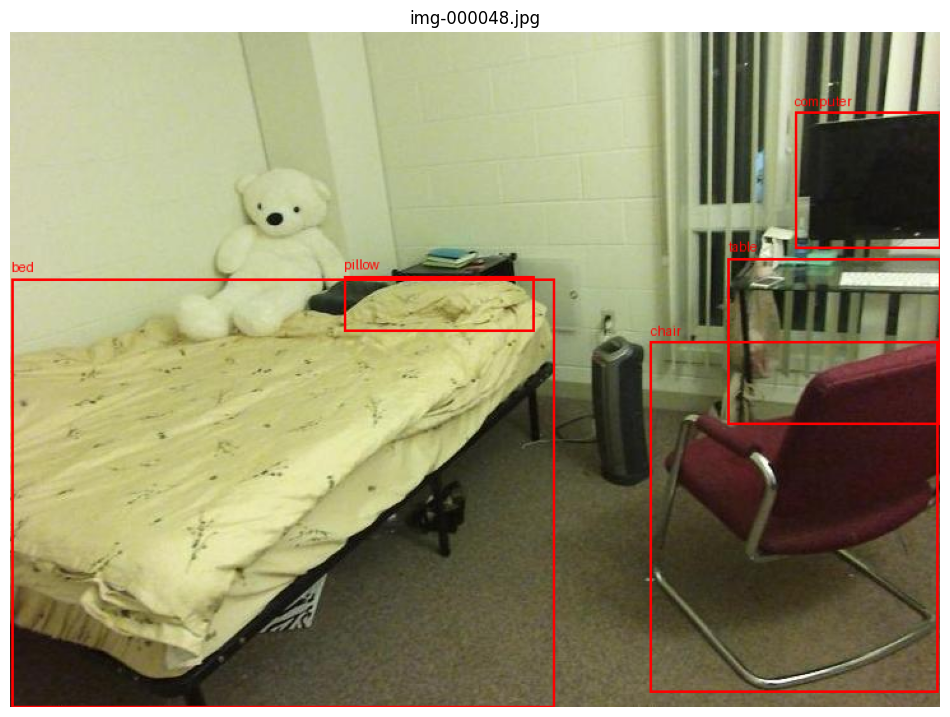

In [ ]:
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import os

# Caminho da imagem
caminho_imagem = os.path.join(
    "/content/sunrgbd_test",
    arquivo_selecionado
)

# Abrir imagem
imagem = Image.open(caminho_imagem).convert("RGB")

print("Tamanho da imagem:", imagem.size)

# Criar objeto para desenho
imagem_anotada = imagem.copy()
draw = ImageDraw.Draw(imagem_anotada)

# Desenhar cada bounding box
for _, obj in df_imagem.iterrows():

    x = obj["x"]
    y = obj["y"]
    largura = obj["largura"]
    altura = obj["altura"]

    x2 = x + largura
    y2 = y + altura

    # Ajustar aos limites da imagem
    x = max(0, x)
    y = max(0, y)
    x2 = min(imagem.width, x2)
    y2 = min(imagem.height, y2)

    # Ignorar caixas sem área válida
    if x2 <= x or y2 <= y:
        continue

    # Caixa
    draw.rectangle(
        [x, y, x2, y2],
        outline="red",
        width=2
    )

    # Nome da classe
    texto = obj["classe"]

    draw.text(
        (x, max(0, y - 15)),
        texto,
        fill="red"
    )

# Mostrar
plt.figure(figsize=(12, 9))
plt.imshow(imagem_anotada)
plt.axis("off")
plt.title(arquivo_selecionado)
plt.show()

In [ ]:
classes_obstaculo = [
    "bed", "chair", "sofa", "sofa_chair", "table",
    "coffee_table", "endtable", "desk", "cabinet",
    "shelf", "bookshelf", "dresser", "drawer",
    "night_stand", "ottoman", "stool", "bench",
    "box", "garbage_bin", "recycle_bin", "door",
    "fridge", "sink", "toilet", "cart", "bicycle",
    "baby_stroller", "clothes_rack", "coat_rack",
    "plant", "bag"
]

In [ ]:
df_anotacoes_obstaculos = df_anotacoes[
    df_anotacoes["classe"].isin(classes_obstaculo)
].copy()

print("Total de anotações relevantes:", len(df_anotacoes_obstaculos))
print(
    "Total de imagens com pelo menos uma classe relevante:",
    df_anotacoes_obstaculos["arquivo_rgb"].nunique()
)

Total de anotações relevantes: 27201
Total de imagens com pelo menos uma classe relevante: 4898


In [ ]:
pares_interesse = [
    ("chair", "table"),
    ("chair", "desk"),
    ("chair", "door"),
    ("cabinet", "chair"),
    ("bed", "night_stand"),
    ("chair", "sofa")
]

imagens_selecionadas = []

for classe1, classe2 in pares_interesse:

    classes_por_imagem = (
        df_anotacoes_obstaculos
        .groupby("arquivo_rgb")["classe"]
        .apply(set)
    )

    candidatas = classes_por_imagem[
        classes_por_imagem.apply(
            lambda x: {classe1, classe2}.issubset(x)
        )
    ]

    if len(candidatas) > 0:
        imagem = candidatas.index[0]
        imagens_selecionadas.append(
            (imagem, f"{classe1} + {classe2}")
        )

print("Imagens selecionadas:")

for imagem, par in imagens_selecionadas:
    print(f"{par}: {imagem}")

Imagens selecionadas:
chair + table: img-000048.jpg
chair + desk: img-000065.jpg
chair + door: img-000081.jpg
cabinet + chair: img-000126.jpg
bed + night_stand: img-000001.jpg
chair + sofa: img-000061.jpg


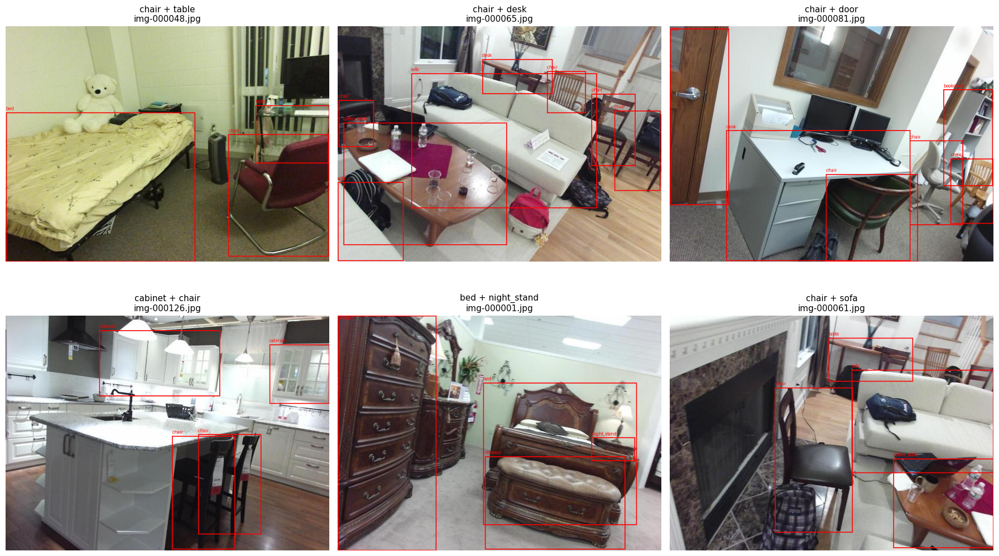

In [ ]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import os

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 11)
)

for ax, (arquivo, par) in zip(axes.flatten(), imagens_selecionadas):

    caminho = os.path.join(
        "/content/sunrgbd_test",
        arquivo
    )

    imagem = Image.open(caminho).convert("RGB")
    draw = ImageDraw.Draw(imagem)

    df_img = df_anotacoes_obstaculos[
        df_anotacoes_obstaculos["arquivo_rgb"] == arquivo
    ]

    for _, obj in df_img.iterrows():

        x = obj["x"]
        y = obj["y"]
        x2 = x + obj["largura"]
        y2 = y + obj["altura"]

        # Ajustar aos limites da imagem
        x = max(0, x)
        y = max(0, y)
        x2 = min(imagem.width, x2)
        y2 = min(imagem.height, y2)

        if x2 <= x or y2 <= y:
            continue

        # Bounding box
        draw.rectangle(
            [x, y, x2, y2],
            outline="red",
            width=2
        )

        # Classe
        draw.text(
            (x, max(0, y - 15)),
            obj["classe"],
            fill="red"
        )

    ax.imshow(imagem)
    ax.set_title(
        f"{par}\n{arquivo}",
        fontsize=11
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Classes potencialmente relacionadas a obstáculos
classes_obstaculo = [
    "bed", "chair", "sofa", "sofa_chair", "table", "coffee_table",
    "endtable", "desk", "cabinet", "shelf", "bookshelf", "dresser",
    "drawer", "night_stand", "ottoman", "stool", "bench", "box",
    "garbage_bin", "recycle_bin", "door", "fridge", "sink", "toilet",
    "cart", "bicycle", "baby_stroller", "clothes_rack", "coat_rack",
    "plant", "bag"
]

# Filtrar apenas essas classes
df_classes = df_anotacoes[
    df_anotacoes["classe"].isin(classes_obstaculo)
].copy()

# Estatísticas por classe
analise_classes = (
    df_classes
    .groupby("classe")
    .agg(
        objetos=("classe", "count"),
        imagens=("arquivo_rgb", "nunique")
    )
    .reset_index()
)

# Percentual das ocorrências
analise_classes["percentual_objetos"] = (
    analise_classes["objetos"] /
    analise_classes["objetos"].sum() * 100
)

# Ordenar pela quantidade de imagens
analise_classes = analise_classes.sort_values(
    "imagens",
    ascending=False
).reset_index(drop=True)

analise_classes

,classe,objetos,imagens,percentual_objetos
0,chair,12303,2806,45.229955
1,table,3083,1854,11.334142
2,desk,2432,1019,8.940848
3,door,790,669,2.904305
4,cabinet,817,651,3.003566
5,sofa,799,575,2.937392
6,bed,598,532,2.198449
7,garbage_bin,627,519,2.305062
8,shelf,714,505,2.624903
9,box,763,431,2.805044


In [ ]:
def classificar_disponibilidade(imagens):
    if imagens < 20:
        return "Muito baixa"
    elif imagens < 100:
        return "Baixa"
    elif imagens < 500:
        return "Moderada"
    elif imagens < 1000:
        return "Boa"
    else:
        return "Alta"

analise_classes["disponibilidade"] = (
    analise_classes["imagens"]
    .apply(classificar_disponibilidade)
)

analise_classes

,classe,objetos,imagens,percentual_objetos,disponibilidade
0,chair,12303,2806,45.229955,Alta
1,table,3083,1854,11.334142,Alta
2,desk,2432,1019,8.940848,Alta
3,door,790,669,2.904305,Boa
4,cabinet,817,651,3.003566,Boa
5,sofa,799,575,2.937392,Boa
6,bed,598,532,2.198449,Boa
7,garbage_bin,627,519,2.305062,Boa
8,shelf,714,505,2.624903,Boa
9,box,763,431,2.805044,Moderada


In [ ]:
print("Total de classes analisadas:", len(analise_classes))
print()

print(
    analise_classes[
        ["classe", "objetos", "imagens", "percentual_objetos", "disponibilidade"]
    ].to_string(index=False)
)

Total de classes analisadas: 30

      classe  objetos  imagens  percentual_objetos disponibilidade
       chair    12303     2806           45.229955            Alta
       table     3083     1854           11.334142            Alta
        desk     2432     1019            8.940848            Alta
        door      790      669            2.904305             Boa
     cabinet      817      651            3.003566             Boa
        sofa      799      575            2.937392             Boa
         bed      598      532            2.198449             Boa
 garbage_bin      627      519            2.305062             Boa
       shelf      714      505            2.624903             Boa
         box      763      431            2.805044        Moderada
  sofa_chair      765      384            2.812397        Moderada
        sink      402      334            1.477887        Moderada
   bookshelf      413      297            1.518327        Moderada
    endtable      392      29

| Critério                            | HomeObjects-3K   | SUN RGB-D                          | Melhor             |
| ----------------------------------- | ---------------- | ---------------------------------- | ------------------ |
| Ambientes internos                  | ✅                | ✅                                  | Empate             |
| Objetos relacionados à mobilidade   | ✅                | ✅                                  | **SUN RGB-D**      |
| Quantidade de imagens               | 2.689            | 10.335                             | **SUN RGB-D**      |
| Variedade de ambientes/objetos      | 12 classes       | ~1.066 classes após limpeza        | **SUN RGB-D**      |
| Quantidade de objetos relevantes    | ~19 mil          | ~55 mil no recorte inicial         | **SUN RGB-D**      |
| Diversidade de sensores/cenas       | Menor            | 4 sensores, 464?*                  | **SUN RGB-D**      |
| Bounding boxes 2D                   | ✅                | ✅                                  | Empate             |
| Qualidade estrutural das anotações  | Muito boa        | Boa, com necessidade de tratamento | **HomeObjects-3K** |
| Equilíbrio entre classes            | ⚠️ Desbalanceado | ⚠️ Muito desbalanceado             | **HomeObjects-3K** |
| Objetos pequenos                    | 67,7%            | 43,6%                              | **SUN RGB-D**      |
| Objetos médios/grandes              | 32,3%            | 56,4%                              | **SUN RGB-D**      |
| Contexto realista de ambientes      | Bom              | **Muito bom**                      | **SUN RGB-D**      |
| Adequação ao objetivo do TCC        | Boa              | **Muito boa**                      | **SUN RGB-D**      |
| Trabalho necessário para preparação | Menor            | Maior                              | **HomeObjects-3K** |


# Comparação entre as bases de dados


Após a realização da análise exploratória das bases **HomeObjects-3K**, **SUN RGB-D** e **NYU Depth V2**, foi realizada uma comparação considerando critérios relacionados à quantidade de imagens, disponibilidade de objetos relevantes para mobilidade em ambientes internos, distribuição das classes, tamanho das bounding boxes, ocorrência conjunta de objetos, qualidade das anotações e disponibilidade de informações de profundidade.

| Critério                              | HomeObjects-3K |      SUN RGB-D | NYU Depth V2 |
| ------------------------------------- | -------------: | -------------: | -----------: |
| Imagens                               |          2.689 |         10.335 |        1.449 |
| Classes totais                        |             12 |          1.066 |          894 |
| oooMédia de objetos relevantes/imagem |           5,35 |           5,49 |         6,64 |
| Mediana de objetos relevantes/imagem  |              4 |              4 |            6 |
| Máximo de objetos relevantes/imagem   |             48 |             49 |           37 |
| Objetos médios/grandes                |         32,30% |     **56,40%** |       41,22% |
| Diversidade de classes                |          Baixa | **Muito alta** |         Alta |
| Coocorrência entre objetos            |       21 pares |  **372 pares** |    265 pares |
| Informação de profundidade            |            Não |            Sim |          Sim |
| Complexidade de preparação            |          Baixa |           Alta |         Alta |

### HomeObjects-3K

A **HomeObjects-3K** apresentou uma estrutura relativamente simples e organizada, contendo 2.689 imagens distribuídas entre 12 classes. A análise demonstrou boa qualidade das anotações, sem registros vazios ou bounding boxes inválidas.

A base possui objetos diretamente relacionados a ambientes internos, como **cadeiras, mesas, sofás, camas, portas, guarda-roupas e plantas**. Entretanto, foi identificada uma distribuição bastante desigual entre as classes, com destaque para a classe *potted plant*, que representa aproximadamente 22,6% das instâncias, enquanto classes como *bed* e *laptop* apresentam quantidade bastante reduzida.

Outro ponto observado foi a predominância de objetos pequenos: aproximadamente **67,70% das bounding boxes ocupam menos de 5% da área da imagem**. Apenas 32,30% das instâncias foram classificadas como médias ou grandes segundo os limiares exploratórios adotados.

Apesar dessas limitações, a base apresentou cenas com combinações realistas de objetos, principalmente envolvendo mesas, cadeiras, sofás e plantas. Dessa forma, mostrou-se adequada para experimentos iniciais de detecção de objetos em ambientes internos, principalmente devido à sua estrutura simples e às anotações consistentes.

### SUN RGB-D

A **SUN RGB-D** apresentou a maior quantidade e diversidade de dados entre as três bases analisadas. O conjunto possui **10.335 imagens**, além de uma grande variedade de categorias de objetos presentes em ambientes internos.

Após a definição de um conjunto de classes potencialmente relacionadas à mobilidade, foram identificadas **54.970 instâncias de objetos relevantes**, distribuídas em 31 classes. A média foi de aproximadamente **5,49 objetos relevantes por imagem**, com mediana de 4 e máximo de 49 objetos em uma única imagem.

A análise do tamanho das bounding boxes apresentou um resultado particularmente interessante: **56,40% dos objetos relevantes foram classificados como médios ou grandes**, percentual superior ao observado nas demais bases. Isso indica uma quantidade maior de objetos representados com dimensões potencialmente mais favoráveis para a detecção visual.

Também foi observada uma elevada variedade de combinações entre objetos, com **372 pares de coocorrência**. Entre os exemplos mais frequentes estão *chair + table*, *chair + desk*, *chair + door* e *sofa + table*. Esse comportamento demonstra que a base contém diferentes configurações de ambientes internos, contribuindo para uma maior diversidade de cenários de treinamento.

A principal limitação identificada está na complexidade de preparação dos dados. Foram encontradas algumas bounding boxes que ultrapassavam os limites das imagens, sendo necessária a aplicação de procedimentos de validação e recorte das coordenadas. Além disso, a grande quantidade de classes exige uma etapa adicional de seleção e padronização das categorias antes do treinamento.

Mesmo com essas limitações, a SUN RGB-D apresentou o conjunto mais favorável para a continuidade da pesquisa, principalmente pela quantidade de imagens, diversidade de ambientes e objetos e maior proporção de objetos médios e grandes.

### NYU Depth V2

A **NYU Depth V2** apresentou características distintas das demais bases. Embora possua apenas **1.449 imagens RGB-D densamente rotuladas**, essas imagens apresentam uma grande quantidade e diversidade de objetos, totalizando **894 classes identificadas nas anotações originais**.

Após a seleção das categorias potencialmente relacionadas à mobilidade e a remoção de classes com quantidade muito reduzida de instâncias, foram consideradas **9.442 instâncias de objetos relevantes**, distribuídas entre as classes com pelo menos 30 ocorrências. Praticamente todas as imagens da base possuem pelo menos um objeto relevante, correspondendo a aproximadamente **99,2% das imagens**.

A média foi de **6,64 objetos relevantes por imagem**, com mediana de 6. Quanto ao tamanho das bounding boxes, 41,22% das instâncias foram classificadas como médias ou grandes, resultado intermediário entre HomeObjects-3K e SUN RGB-D.

Um dos principais diferenciais da NYU Depth V2 é a disponibilidade de **informação de profundidade associada às imagens RGB**. Essa característica permite analisar não apenas a aparência e localização dos objetos, mas também sua profundidade em relação ao sensor. Na análise realizada, por exemplo, classes como *bed*, *toilet*, *sink* e *desk* apresentaram diferentes distribuições de profundidade, demonstrando o potencial dessa informação para análises futuras relacionadas à proximidade dos objetos.

Além disso, a reconstrução das anotações permitiu identificar objetos individualmente por meio da combinação entre **classe e número da instância**, possibilitando a geração das respectivas bounding boxes.

A principal limitação da NYU Depth V2 para o projeto é a quantidade relativamente pequena de imagens densamente rotuladas quando comparada à SUN RGB-D. Além disso, sua estrutura exige uma etapa de processamento mais complexa para transformar as máscaras de classe e instância em bounding boxes adequadas ao treinamento de modelos de detecção.

### Comparação geral

De maneira geral, as três bases apresentaram características relevantes para o desenvolvimento do projeto, porém com diferentes vantagens.

A **HomeObjects-3K** destacou-se pela simplicidade, organização e qualidade das anotações, sendo a alternativa mais fácil de preparar e utilizar. Entretanto, apresentou menor diversidade e maior concentração de objetos pequenos.

A **NYU Depth V2** apresentou grande potencial para análises mais aprofundadas devido à disponibilidade de imagens RGB-D, máscaras de classe e instância e informações de profundidade. Entretanto, a quantidade de imagens densamente rotuladas é menor e sua preparação para detecção de objetos é mais complexa.

A **SUN RGB-D**, por sua vez, apresentou o melhor equilíbrio entre quantidade de imagens, diversidade de objetos, variedade de ambientes, coocorrência entre classes e proporção de objetos médios e grandes. Esses fatores são particularmente relevantes para o objetivo deste projeto, que busca investigar a detecção de objetos potencialmente relacionados a obstáculos durante a mobilidade em ambientes internos.

Dessa forma, **a SUN RGB-D foi selecionada como a base mais promissora para a continuidade da POC e para os experimentos de detecção de objetos**, sem descartar as demais bases como referências para comparação ou possíveis experimentos futuros.

> **Observação:** os percentuais de tamanho dos objetos foram calculados utilizando limiares exploratórios de 5% e 20% da área total da imagem. Esses valores foram utilizados exclusivamente para padronizar a comparação entre as bases e não representam uma classificação universal de tamanho de objetos.
